<a href="https://colab.research.google.com/github/mmm10138/Machine-Learning/blob/main/HW_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Scientific Machine Learning - Homework 2**

# Part 1: DGM for ODE

We are going to solve an ODE for the logistic growth model.

The logistic growth model is a widely used differential equation in population dynamics, describing the growth of a population with limited resources. The rate of change of the population $y(t)$ at time $t$ is given by:

$$
\frac{dy}{dt} = r y (M - y),
$$

where:
- $y(t)$ is the population at time $t$,
- $r$ is the intrinsic growth rate of the population,
- $M$ is the carrying capacity, i.e., the maximum population that the environment can sustain.

The logistic growth model assumes that the population grows exponentially when it is small but the growth rate decreases as the population approaches the carrying capacity $M$ due to resource limitations.

The solution to the logistic growth model with the initial condition $y(0) = y_0$ is:

$$
y(t) = \frac{M}{1 + A \exp(- r M t)},
$$

where:

$$
A = \frac{M - y_0}{y_0}.
$$

This solution describes a sigmoid curve where the population grows rapidly at first, then slows down, and eventually stabilizes at the carrying capacity $M$.


## First version

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

In [16]:
# Setting the seed for reproducibility
import random
def set_seed(seed_value):
    # Python random
    random.seed(seed_value)

    # NumPy random
    np.random.seed(seed_value)

    # PyTorch random
    torch.manual_seed(seed_value)

    # For GPU (if using CUDA)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed_value)
        torch.cuda.manual_seed_all(seed_value)

    # Ensure deterministic behavior
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [17]:
# Define the Neural Network model
class NeuralNet(nn.Module):
    def __init__(self):
        super(NeuralNet, self).__init__()
        self.fc1 = nn.Linear(1,200) #linear 1 -> 200
        self.fc2 = nn.Linear(200,200)#linear 200 -> 200
        self.fc3 = nn.Linear(200,1) #linear 200 -> 1

        # Initialize weights with N(0,0.05^2) and biases as 0
        for layer in (self.fc1, self.fc2, self.fc3):
          nn.init.normal_(layer.weight, mean=0.0, std=0.05)
          nn.init.zeros_(layer.bias)

    def forward(self, t):
        x = torch.sigmoid(self.fc1(t)) #first layer with sigmoid
        x = torch.sigmoid(self.fc2(x)) #second layer with sigmoid
        x = (M+2)*torch.sigmoid(self.fc3(x))-1 #third layer such that the output is in [-1, M+1]
        #Sigmoid bounds the outputs in (0,1), scaling by M+2 and subtracting 1 puts it in (-1,M+1)
        return x

In [18]:
# Define the true solution of the logistic growth ODE
def true_solution(t, M, r, y0):
    A = (M - y0) / y0
    return M / (1 + A * torch.exp(-r * M * t))

In [19]:
# Define the loss function for the ODE residual
def ode_loss(model, t_batch, M, r):
    t_batch.requires_grad_(True)
    y_pred = model(t_batch)

    # Compute dy/dt using autograd
    dy_dt = torch.autograd.grad(y_pred, t_batch, grad_outputs=torch.ones_like(y_pred), create_graph=True)[0]

    # Residual of the ODE: dy/dt = r * y * (M - y)
    residual = dy_dt - r * y_pred * (M - y_pred)

    # MSE loss for the ODE residual
    loss_ode = torch.mean(residual ** 2)

    return loss_ode

# Define the loss for the initial condition y(0) = y0
def initial_condition_loss(model, y0):
    y0_pred = model(torch.tensor([0.0]))
    loss_ic = torch.mean((y0_pred - y0) ** 2)
    return loss_ic

In [20]:
# Updated train_ode_solver function with parameters passed as inputs
def train_ode_solver(M, r, y0, T, model, optimizer, num_epochs, batch_size, learning_rate, eval_every, w_ic):
    # Create a testing set of 100 points sampled uniformly from [0, T]
    t_test = torch.linspace(0, T, 100).unsqueeze(1)
    y_test_true = true_solution(t_test, M, r, y0).detach()

    # Lists to store losses
    train_losses = []
    test_losss = []

    # Training loop
    for epoch in range(num_epochs):
        model.train()

        # Sample minibatch of time points uniformly in [0, T]
        t_batch = T * torch.rand(batch_size, 1)

        # Compute the total loss: ODE residual loss + initial condition loss
        loss_ode = ode_loss(model, t_batch, M, r)
        loss_ic = initial_condition_loss(model, y0)
        loss = loss_ode + w_ic * loss_ic

        # Backpropagation and optimizer step
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Record train loss
        train_losses.append(loss.item())

        # Evaluate the model on the testing set every 'eval_every' epochs
        if epoch % eval_every == 0:
            model.eval()
            with torch.no_grad():
                y_test_pred = model(t_test)
                test_loss = torch.mean((y_test_pred - y_test_true) ** 2)
                test_losss.append(test_loss.item())
                print(f'Epoch {epoch}, Test Loss: {test_loss.item()}')

                # Plot the true solution and the learned solution by the NN
                plt.figure(figsize=(8, 6))
                plt.plot(t_test.numpy(), y_test_true.numpy(), 'r--', label="True Solution")
                plt.plot(t_test.numpy(), y_test_pred.numpy(), 'b-', label="Learned Solution (NN)")
                plt.legend()
                plt.xlabel("t")
                plt.ylabel("y(t)")
                plt.title(f"Epoch {epoch}")
                plt.show()

    # Plot train and test losses
    plt.figure(figsize=(8, 6))
    plt.semilogy(np.arange(num_epochs), train_losses, label='Train Loss')
    plt.semilogy(np.arange(0, num_epochs, eval_every), test_losss, label='Test Loss', color='red')
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Train Loss and Test Loss Over Epochs")
    plt.legend()
    plt.show()

Next, we define the model parameters.

In [21]:
# Parameters: Model parameters and algorithm hyperparameters
M = 6.0  # Carrying capacity
r = 0.30  # Growth rate
y0 = 2.0  # Initial condition
T = 1.5   # Time horizon

Then, we define the algorithm's hyperparameters.

In [22]:
# Hyperparameters: for deep learning algorithm
num_epochs = 2000  # Number of training epochs
batch_size = 32    # Minibatch size for training
learning_rate = 0.001  # Learning rate for optimizer
eval_every = 50     # Frequency of evaluation (number of epochs)
w_ic = 10 # Weight for initial condition
# Note: the number of layers, the number of neurons per layers, and the
# activation functions are also hyperparameters.

We run the training loop.

Epoch 0, Test Loss: 2.7512331008911133


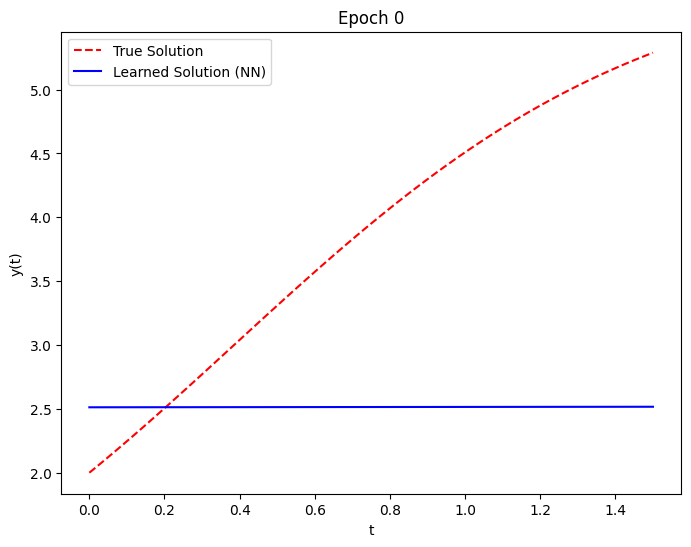

Epoch 50, Test Loss: 4.686833381652832


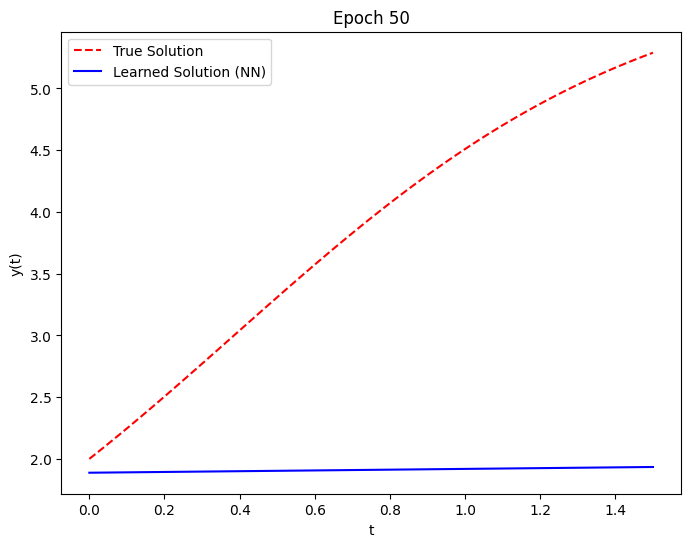

Epoch 100, Test Loss: 4.669940948486328


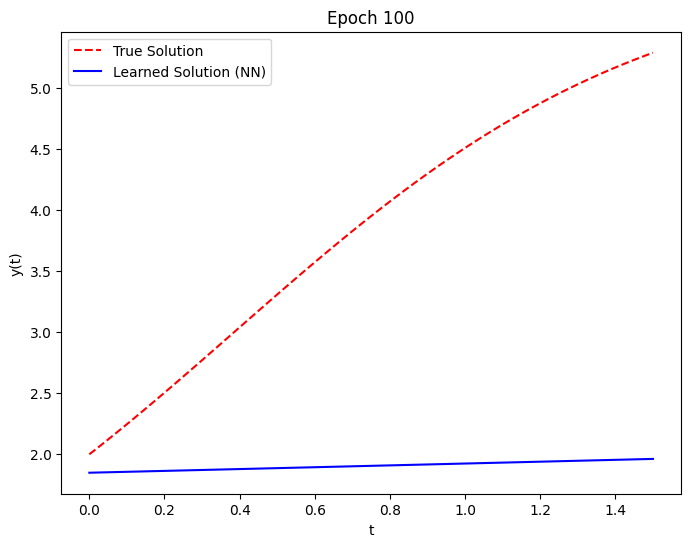

Epoch 150, Test Loss: 4.2279372215271


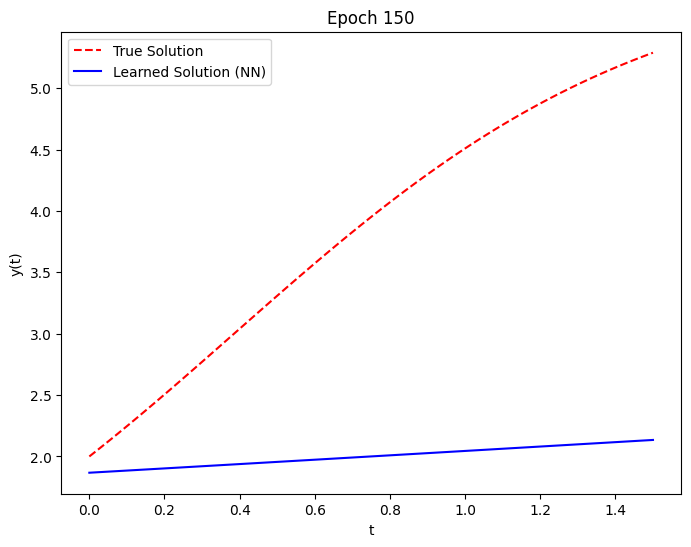

Epoch 200, Test Loss: 3.126284122467041


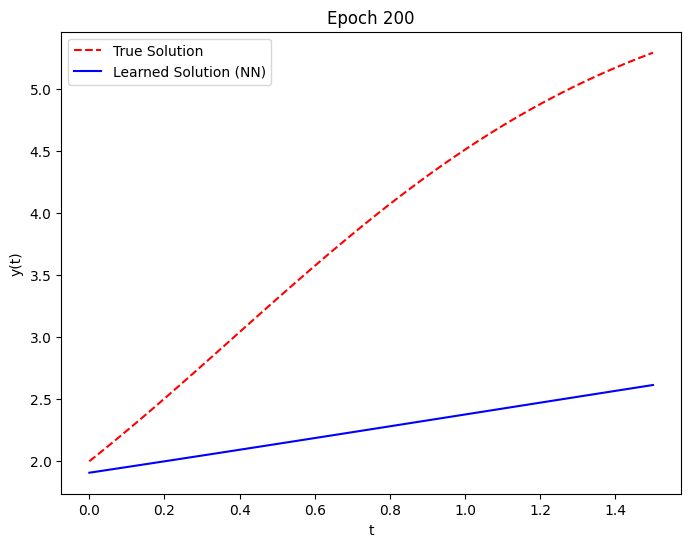

Epoch 250, Test Loss: 0.6221829056739807


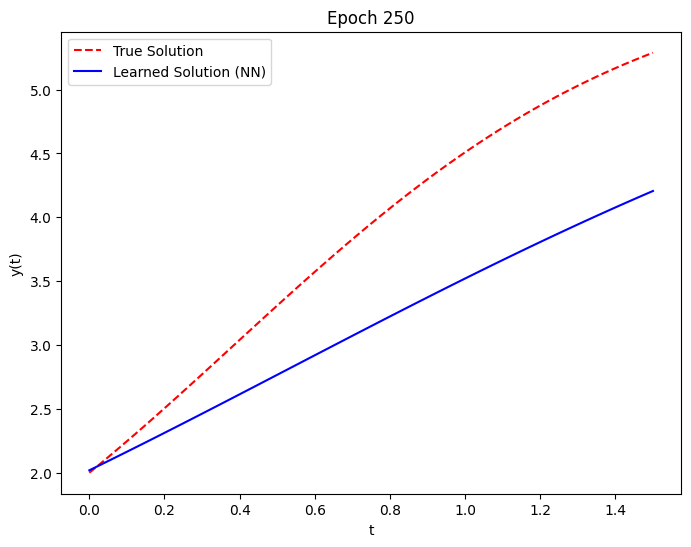

Epoch 300, Test Loss: 0.0009130741818808019


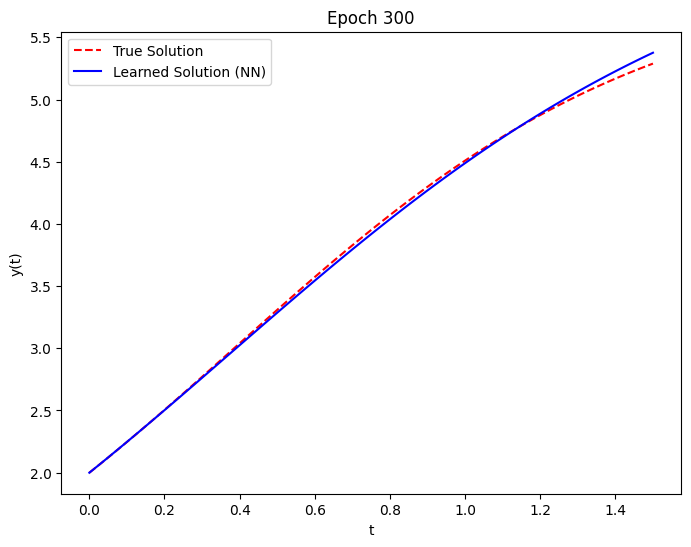

Epoch 350, Test Loss: 0.003476981306448579


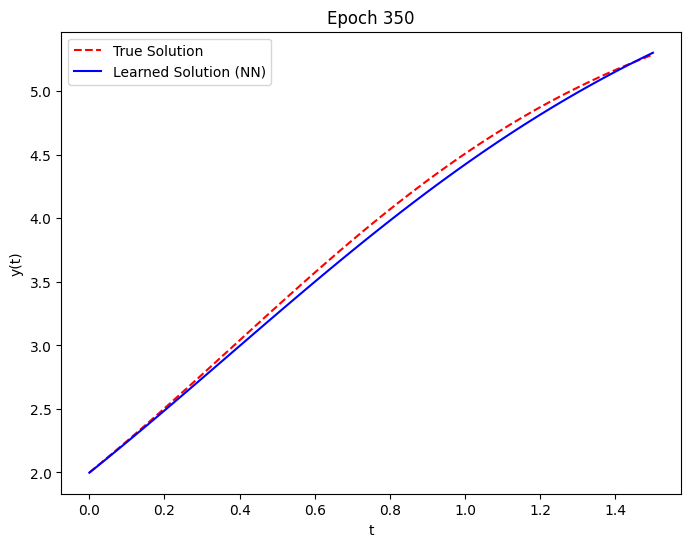

Epoch 400, Test Loss: 0.002322182757779956


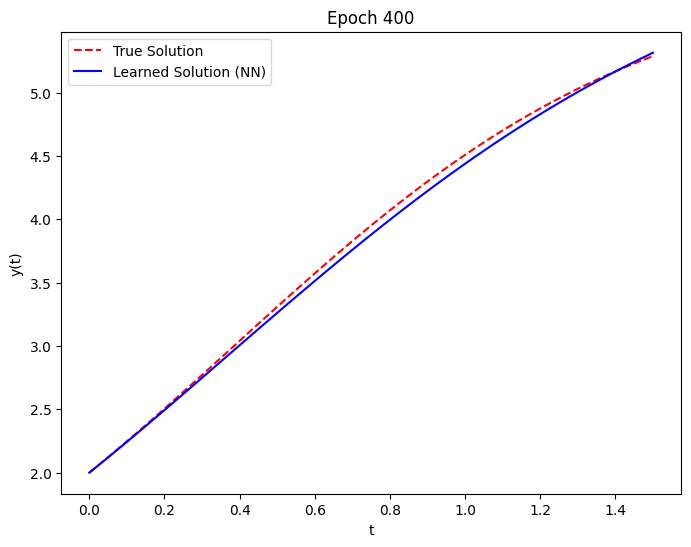

Epoch 450, Test Loss: 0.002442131517454982


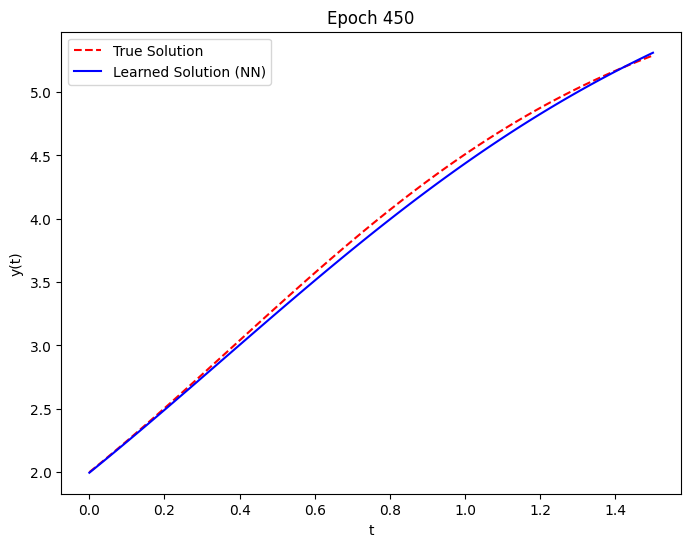

Epoch 500, Test Loss: 0.0024875488597899675


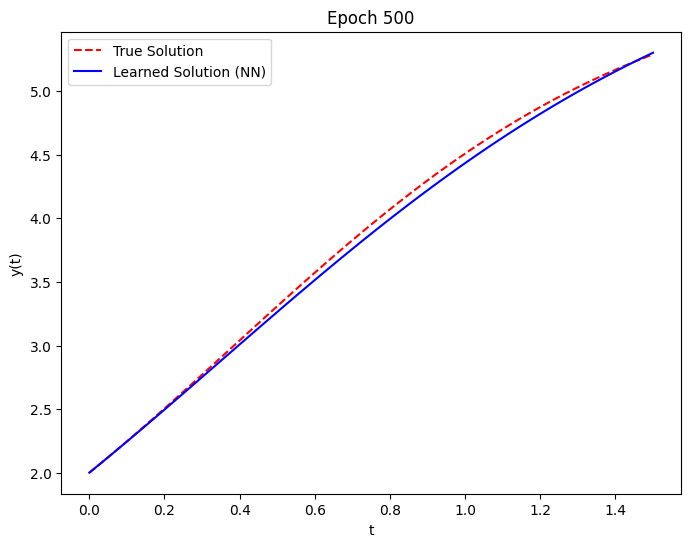

Epoch 550, Test Loss: 0.0020827914122492075


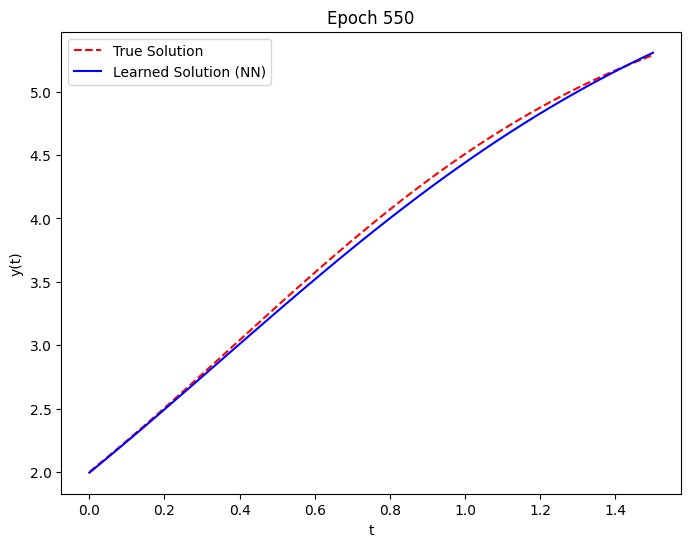

Epoch 600, Test Loss: 0.0015327088767662644


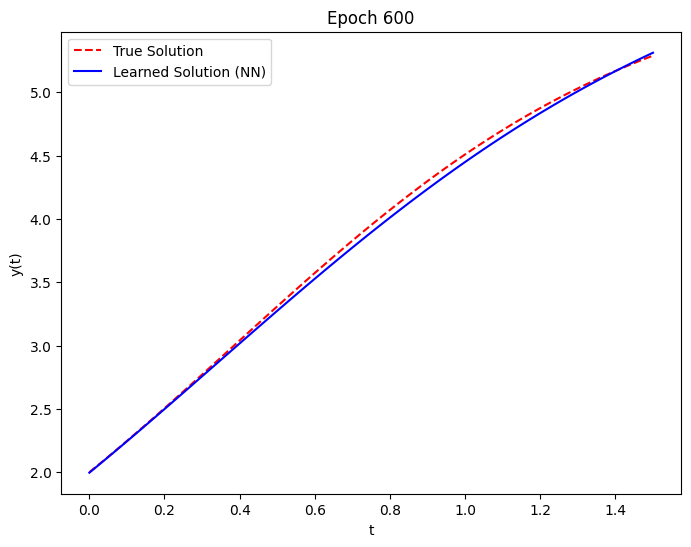

Epoch 650, Test Loss: 0.0014120483538135886


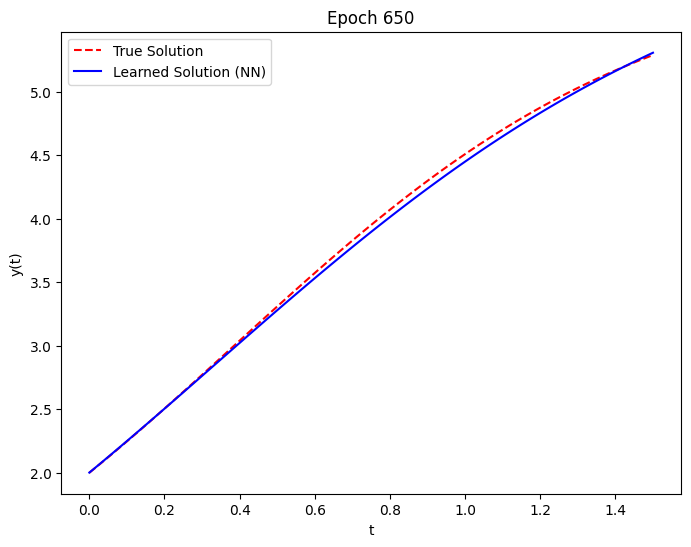

Epoch 700, Test Loss: 0.0011029524030163884


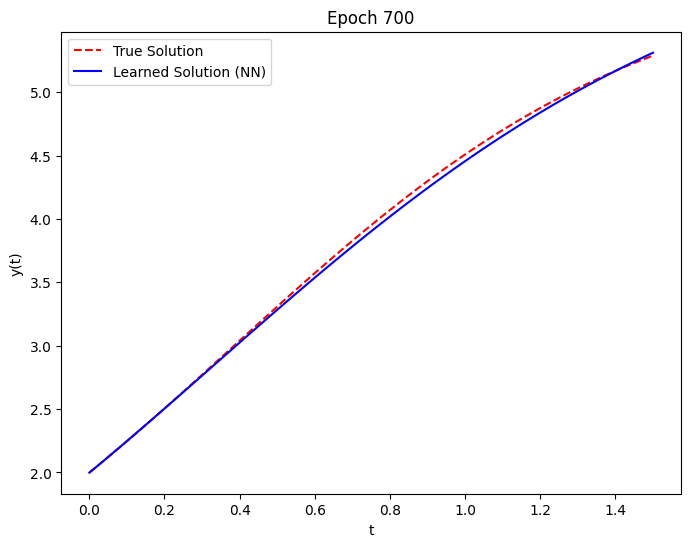

Epoch 750, Test Loss: 0.0010821770410984755


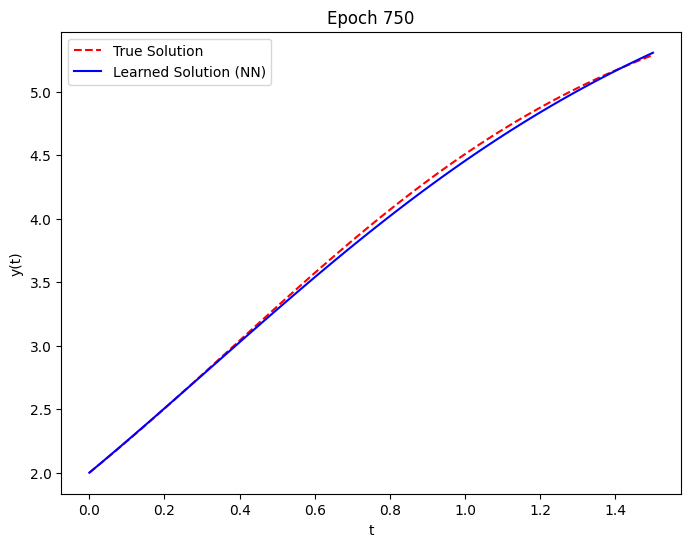

Epoch 800, Test Loss: 0.0010306874755769968


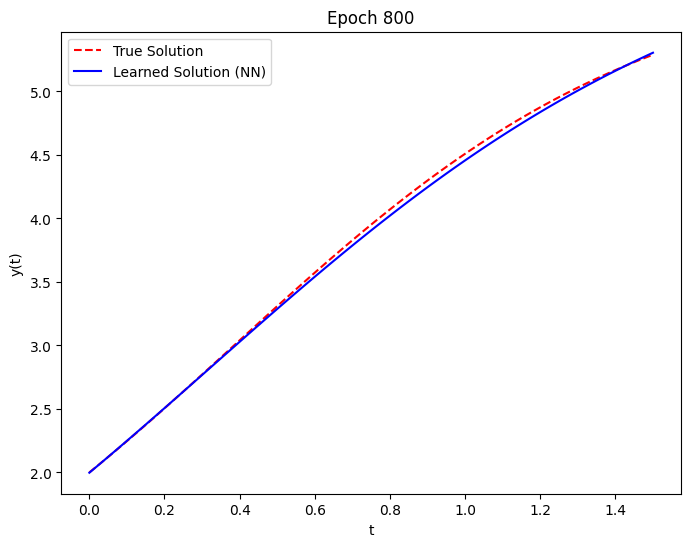

Epoch 850, Test Loss: 0.0008206875645555556


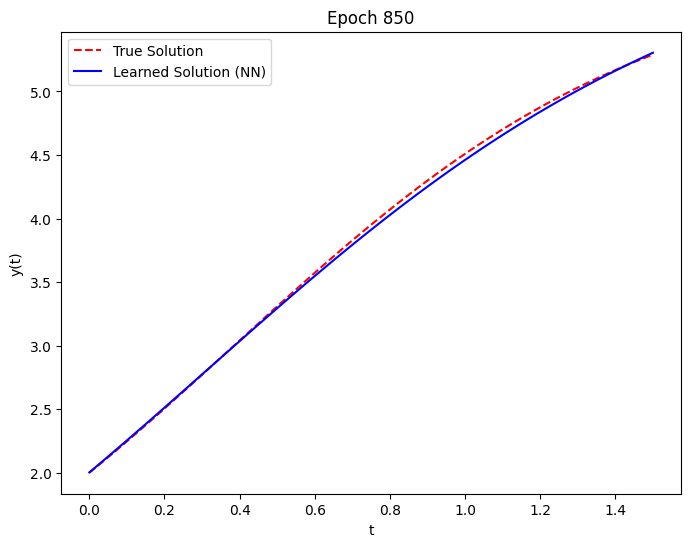

Epoch 900, Test Loss: 0.000599742284975946


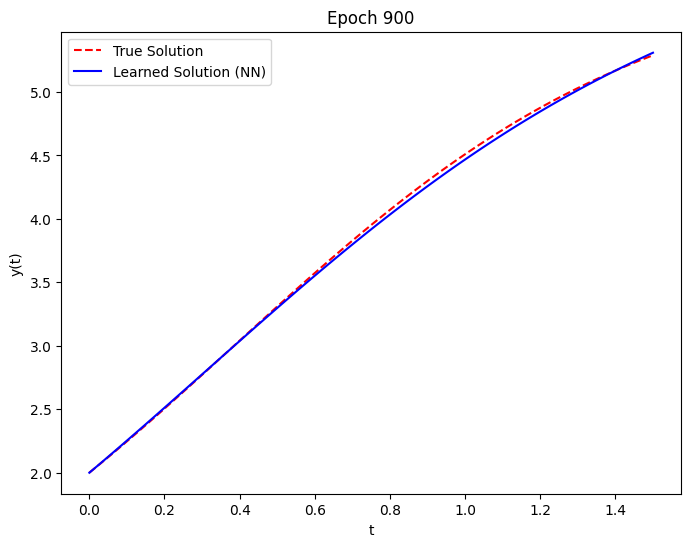

Epoch 950, Test Loss: 0.0005299081676639616


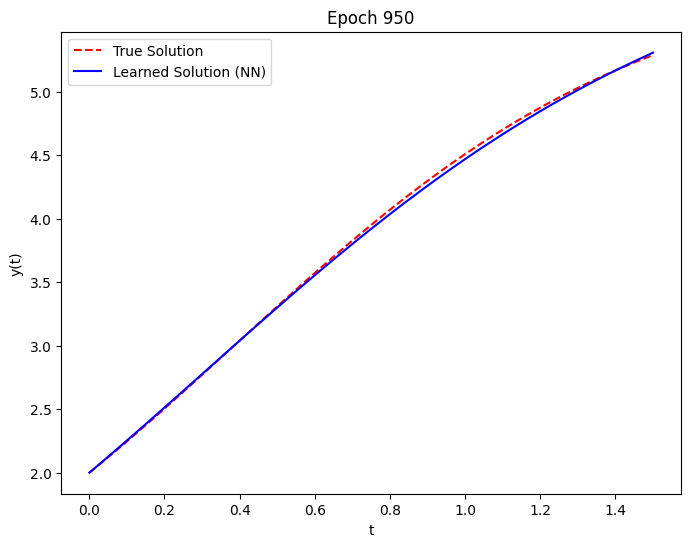

Epoch 1000, Test Loss: 0.0005558321136049926


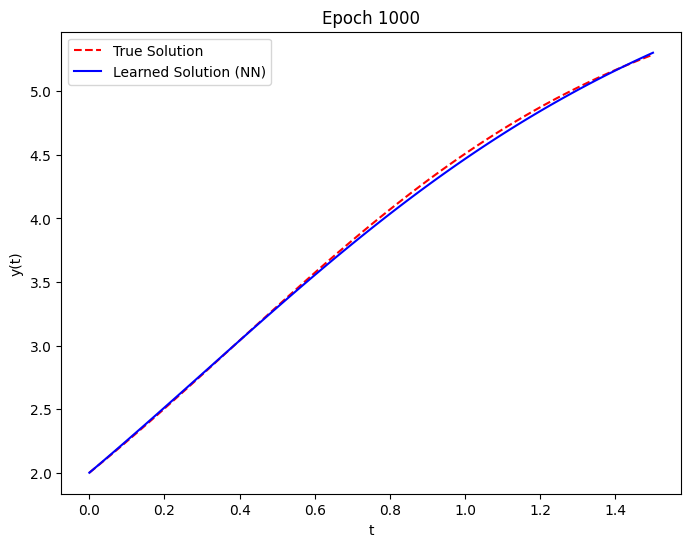

Epoch 1050, Test Loss: 0.0005534618976525962


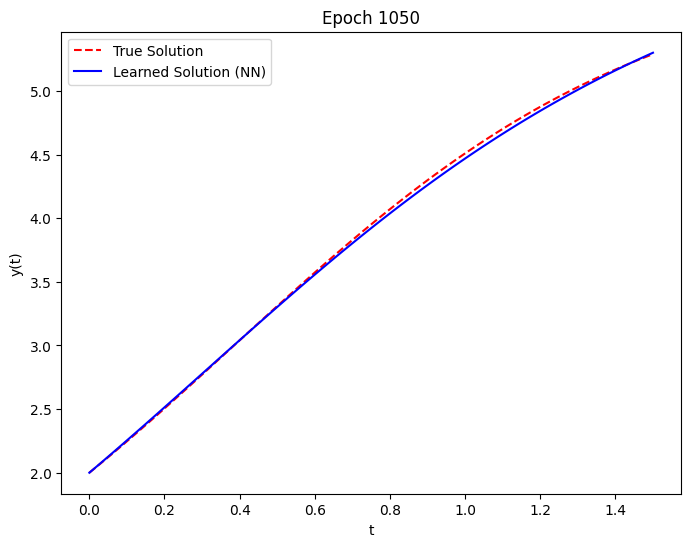

Epoch 1100, Test Loss: 0.0005962059367448092


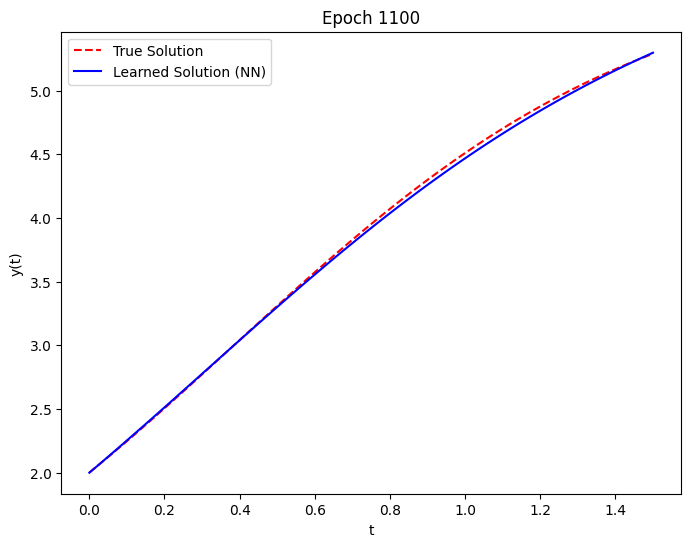

Epoch 1150, Test Loss: 0.0002263919886900112


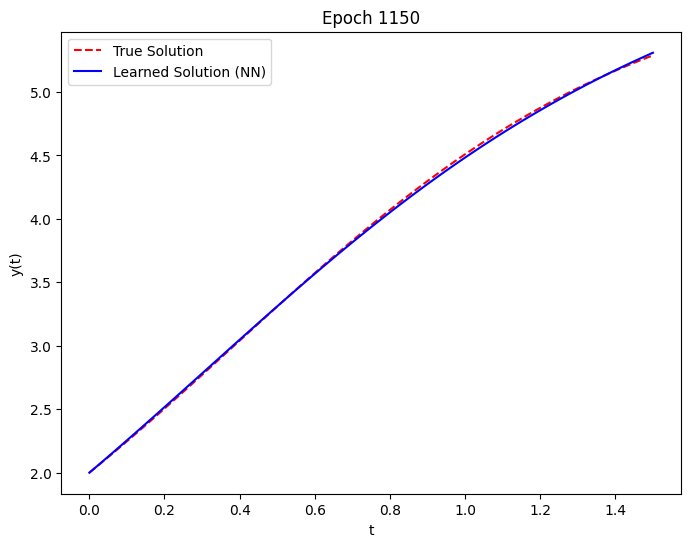

Epoch 1200, Test Loss: 0.00030683763907290995


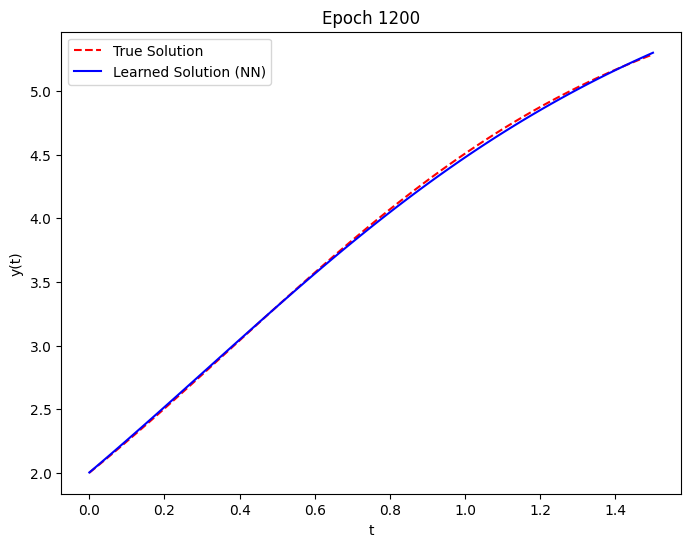

Epoch 1250, Test Loss: 0.0002572842058725655


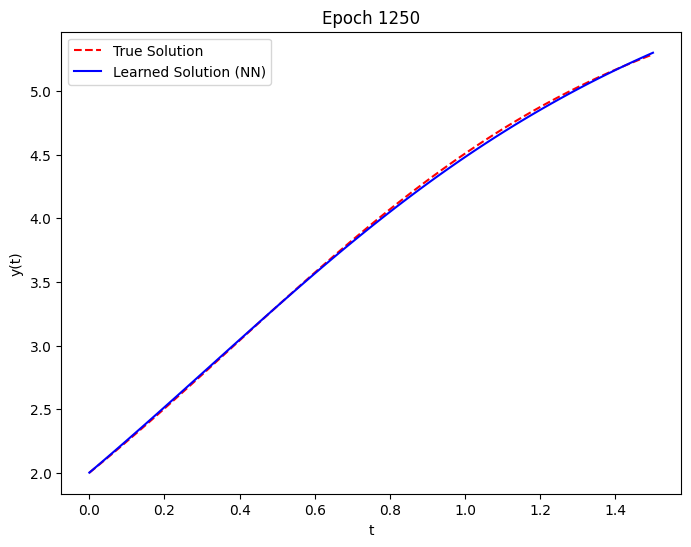

Epoch 1300, Test Loss: 0.0003121407644357532


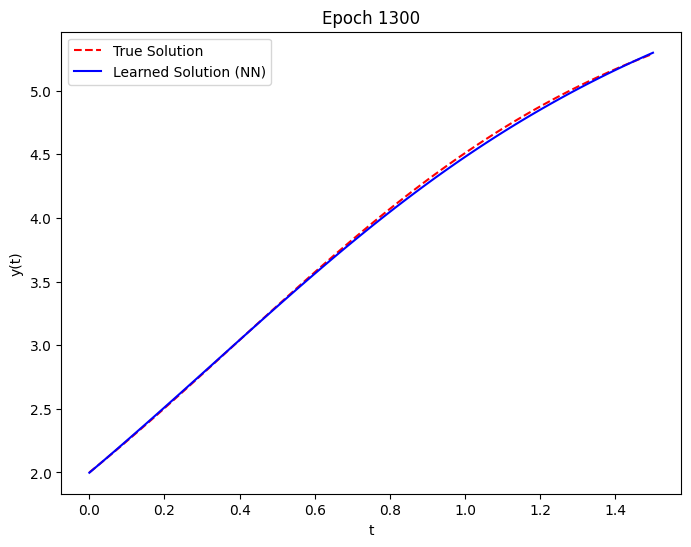

Epoch 1350, Test Loss: 0.00028965240926481783


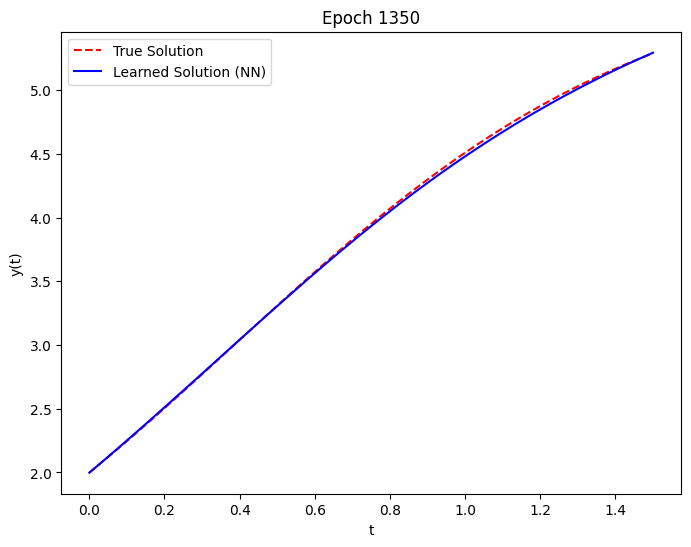

Epoch 1400, Test Loss: 0.0001902180229080841


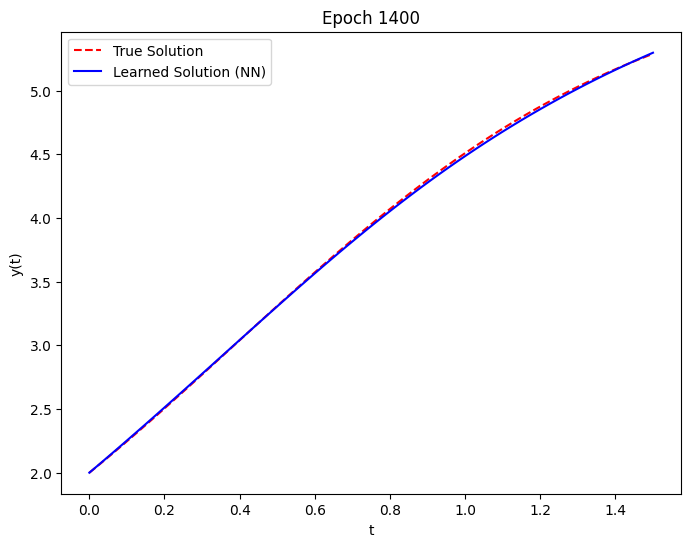

Epoch 1450, Test Loss: 0.00017117582319770008


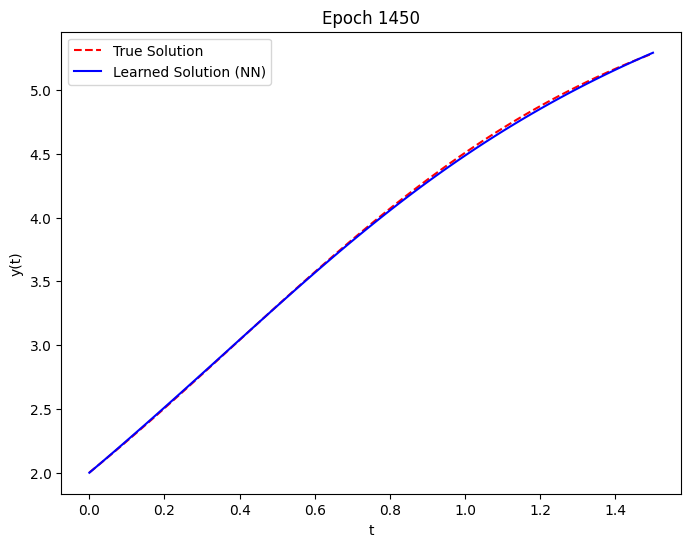

Epoch 1500, Test Loss: 0.0001286523911403492


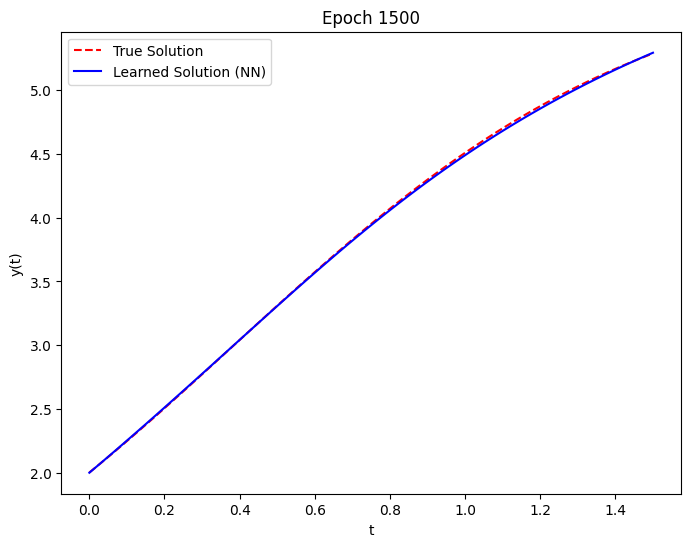

Epoch 1550, Test Loss: 5.240914106252603e-05


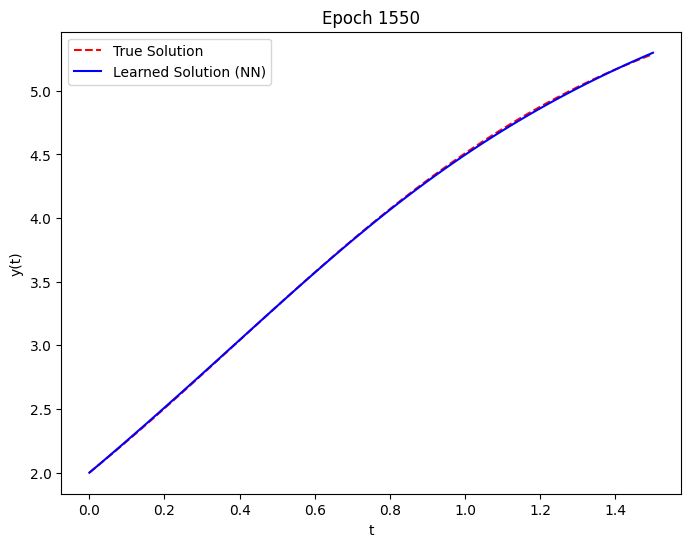

Epoch 1600, Test Loss: 4.3845233449246734e-05


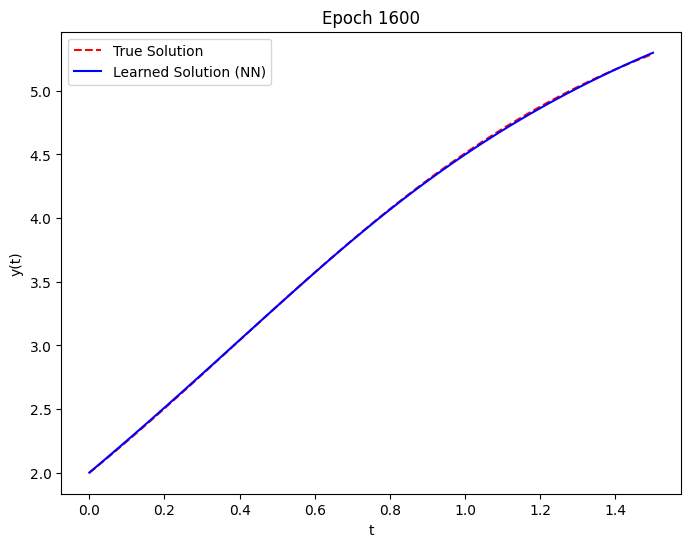

Epoch 1650, Test Loss: 3.868248677463271e-05


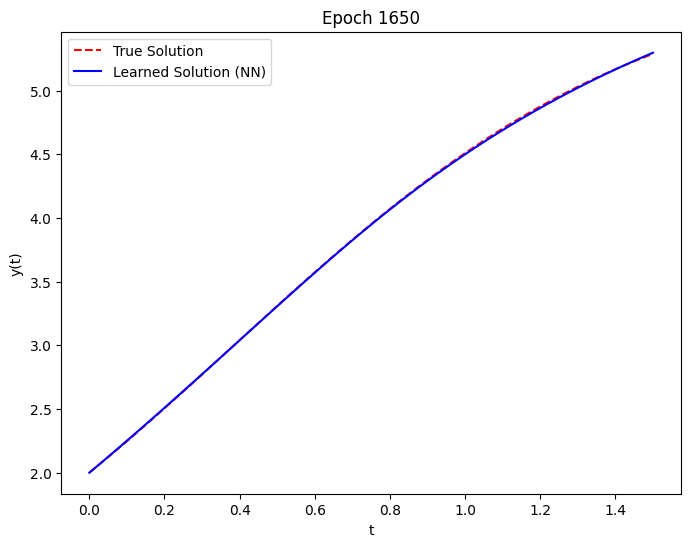

Epoch 1700, Test Loss: 5.6135108025046065e-05


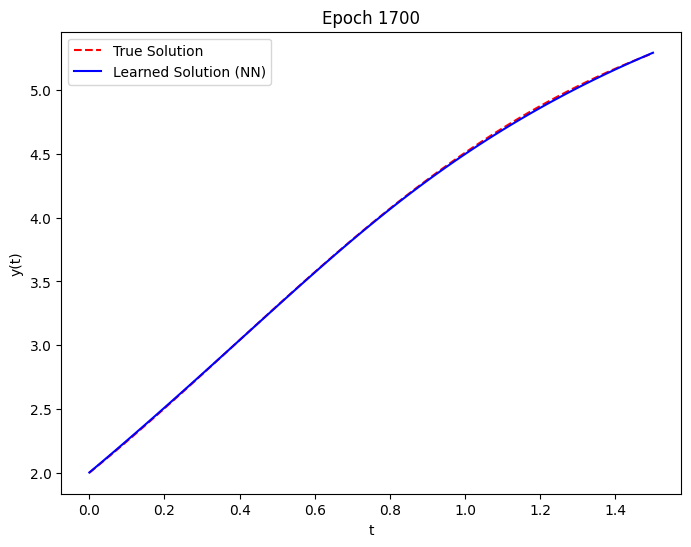

Epoch 1750, Test Loss: 1.8745515262708068e-05


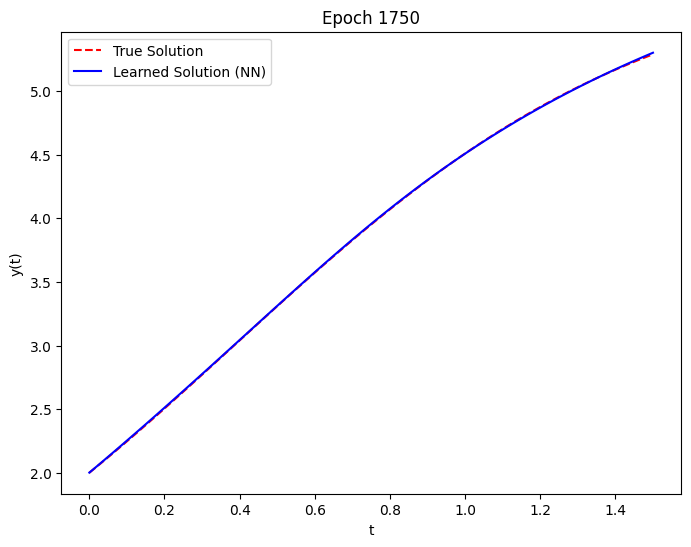

Epoch 1800, Test Loss: 3.092458791797981e-05


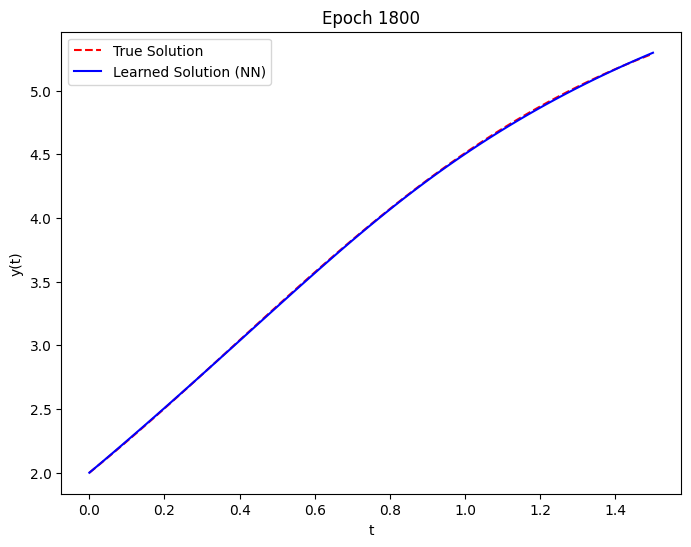

Epoch 1850, Test Loss: 4.808699304703623e-05


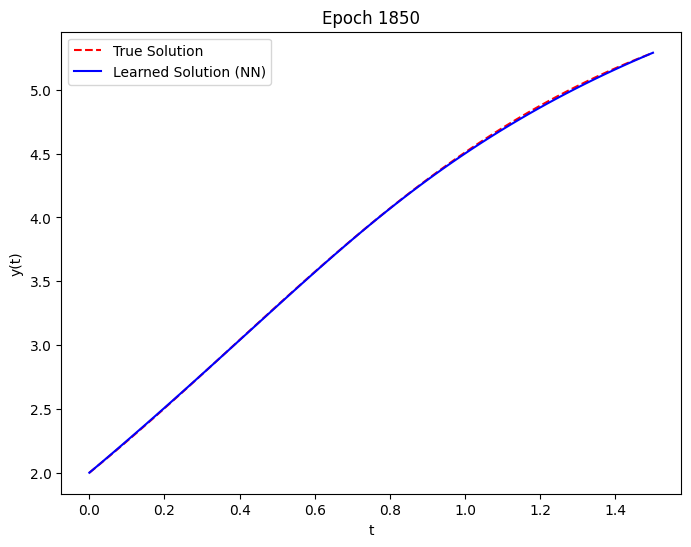

Epoch 1900, Test Loss: 4.546814307104796e-05


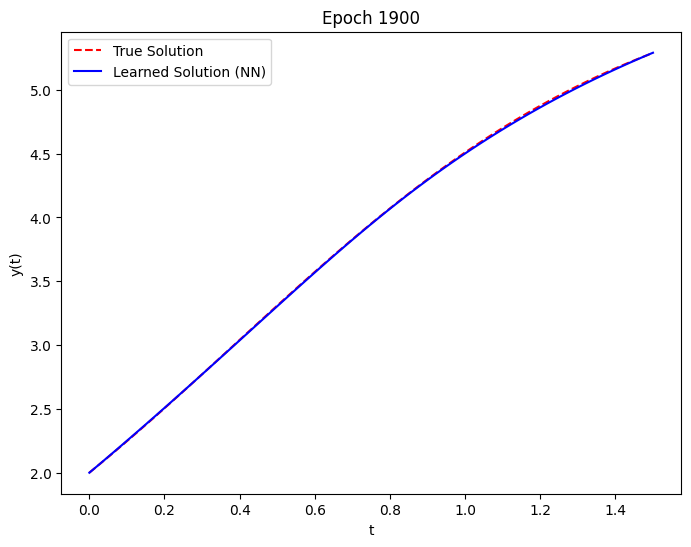

Epoch 1950, Test Loss: 3.186030517099425e-05


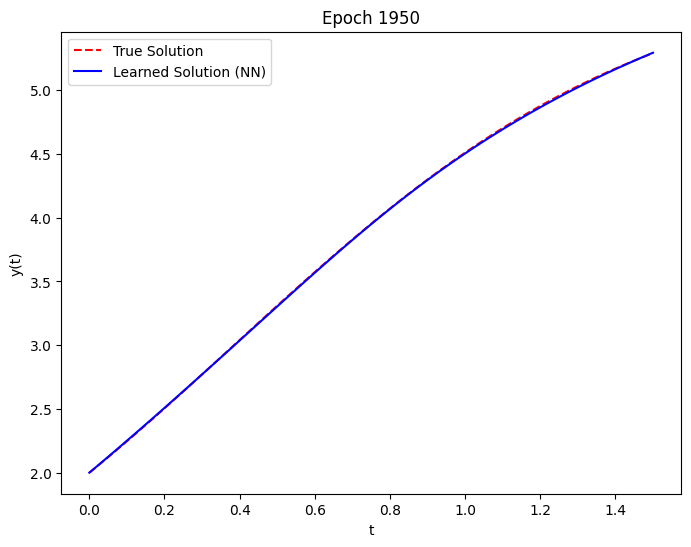

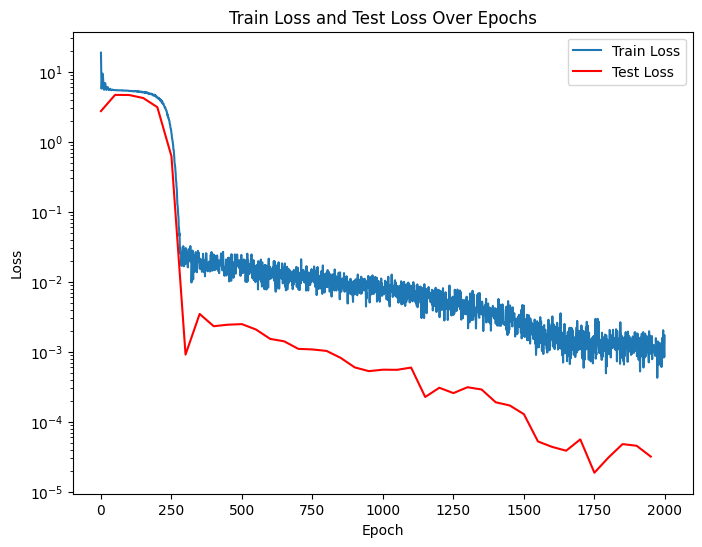

In [23]:
# Fix the randomness for reproducibility
set_seed(42)

# Initialize the model
model = NeuralNet()

# Define the optimizer
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Call the function with the parameters
train_ode_solver(M, r, y0, T, model, optimizer, num_epochs, batch_size, learning_rate, eval_every, w_ic)

## Check over multiple seeds

In [24]:
def train_ode_solver_multi(M, r, y0, T, num_epochs, batch_size, learning_rate, eval_every, w_ic):
    # Initialize the model
    model = NeuralNet()

    # Define the optimizer
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    # Create a testing set of 100 points sampled uniformly from [0, T]
    t_test = torch.linspace(0, T, 100).unsqueeze(1)
    y_test_true = true_solution(t_test, M, r, y0).detach()

    # Lists to store losses
    train_losses = []
    test_losses = []

    # Training loop
    for epoch in range(num_epochs):
        model.train()

        # Sample minibatch of time points uniformly in [0, T]
        t_batch = T * torch.rand(batch_size, 1)

        # Compute the total loss: ODE residual loss + initial condition loss
        loss_ode = ode_loss(model, t_batch, M, r)
        loss_ic = initial_condition_loss(model, y0)
        loss = loss_ode + w_ic * loss_ic

        # Backpropagation and optimizer step
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Record train loss
        train_losses.append(loss.item())

        # Evaluate the model on the testing set every 'eval_every' epochs
        if epoch % eval_every == 0:
            model.eval()
            with torch.no_grad():
                y_test_pred = model(t_test)
                test_loss = torch.mean((y_test_pred - y_test_true) ** 2)
                test_losses.append(test_loss.item())
                print(f'Epoch {epoch}, Test Loss: {test_loss.item()}')

    # Plot the true solution and the learned solution by the NN
    plt.figure(figsize=(8, 6))
    plt.plot(t_test.numpy(), y_test_true.numpy(), 'r--', label="True Solution")
    plt.plot(t_test.numpy(), y_test_pred.numpy(), 'b-', label="Learned Solution (NN)")
    plt.legend()
    plt.xlabel("t")
    plt.ylabel("y(t)")
    plt.show()
    # Return train and test losses
    return train_losses, test_losses

In [25]:
# Function to run the training multiple times with different seeds
def run_multiple_seeds(num_runs, seeds, M, r, y0, T, num_epochs, batch_size, learning_rate, eval_every, w_ic):
    all_train_losses = []
    all_test_losses = []

    # Run over different seeds
    for seed in seeds:
        print(f"Training with seed {seed}")
        set_seed(seed)  # Fix the seed for this run
        train_losses, test_losses = train_ode_solver_multi(M, r, y0, T, num_epochs, batch_size, learning_rate, eval_every, w_ic)
        all_train_losses.append(train_losses)
        all_test_losses.append(test_losses)

    # Convert lists to NumPy arrays for easier processing
    all_train_losses = np.array(all_train_losses)
    all_test_losses = np.array(all_test_losses)

    # Compute mean and standard deviation
    mean_train_losses = np.mean(all_train_losses, axis=0)
    std_train_losses = np.std(all_train_losses, axis=0)

    mean_test_losses = np.mean(all_test_losses, axis=0)
    std_test_losses = np.std(all_test_losses, axis=0)

    # Plot the mean and stddev as shaded areas
    epochs = np.arange(num_epochs)
    eval_epochs = np.arange(0, num_epochs, eval_every)

    plt.figure(figsize=(8, 6))

    # Plot training loss
    plt.semilogy(epochs, mean_train_losses, label='Mean Train Loss', color='blue')
    plt.fill_between(epochs, mean_train_losses - std_train_losses, mean_train_losses + std_train_losses, color='blue', alpha=0.2)

    # Plot test loss
    plt.semilogy(eval_epochs, mean_test_losses, label='Mean Test Loss', color='red')
    plt.fill_between(eval_epochs, mean_test_losses - std_test_losses, mean_test_losses + std_test_losses, color='red', alpha=0.2)

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Train and Test Loss Over Multiple Runs")
    plt.legend()
    plt.show()

Training with seed 0
Epoch 0, Test Loss: 3.8389780521392822
Epoch 50, Test Loss: 4.761144161224365
Epoch 100, Test Loss: 4.524088382720947
Epoch 150, Test Loss: 3.8211400508880615
Epoch 200, Test Loss: 1.7605133056640625
Epoch 250, Test Loss: 0.0032776459120213985
Epoch 300, Test Loss: 0.0040515027940273285
Epoch 350, Test Loss: 0.0035889693535864353
Epoch 400, Test Loss: 0.0028703368734568357
Epoch 450, Test Loss: 0.0024882005527615547
Epoch 500, Test Loss: 0.0019567864947021008
Epoch 550, Test Loss: 0.0016856498550623655
Epoch 600, Test Loss: 0.0012905554613098502
Epoch 650, Test Loss: 0.0010403478518128395
Epoch 700, Test Loss: 0.0009223012020811439
Epoch 750, Test Loss: 0.0009601946221664548
Epoch 800, Test Loss: 0.0006418730481527746
Epoch 850, Test Loss: 0.0006566799711436033
Epoch 900, Test Loss: 0.0005817791679874063
Epoch 950, Test Loss: 0.00023338523169513792
Epoch 1000, Test Loss: 0.0003095446736551821
Epoch 1050, Test Loss: 0.00031225179554894567
Epoch 1100, Test Loss: 0.00

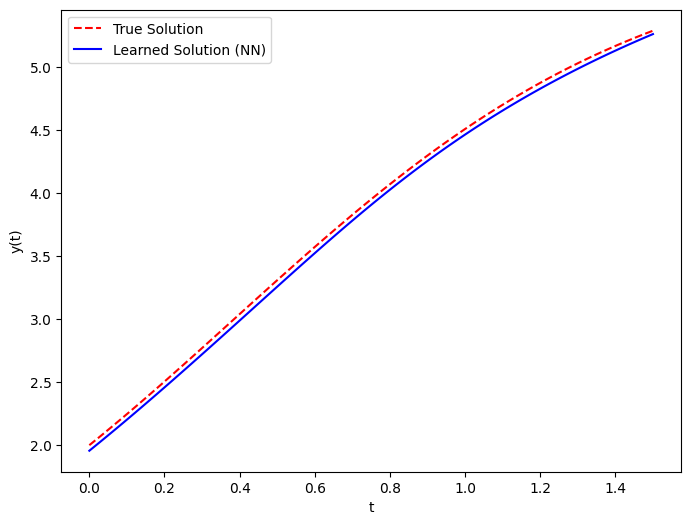

Training with seed 1
Epoch 0, Test Loss: 1.822393774986267
Epoch 50, Test Loss: 5.082090854644775
Epoch 100, Test Loss: 4.650700092315674
Epoch 150, Test Loss: 4.291444301605225
Epoch 200, Test Loss: 3.5973525047302246
Epoch 250, Test Loss: 2.0024619102478027
Epoch 300, Test Loss: 0.11474170535802841
Epoch 350, Test Loss: 0.004378954879939556
Epoch 400, Test Loss: 0.005389006342738867
Epoch 450, Test Loss: 0.004791876766830683
Epoch 500, Test Loss: 0.005446464288979769
Epoch 550, Test Loss: 0.003319080686196685
Epoch 600, Test Loss: 0.004037460312247276
Epoch 650, Test Loss: 0.0034958941396325827
Epoch 700, Test Loss: 0.0026480245869606733
Epoch 750, Test Loss: 0.002945234766229987
Epoch 800, Test Loss: 0.0019567934796214104
Epoch 850, Test Loss: 0.001476805191487074
Epoch 900, Test Loss: 0.0015527793439105153
Epoch 950, Test Loss: 0.0012100967578589916
Epoch 1000, Test Loss: 0.0011667960789054632
Epoch 1050, Test Loss: 0.0008911820477806032
Epoch 1100, Test Loss: 0.0008645955240353942

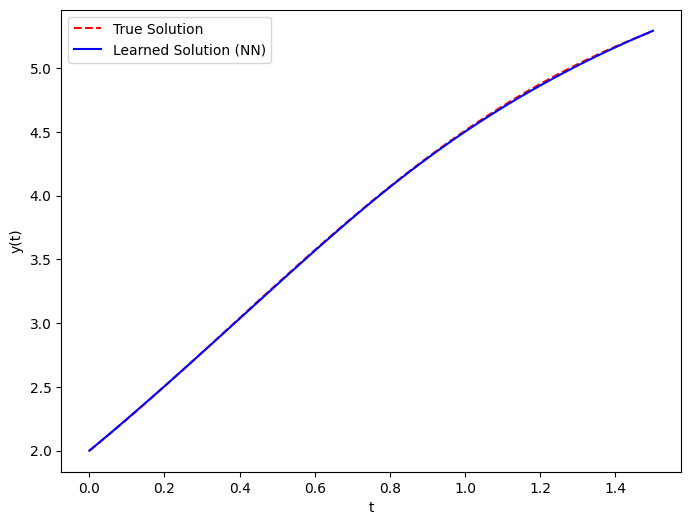

Training with seed 2
Epoch 0, Test Loss: 3.853804111480713
Epoch 50, Test Loss: 4.673430442810059
Epoch 100, Test Loss: 4.47465705871582
Epoch 150, Test Loss: 3.68563175201416
Epoch 200, Test Loss: 1.5106583833694458
Epoch 250, Test Loss: 0.0018925565527752042
Epoch 300, Test Loss: 0.0045930324122309685
Epoch 350, Test Loss: 0.0032196003012359142
Epoch 400, Test Loss: 0.0020515108481049538
Epoch 450, Test Loss: 0.0024000820703804493
Epoch 500, Test Loss: 0.002263090806081891
Epoch 550, Test Loss: 0.0020989063195884228
Epoch 600, Test Loss: 0.0015017993282526731
Epoch 650, Test Loss: 0.0012526637874543667
Epoch 700, Test Loss: 0.0010298497509211302
Epoch 750, Test Loss: 0.0009719729423522949
Epoch 800, Test Loss: 0.000612470495980233
Epoch 850, Test Loss: 0.0004974348703399301
Epoch 900, Test Loss: 0.00032906257547438145
Epoch 950, Test Loss: 0.0003593300352804363
Epoch 1000, Test Loss: 0.00031385995680466294
Epoch 1050, Test Loss: 0.00023245257034432143
Epoch 1100, Test Loss: 0.0001104

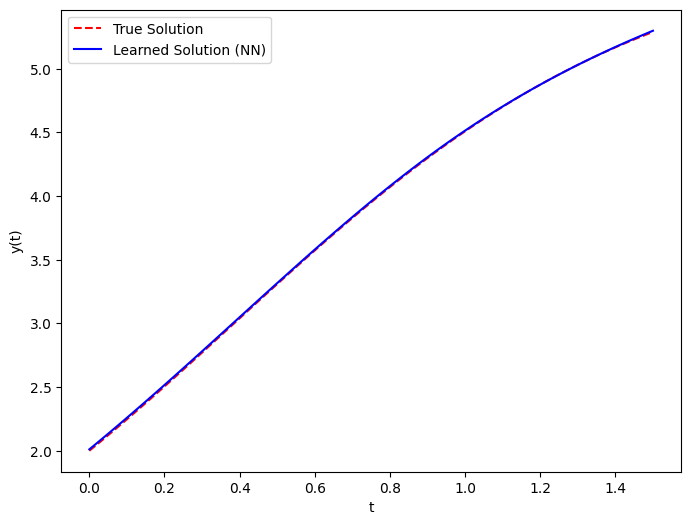

Training with seed 3
Epoch 0, Test Loss: 3.721686601638794
Epoch 50, Test Loss: 4.869027614593506
Epoch 100, Test Loss: 4.583844184875488
Epoch 150, Test Loss: 3.949446439743042
Epoch 200, Test Loss: 2.0663633346557617
Epoch 250, Test Loss: 0.014831909909844398
Epoch 300, Test Loss: 0.0036871007177978754
Epoch 350, Test Loss: 0.00281096575781703
Epoch 400, Test Loss: 0.0023363677319139242
Epoch 450, Test Loss: 0.0021474454551935196
Epoch 500, Test Loss: 0.001557552837766707
Epoch 550, Test Loss: 0.0013397467555478215
Epoch 600, Test Loss: 0.0019477333407849073
Epoch 650, Test Loss: 0.0011854623444378376
Epoch 700, Test Loss: 0.0006077404250390828
Epoch 750, Test Loss: 0.0010199140524491668
Epoch 800, Test Loss: 0.0008821762166917324
Epoch 850, Test Loss: 0.0005922133568674326
Epoch 900, Test Loss: 0.00038850316195748746
Epoch 950, Test Loss: 0.0003608563856687397
Epoch 1000, Test Loss: 0.0005979784182272851
Epoch 1050, Test Loss: 0.0003407109179534018
Epoch 1100, Test Loss: 0.000146954

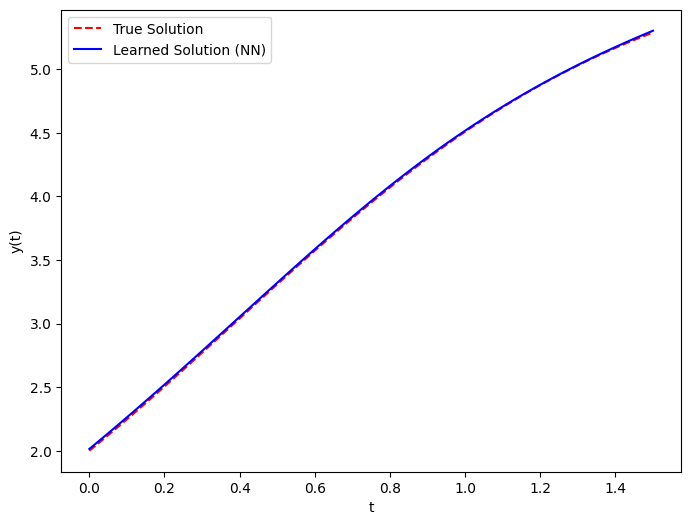

Training with seed 4
Epoch 0, Test Loss: 2.5528576374053955
Epoch 50, Test Loss: 4.627722263336182
Epoch 100, Test Loss: 4.697506427764893
Epoch 150, Test Loss: 4.292929172515869
Epoch 200, Test Loss: 3.3278393745422363
Epoch 250, Test Loss: 1.0630964040756226
Epoch 300, Test Loss: 0.003036829875782132
Epoch 350, Test Loss: 0.0032963240519165993
Epoch 400, Test Loss: 0.0034987078979611397
Epoch 450, Test Loss: 0.0030381125397980213
Epoch 500, Test Loss: 0.0030796993523836136
Epoch 550, Test Loss: 0.0019139810465276241
Epoch 600, Test Loss: 0.001996596809476614
Epoch 650, Test Loss: 0.0018329661106690764
Epoch 700, Test Loss: 0.0013642980484291911
Epoch 750, Test Loss: 0.0012773813214153051
Epoch 800, Test Loss: 0.0012864709133282304
Epoch 850, Test Loss: 0.0008047582814469934
Epoch 900, Test Loss: 0.0010244089644402266
Epoch 950, Test Loss: 0.0007059323252178729
Epoch 1000, Test Loss: 0.0009342739940620959
Epoch 1050, Test Loss: 0.0005132348742336035
Epoch 1100, Test Loss: 0.0004038602

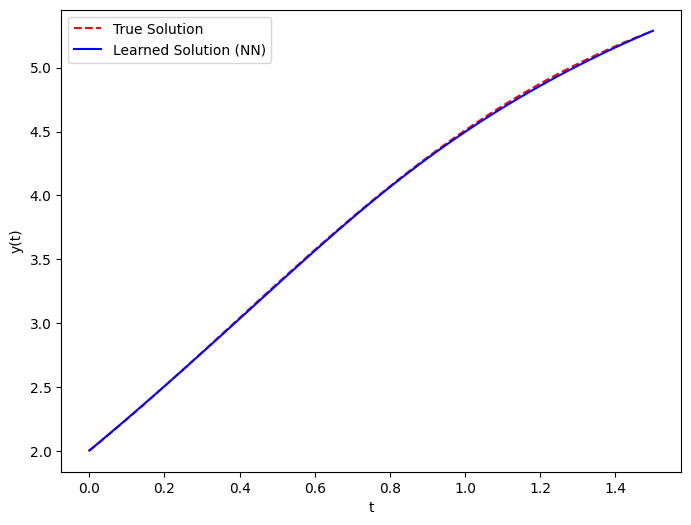

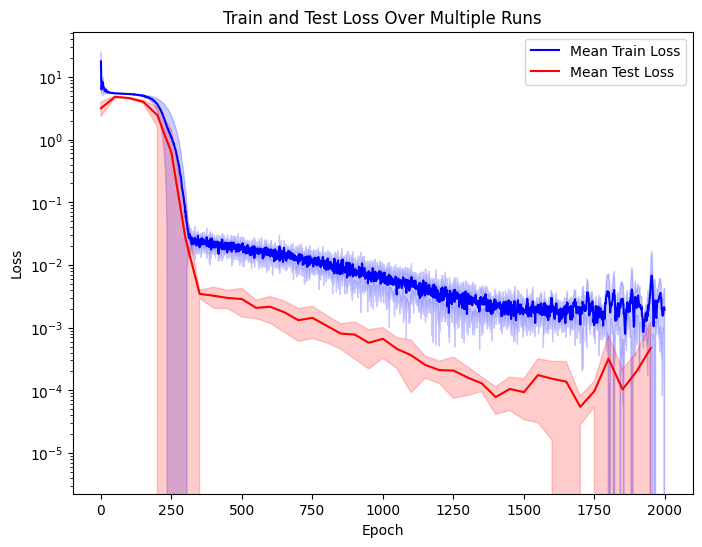

In [26]:
# Parameters
num_runs = 5
seeds = [0, 1, 2, 3, 4]  # List of seeds to run

# Run the experiments and plot the results
run_multiple_seeds(num_runs, seeds, M, r, y0, T, num_epochs, batch_size, learning_rate, eval_every, w_ic)

## Longer time horizon T

Now we will try with a larger $T$.

Epoch 0, Test Loss: 8.712148666381836


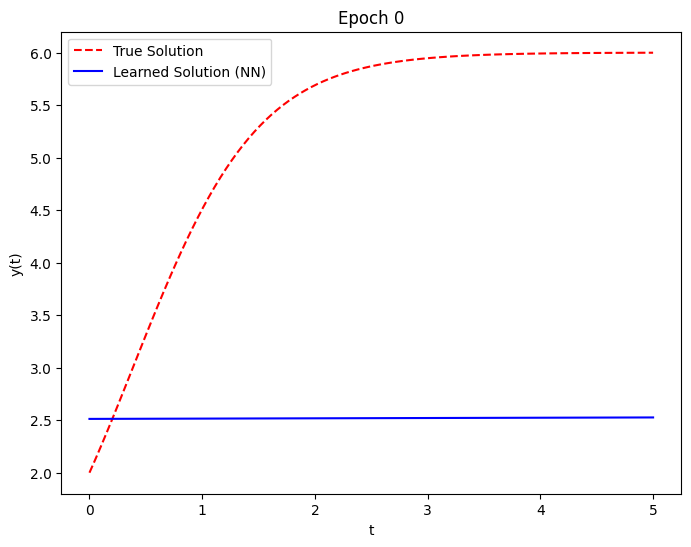

Epoch 50, Test Loss: 13.126358985900879


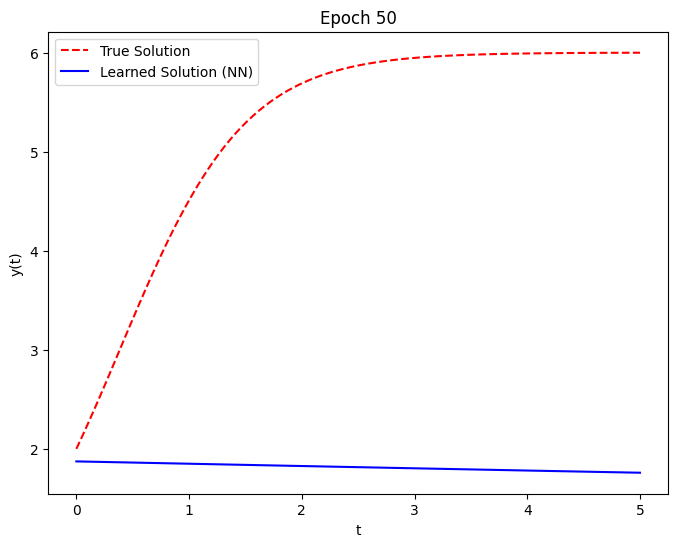

Epoch 100, Test Loss: 14.728589057922363


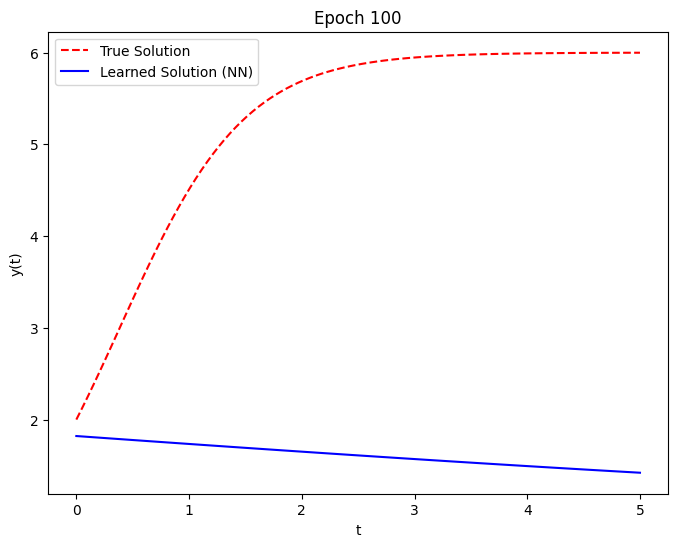

Epoch 150, Test Loss: 18.349597930908203


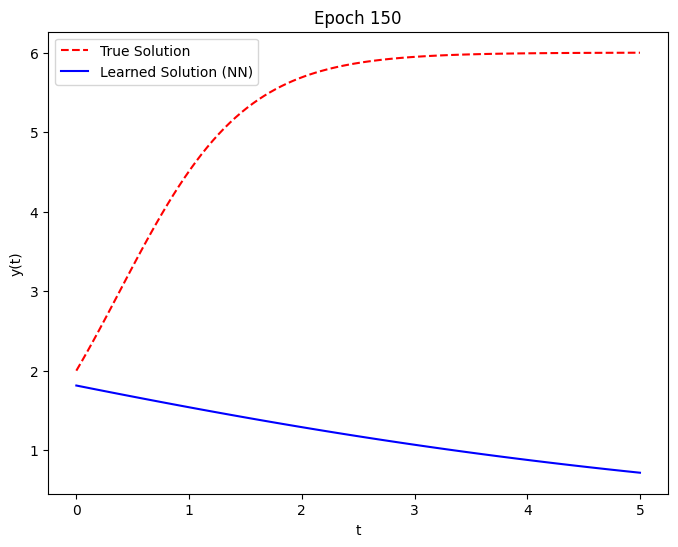

Epoch 200, Test Loss: 24.97201919555664


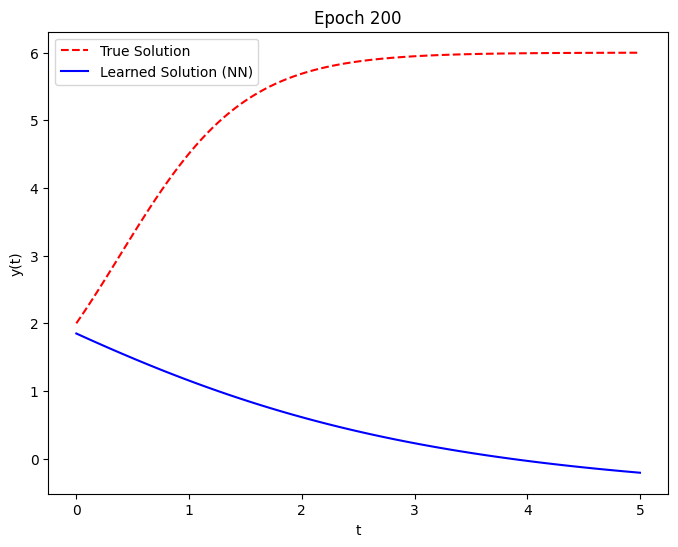

Epoch 250, Test Loss: 27.191781997680664


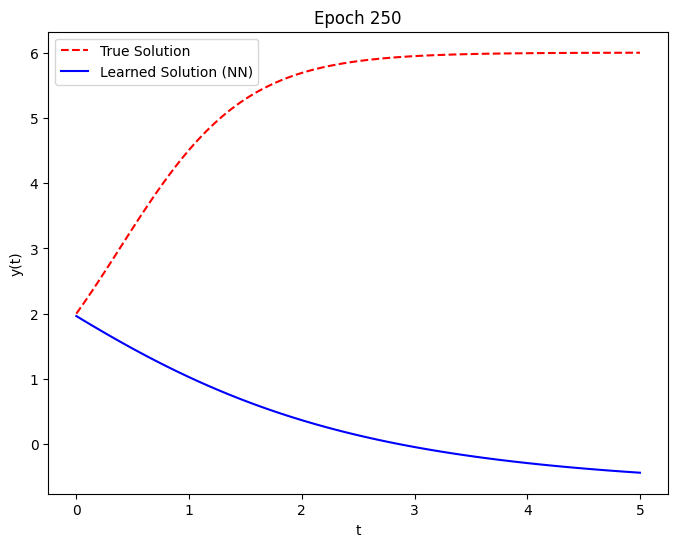

Epoch 300, Test Loss: 27.445993423461914


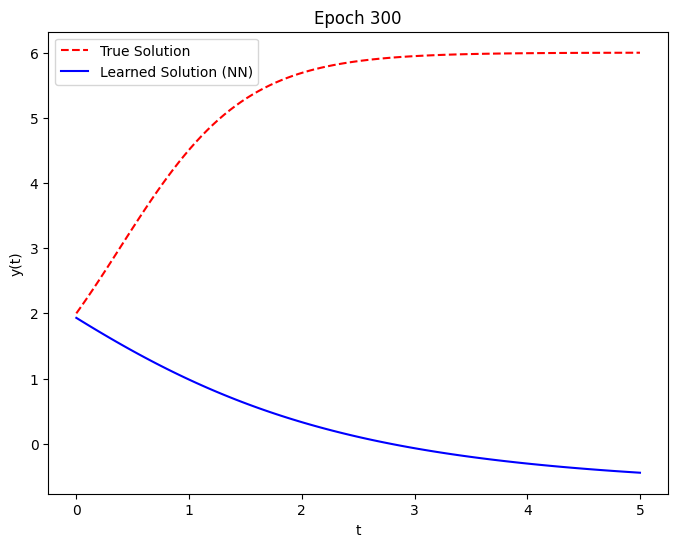

Epoch 350, Test Loss: 27.716611862182617


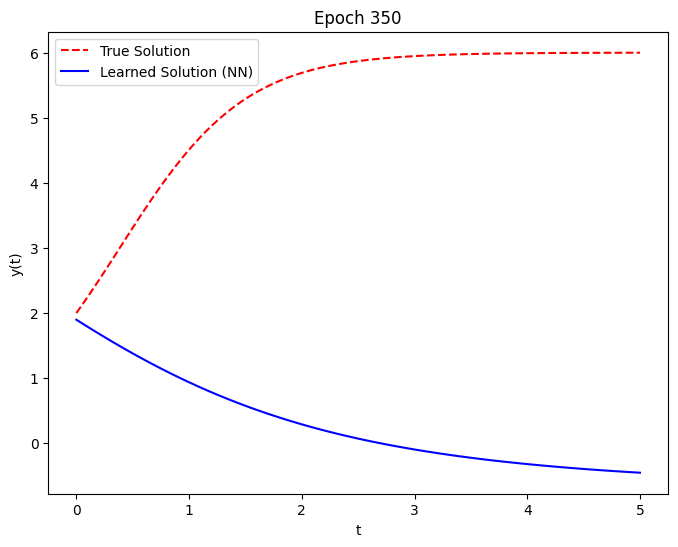

Epoch 400, Test Loss: 27.84429931640625


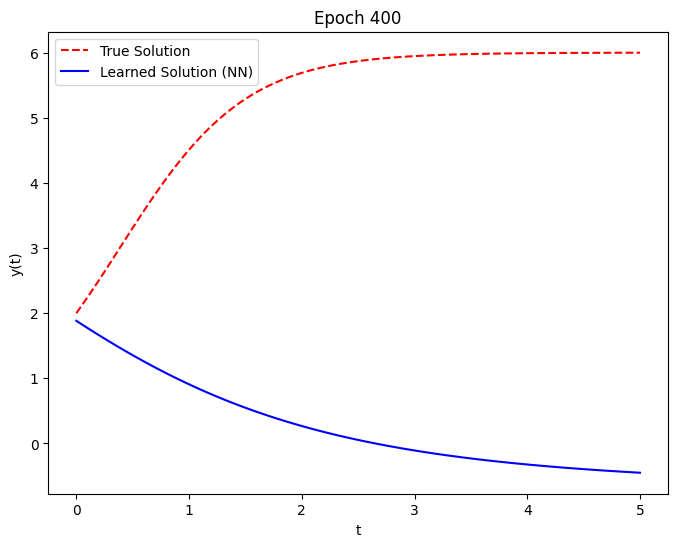

Epoch 450, Test Loss: 27.391098022460938


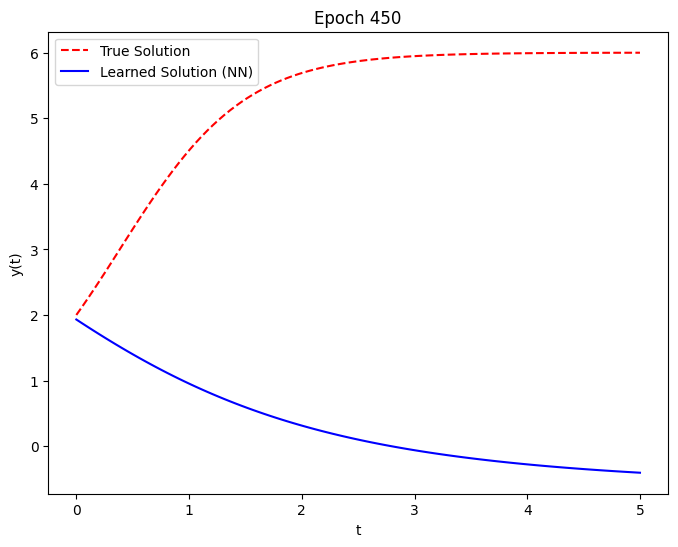

Epoch 500, Test Loss: 27.414552688598633


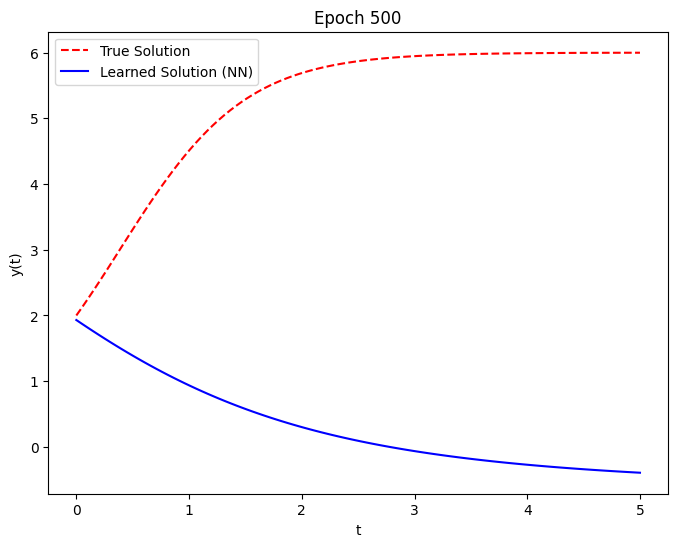

Epoch 550, Test Loss: 27.850187301635742


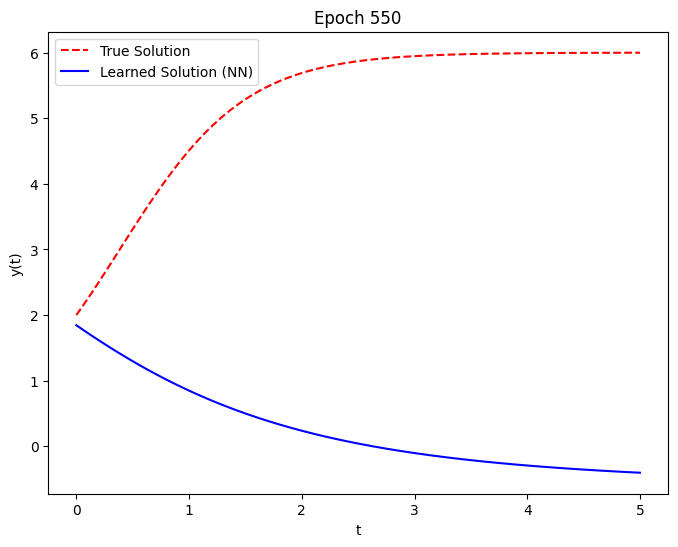

Epoch 600, Test Loss: 27.885465621948242


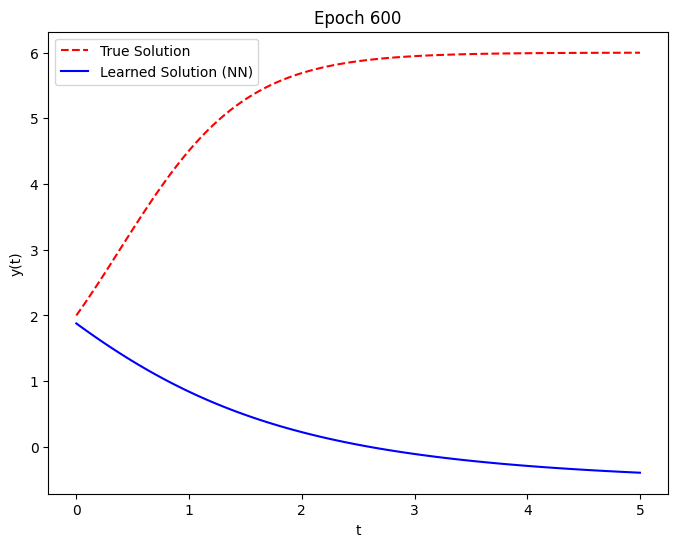

Epoch 650, Test Loss: 27.77495574951172


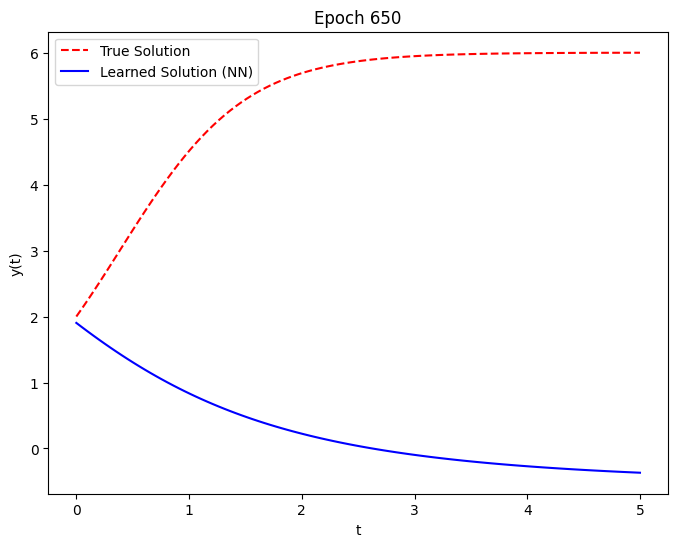

Epoch 700, Test Loss: 27.702497482299805


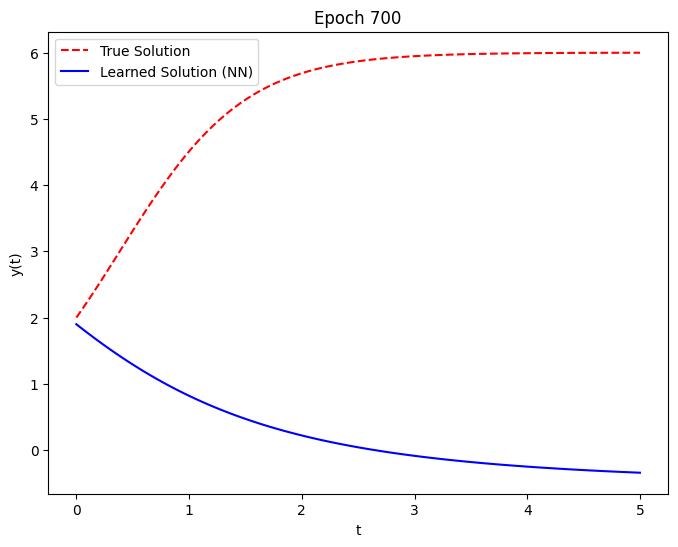

Epoch 750, Test Loss: 28.005834579467773


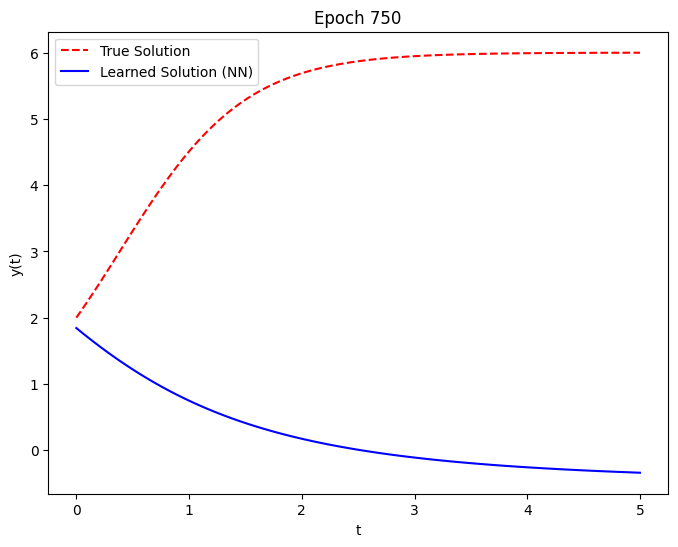

Epoch 800, Test Loss: 27.98175811767578


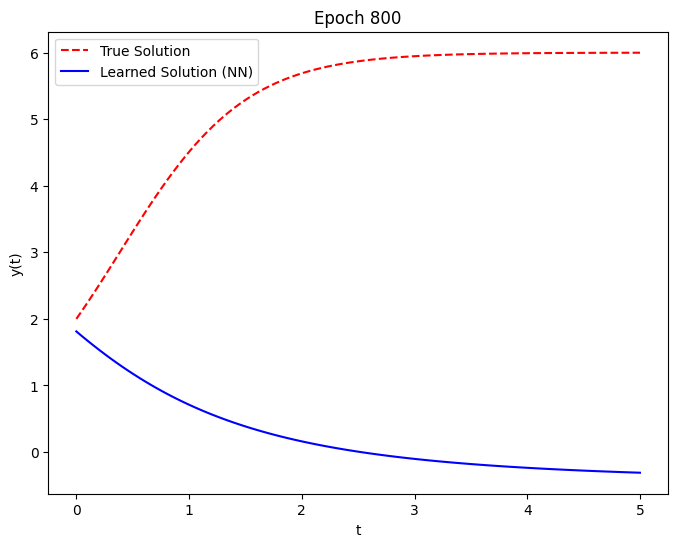

Epoch 850, Test Loss: 27.53716278076172


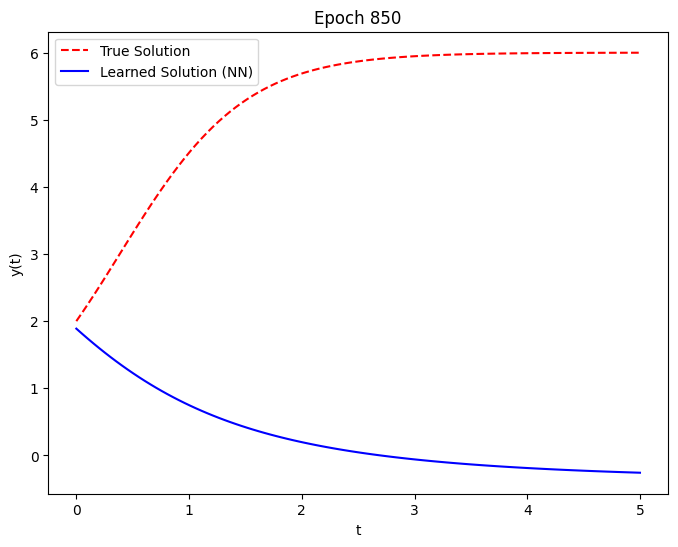

Epoch 900, Test Loss: 27.666027069091797


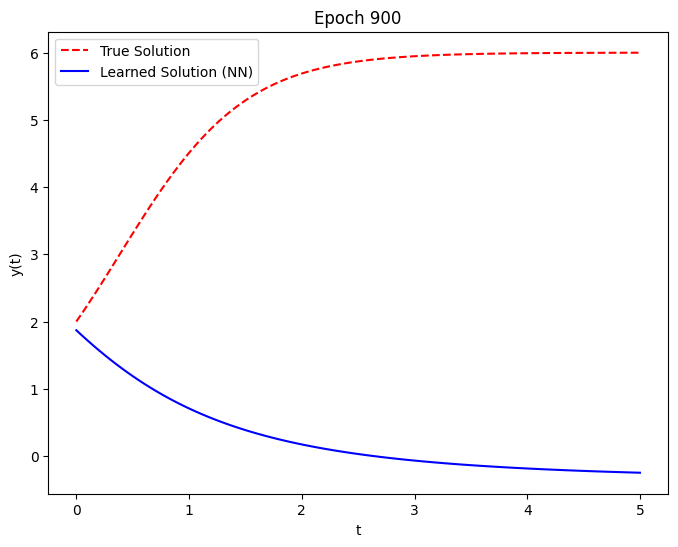

Epoch 950, Test Loss: 27.653179168701172


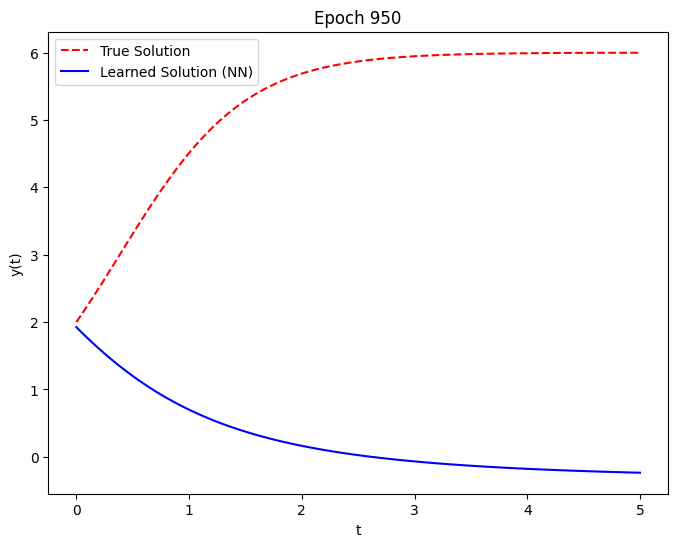

Epoch 1000, Test Loss: 27.248756408691406


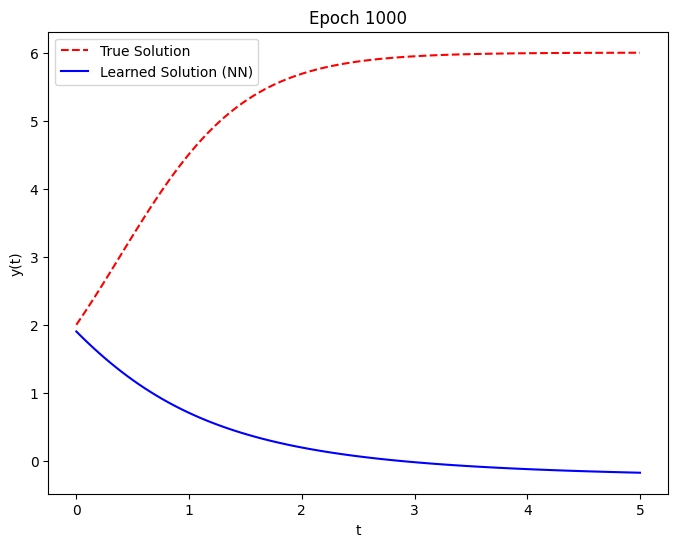

Epoch 1050, Test Loss: 27.749155044555664


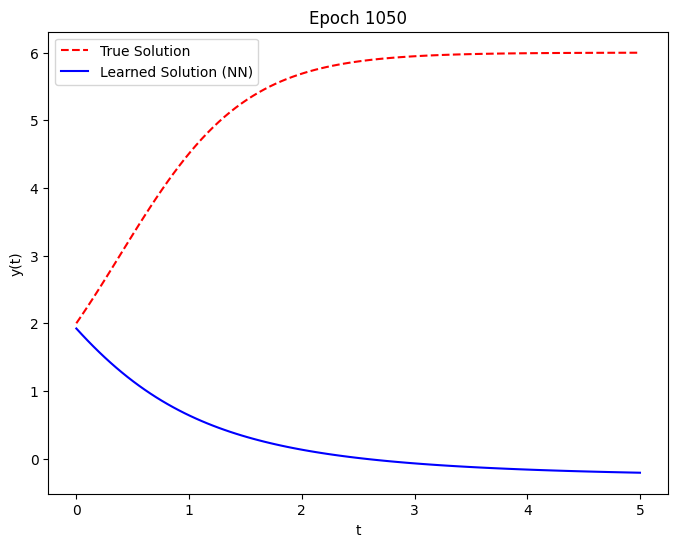

Epoch 1100, Test Loss: 26.513273239135742


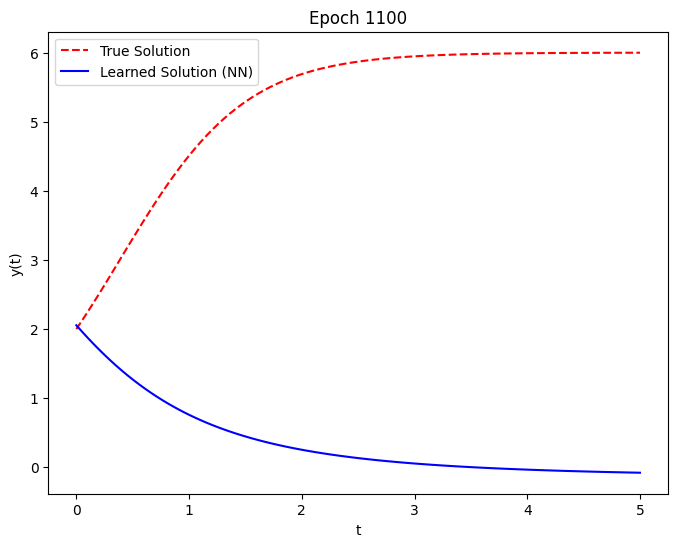

Epoch 1150, Test Loss: 28.24091148376465


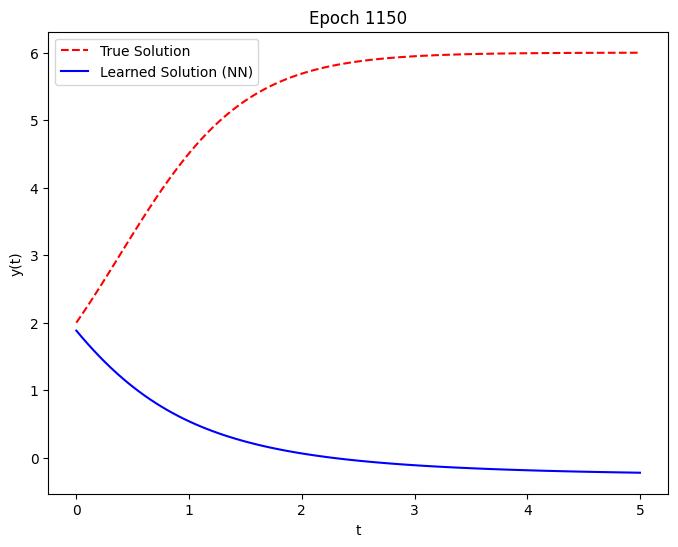

Epoch 1200, Test Loss: 27.435047149658203


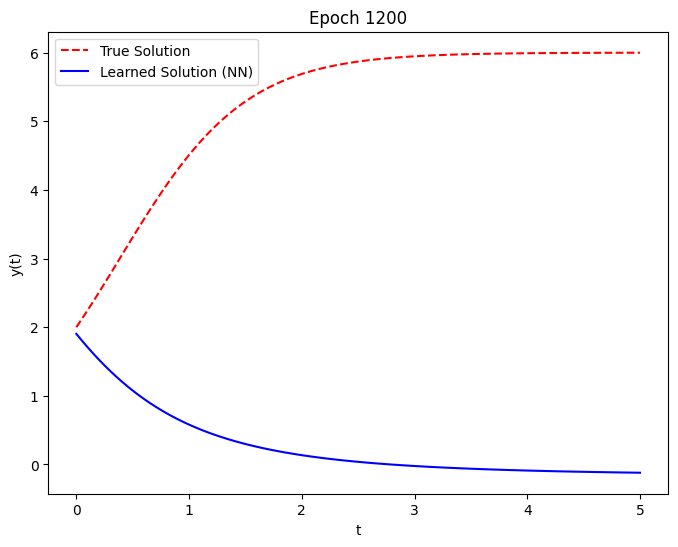

Epoch 1250, Test Loss: 27.768415451049805


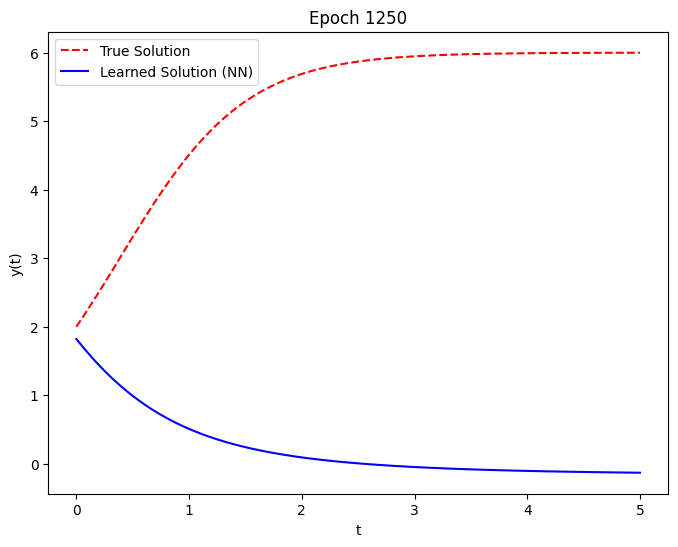

Epoch 1300, Test Loss: 26.627666473388672


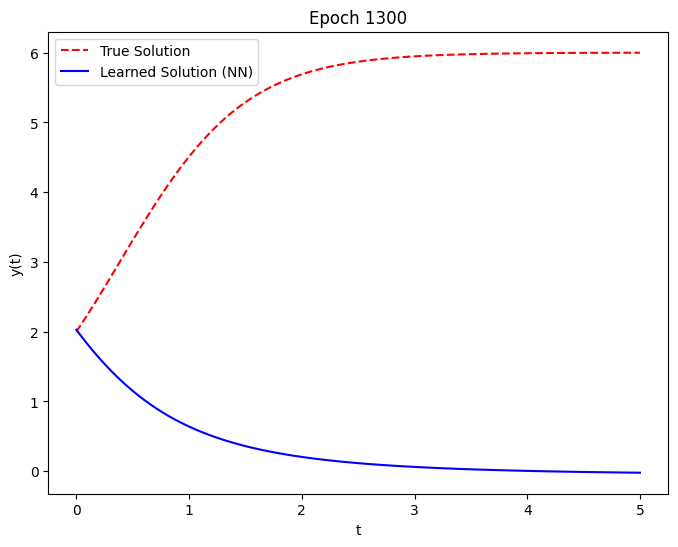

Epoch 1350, Test Loss: 26.987163543701172


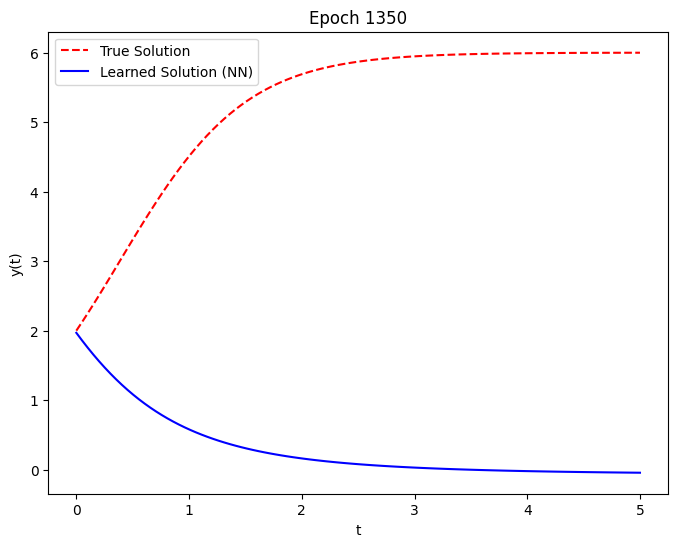

Epoch 1400, Test Loss: 27.155500411987305


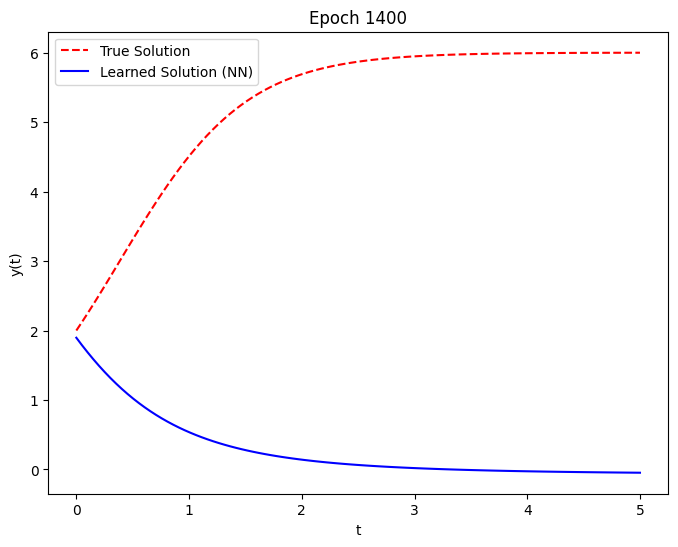

Epoch 1450, Test Loss: 27.197397232055664


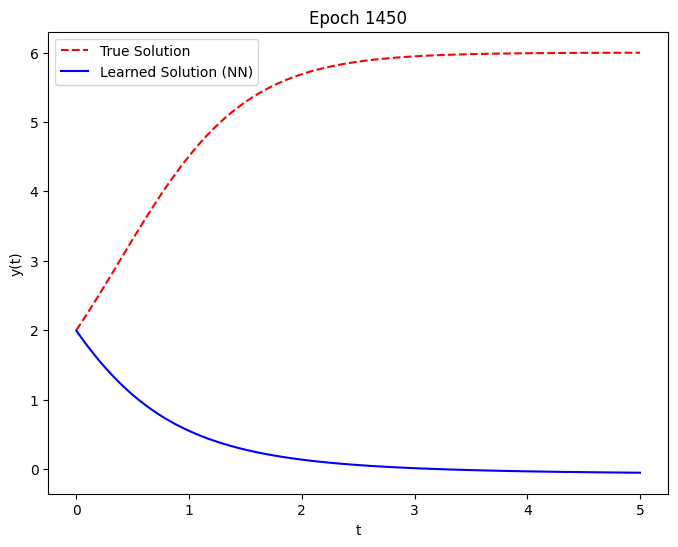

Epoch 1500, Test Loss: 27.810579299926758


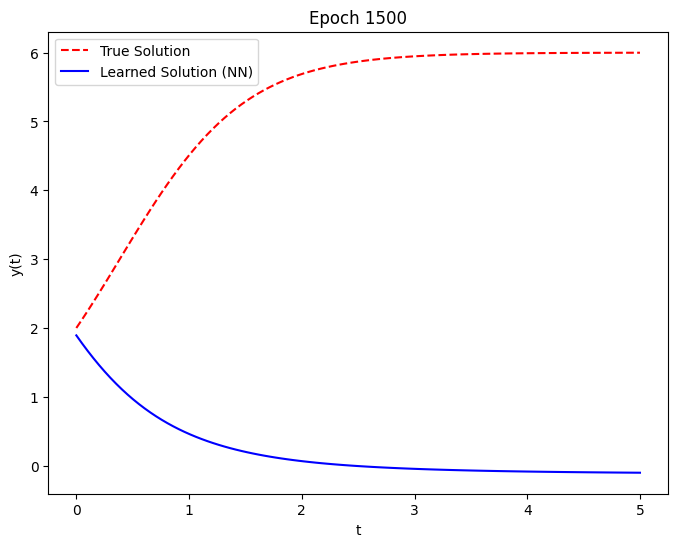

Epoch 1550, Test Loss: 27.162765502929688


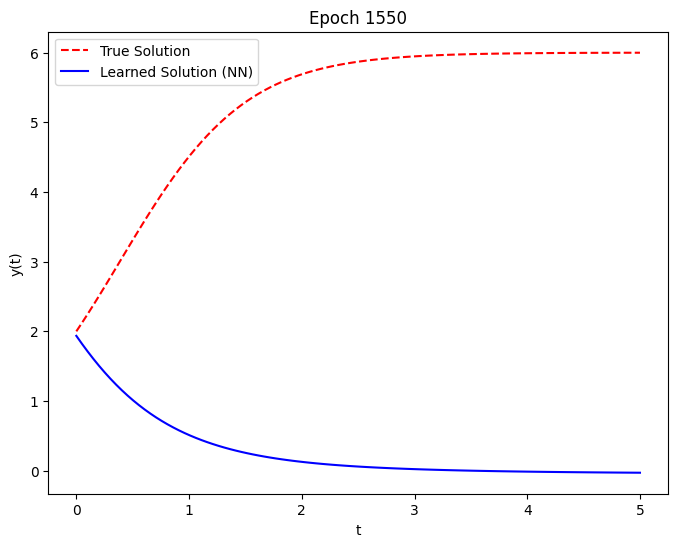

Epoch 1600, Test Loss: 27.240371704101562


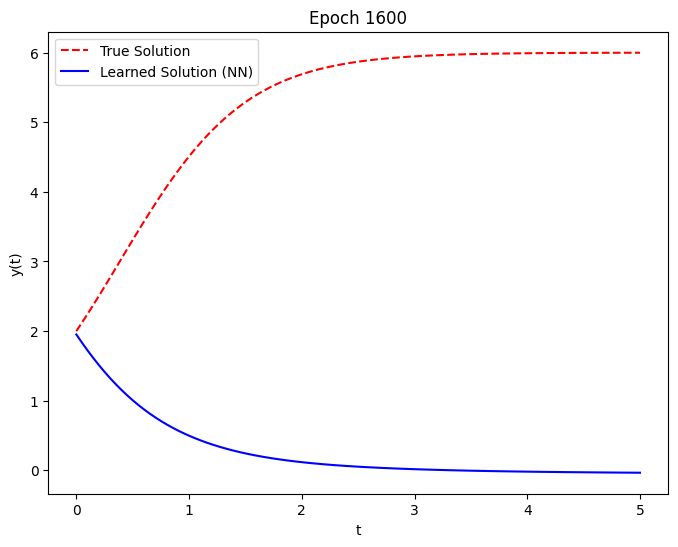

Epoch 1650, Test Loss: 27.395225524902344


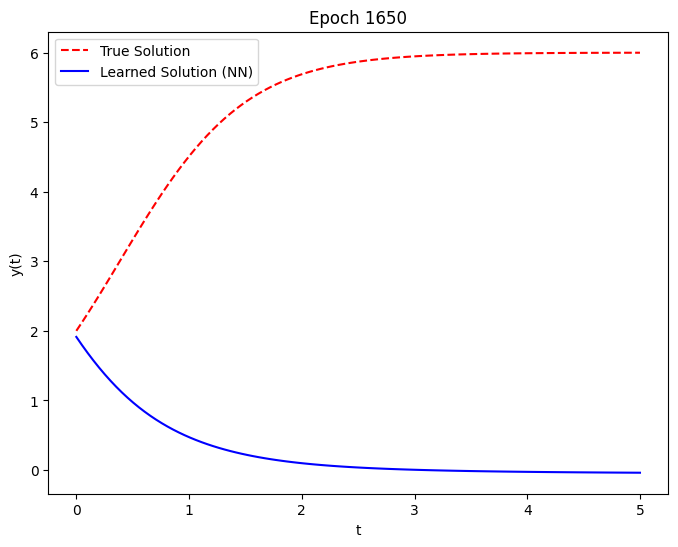

Epoch 1700, Test Loss: 26.768945693969727


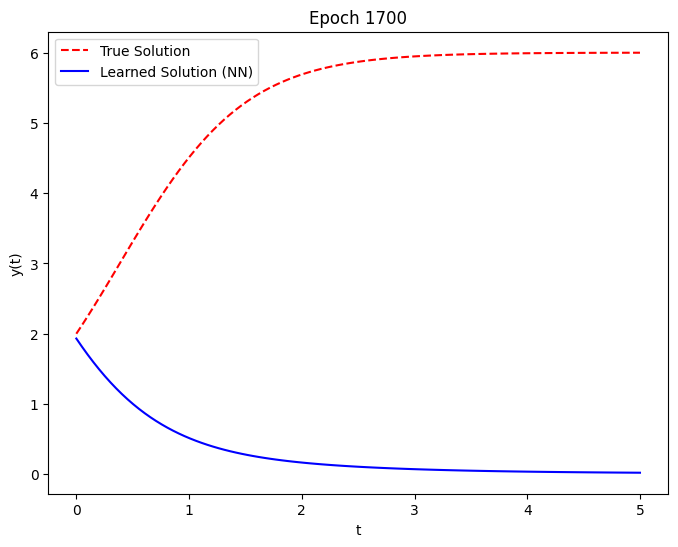

Epoch 1750, Test Loss: 27.272506713867188


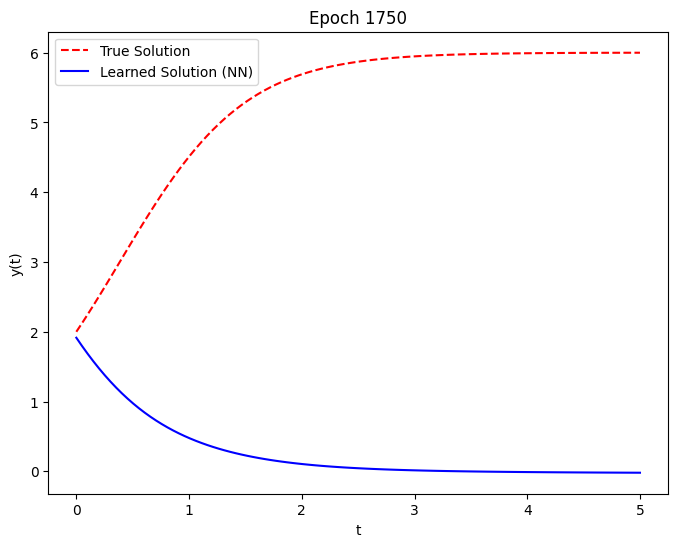

Epoch 1800, Test Loss: 27.163558959960938


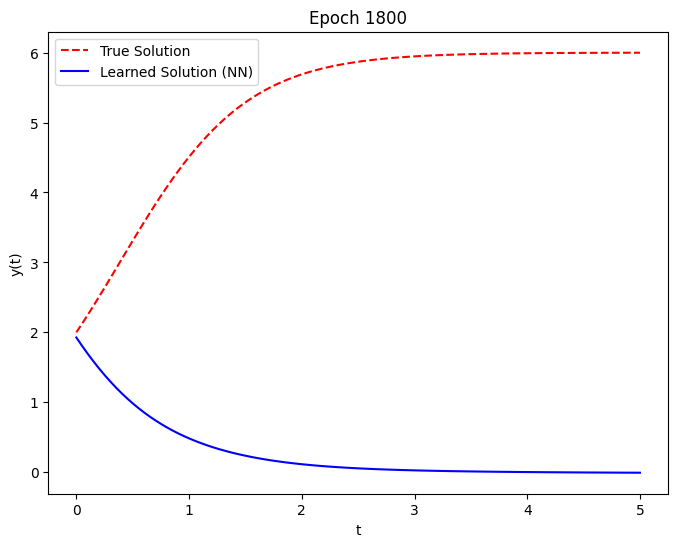

Epoch 1850, Test Loss: 27.24252700805664


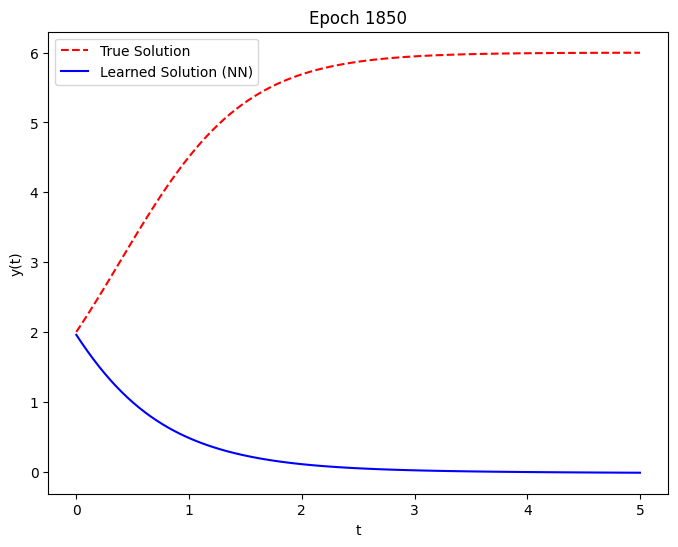

Epoch 1900, Test Loss: 27.050365447998047


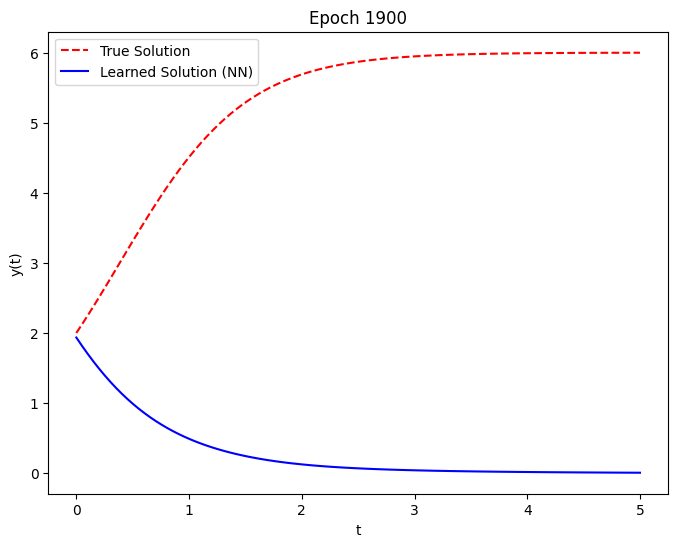

Epoch 1950, Test Loss: 26.52901840209961


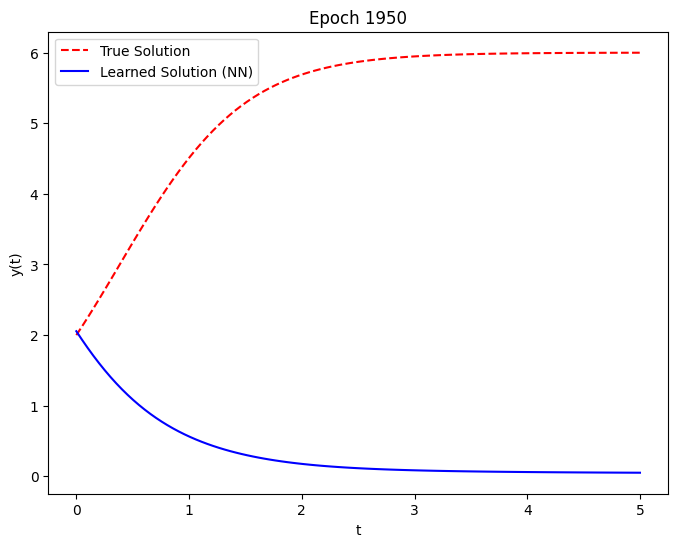

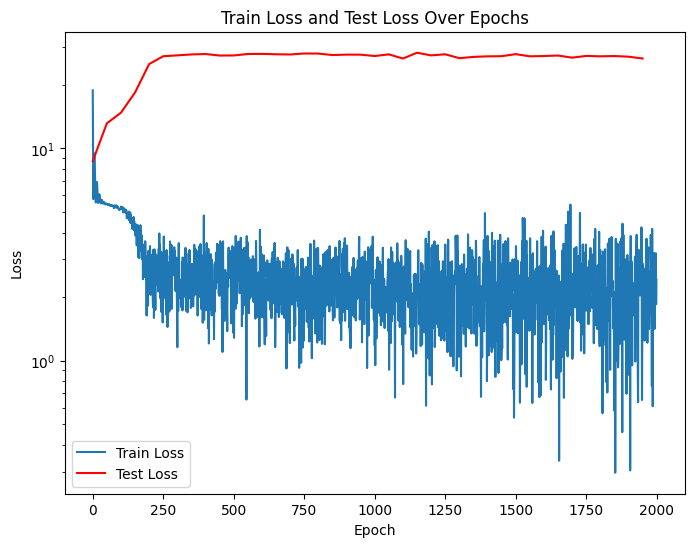

In [27]:
T = 5.0   # Time horizon

# Fix the randomness for reproducibility
set_seed(42)

# Initialize the model
model = NeuralNet()

# Define the optimizer
optimizer = optim.Adam(model.parameters(), lr=learning_rate) #Adam with model's parameters and given learning rate

# Call the function with the parameters
train_ode_solver(M,r,y0,T,model,optimizer,num_epochs,batch_size,learning_rate,eval_every,w_ic)

The NN fails to learn the solution.

To improve the results, we first **pre-train** the NN on the shorter horizon ($T=2$) and then keep training it on the longer horizon ($T=5$).

Epoch 0, Test Loss: 4.310971736907959


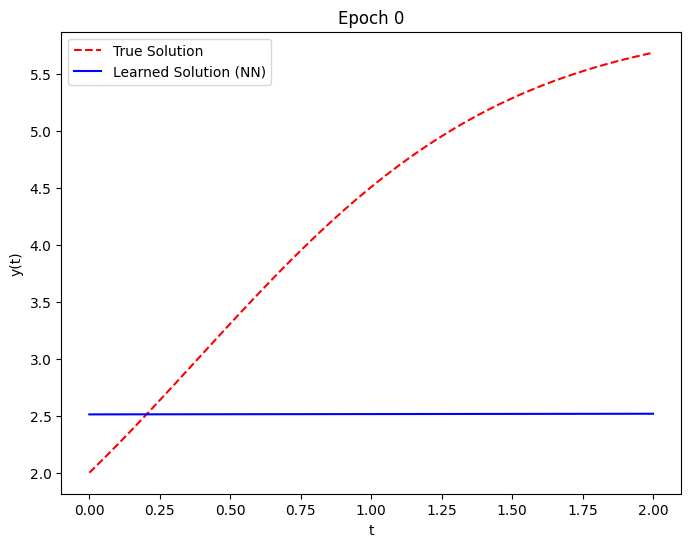

Epoch 50, Test Loss: 6.732602119445801


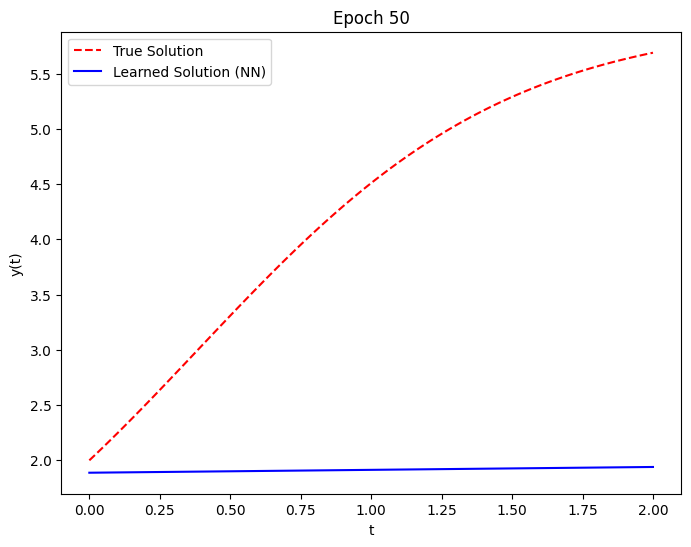

Epoch 100, Test Loss: 6.718245029449463


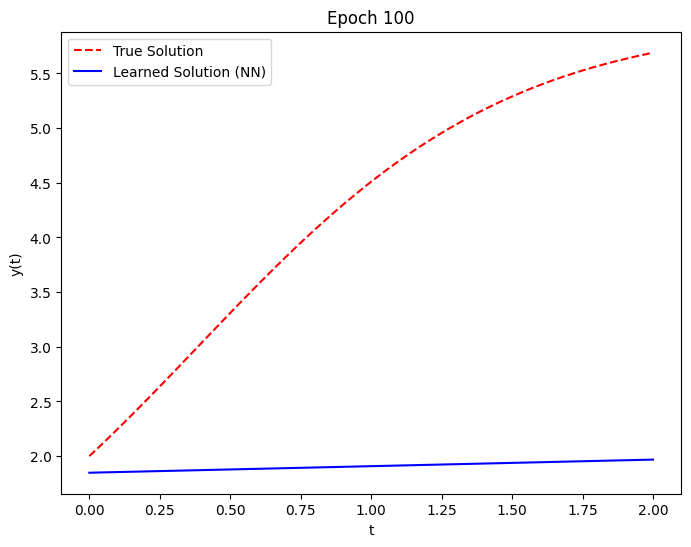

Epoch 150, Test Loss: 6.239984035491943


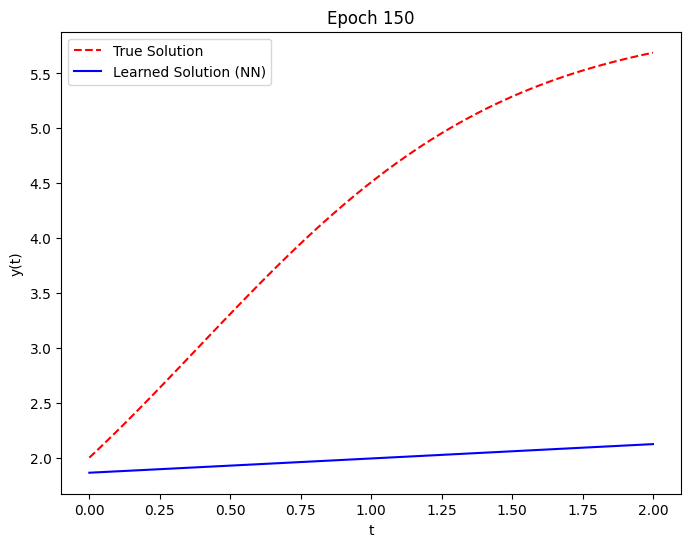

Epoch 200, Test Loss: 5.092837333679199


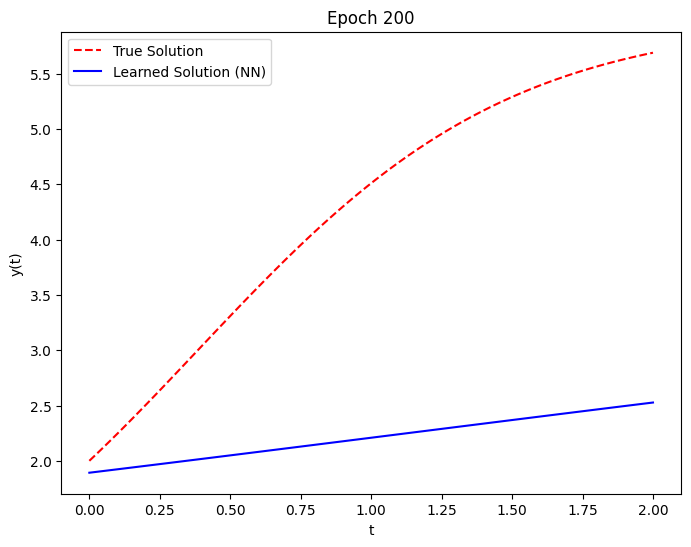

Epoch 250, Test Loss: 1.6026149988174438


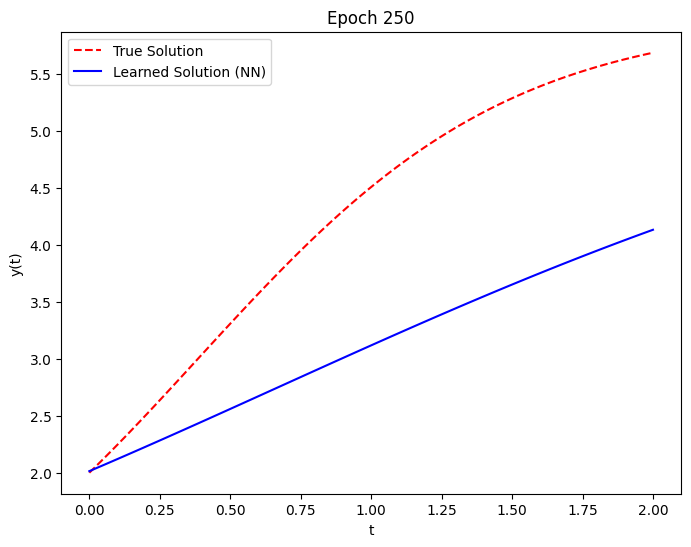

Epoch 300, Test Loss: 0.00767026050016284


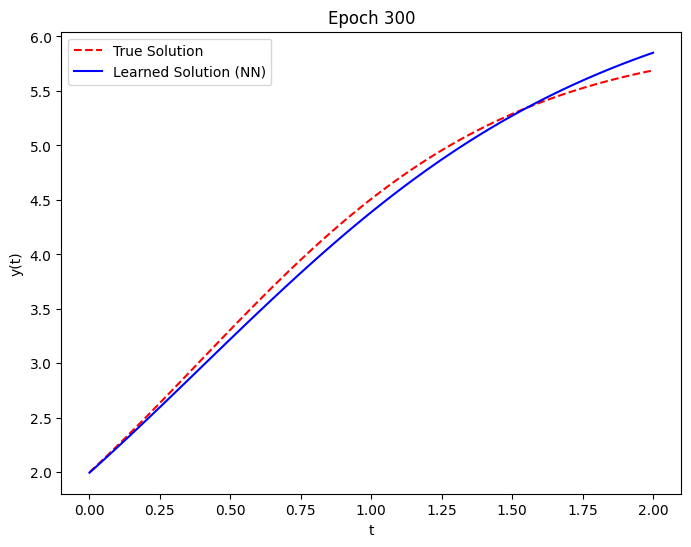

Epoch 350, Test Loss: 0.016684412956237793


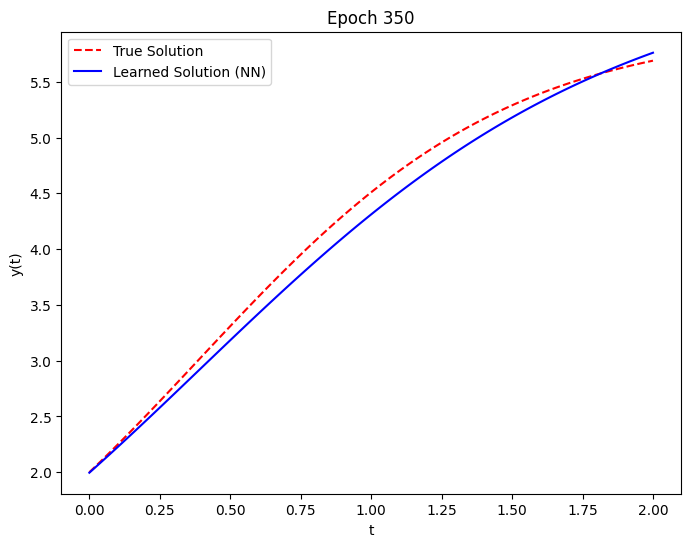

Epoch 400, Test Loss: 0.01164424791932106


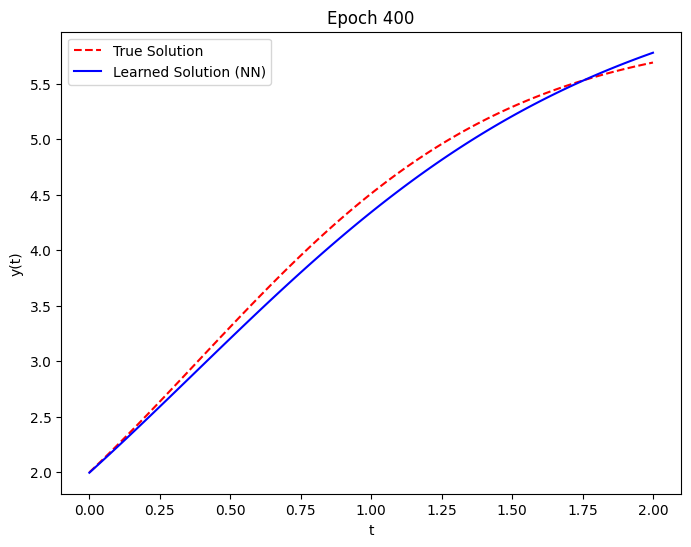

Epoch 450, Test Loss: 0.011203336529433727


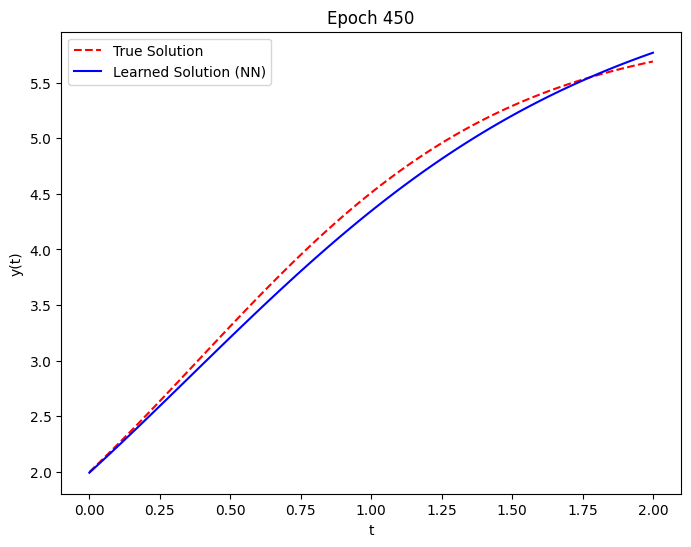

Epoch 500, Test Loss: 0.010755476541817188


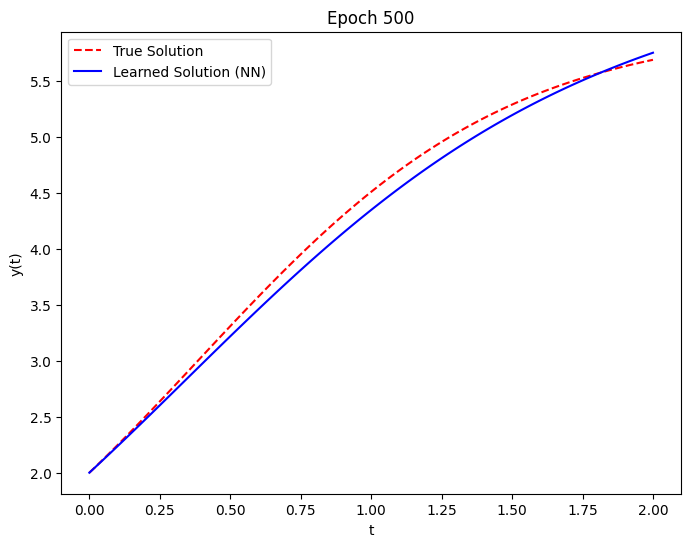

Epoch 550, Test Loss: 0.008502012118697166


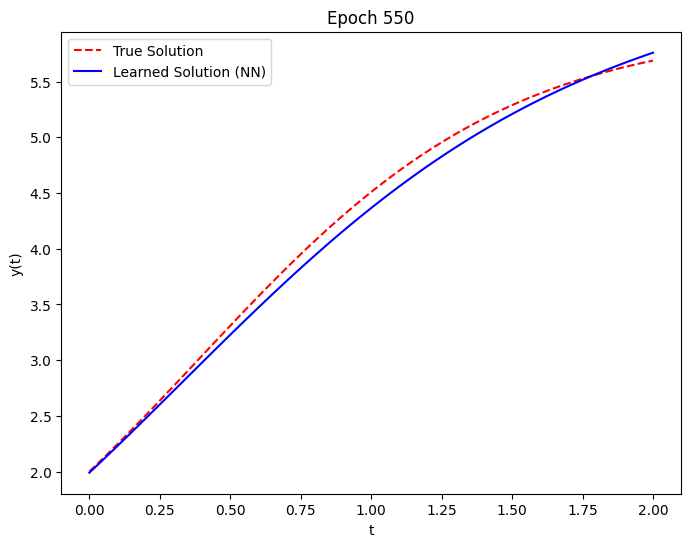

Epoch 600, Test Loss: 0.006492105312645435


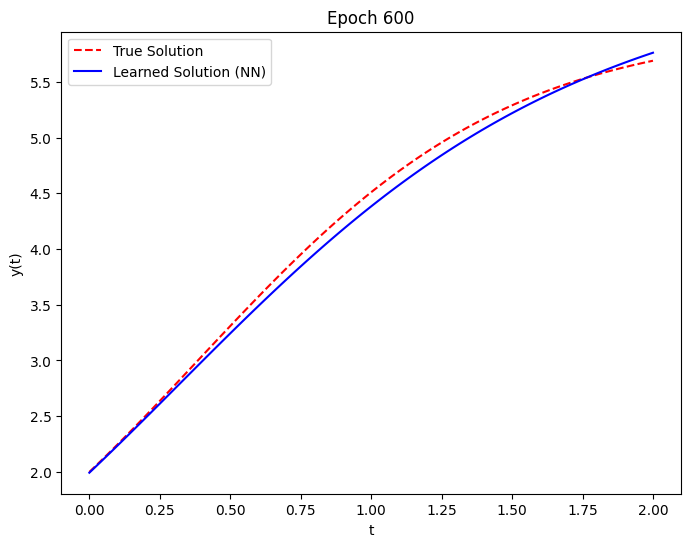

Epoch 650, Test Loss: 0.005459501873701811


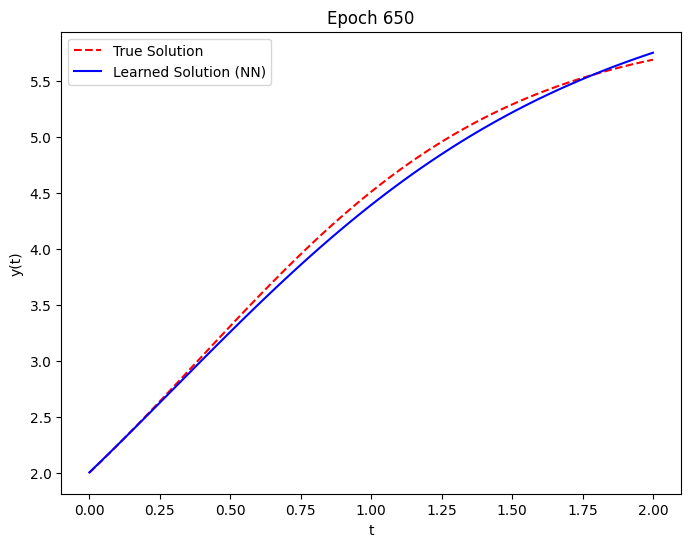

Epoch 700, Test Loss: 0.0042144255712628365


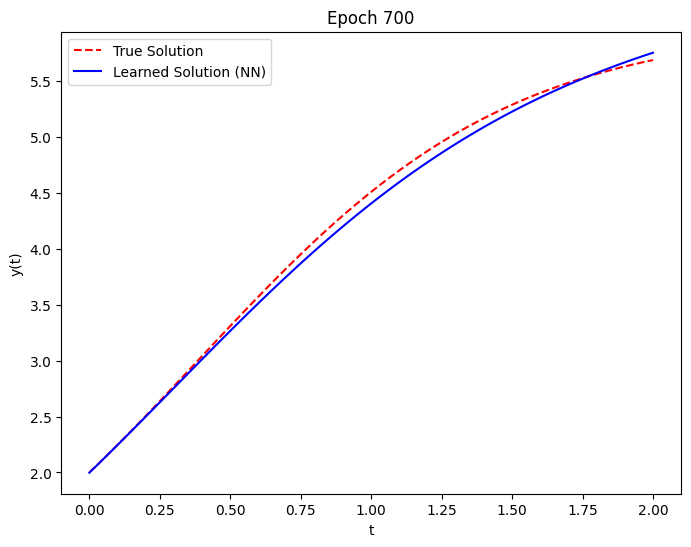

Epoch 750, Test Loss: 0.003915776032954454


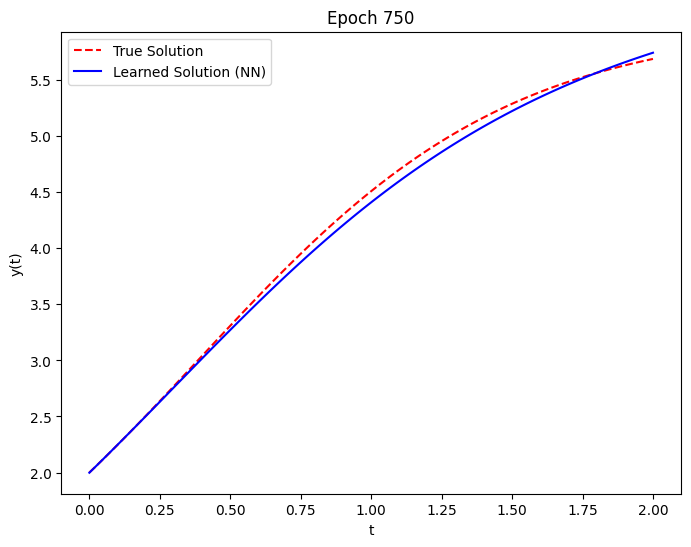

Epoch 800, Test Loss: 0.0034146681427955627


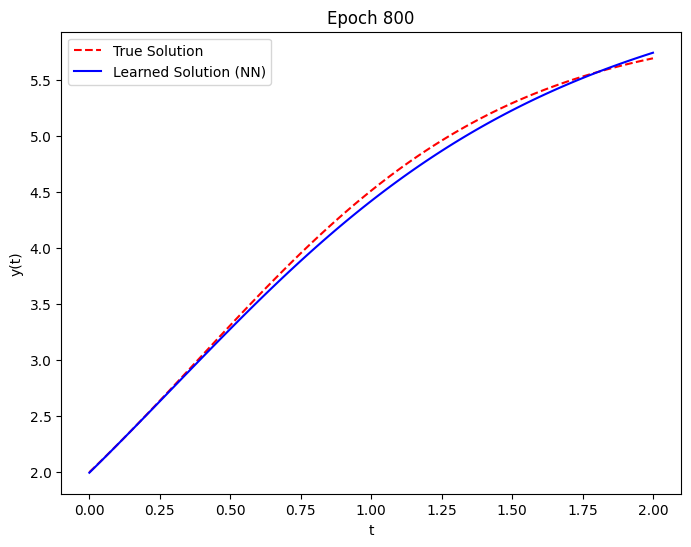

Epoch 850, Test Loss: 0.0025165057741105556


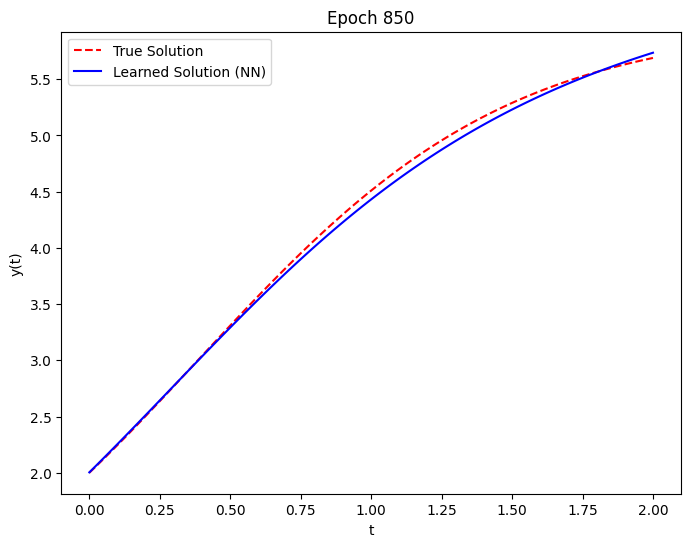

Epoch 900, Test Loss: 0.0017597335390746593


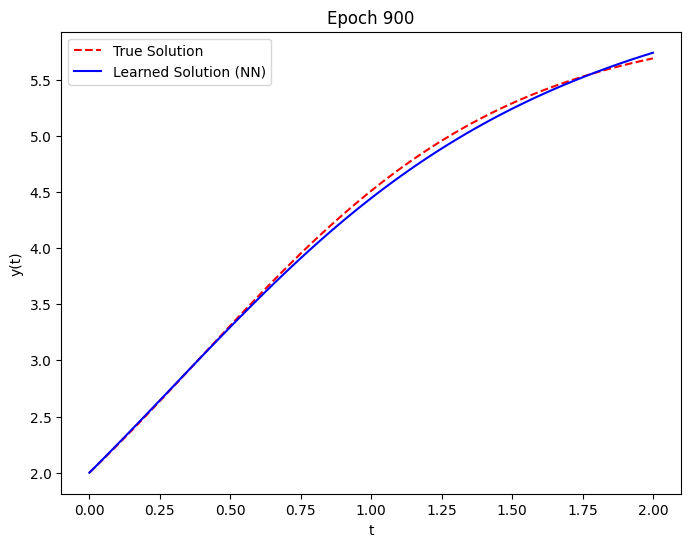

Epoch 950, Test Loss: 0.0013501590583473444


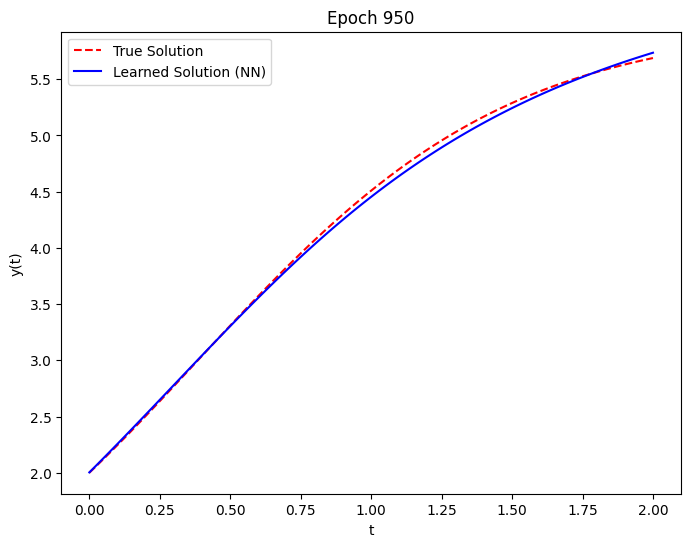

Epoch 1000, Test Loss: 0.0013867091620340943


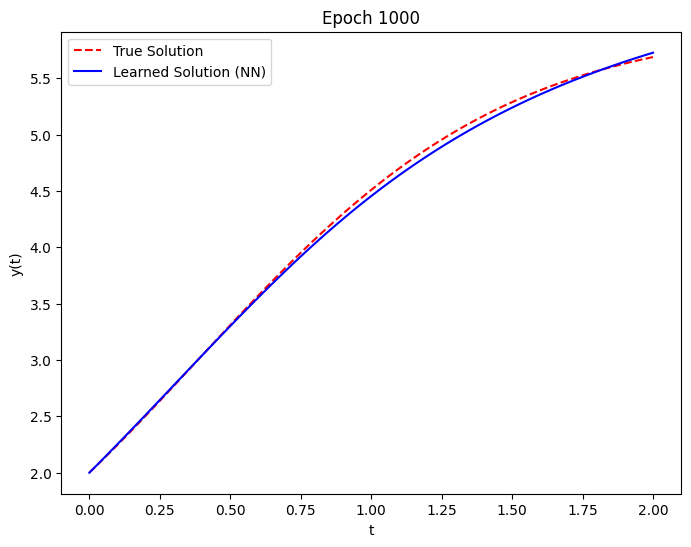

Epoch 1050, Test Loss: 0.0012851604260504246


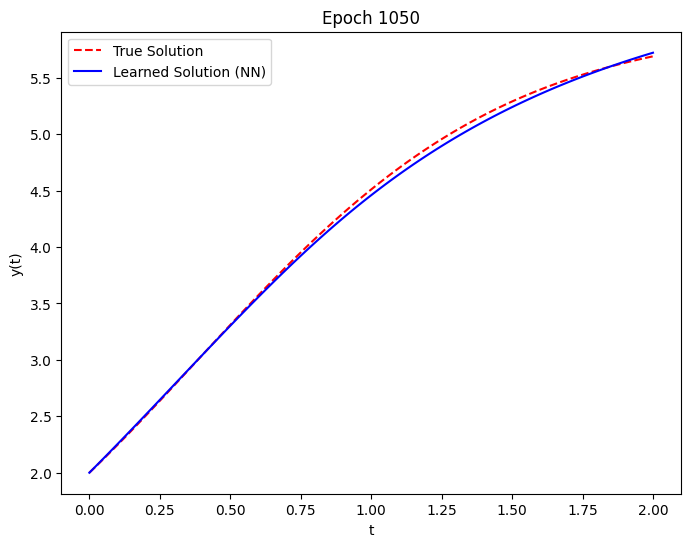

Epoch 1100, Test Loss: 0.0010501618962734938


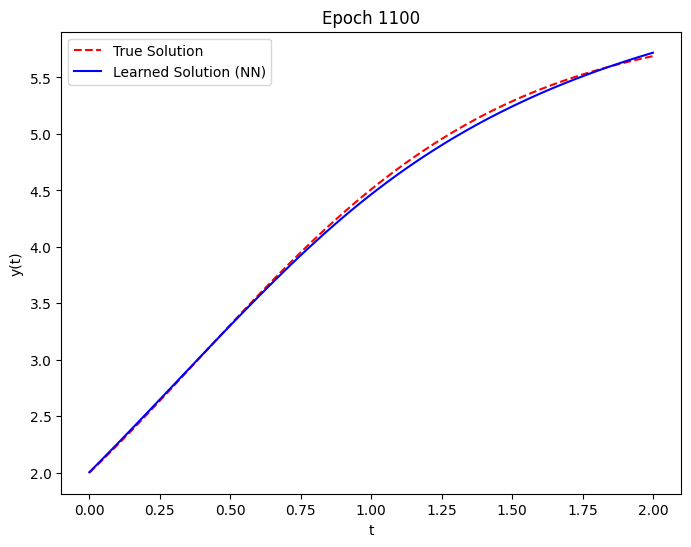

Epoch 1150, Test Loss: 0.00047929384163580835


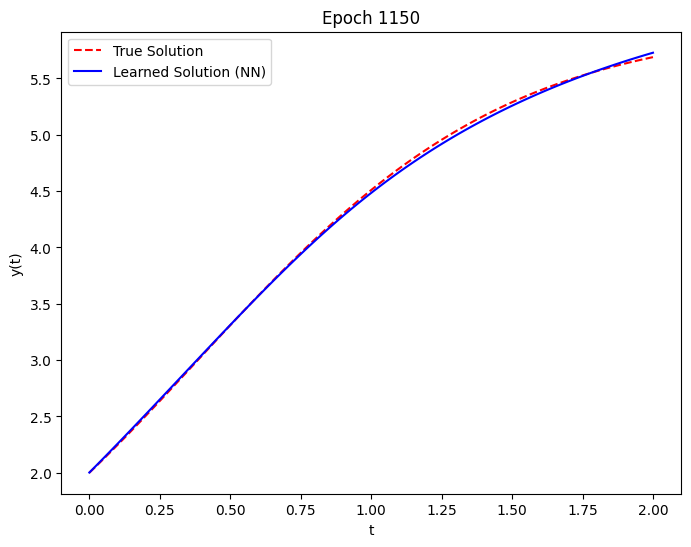

Epoch 1200, Test Loss: 0.0005949939368292689


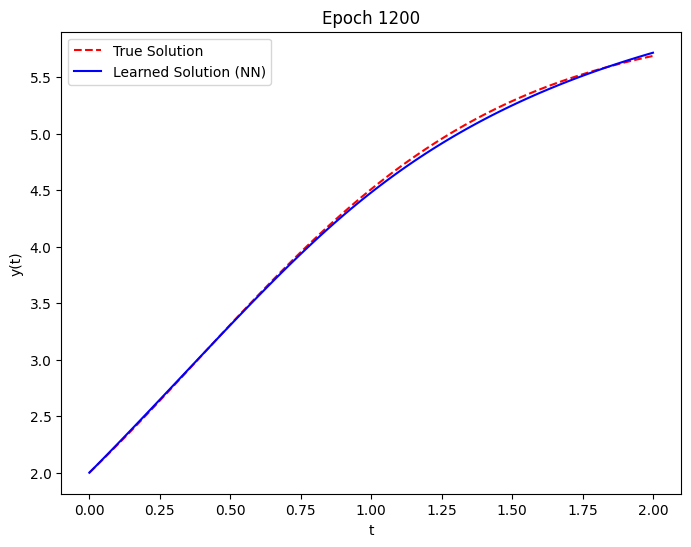

Epoch 1250, Test Loss: 0.0004568131407722831


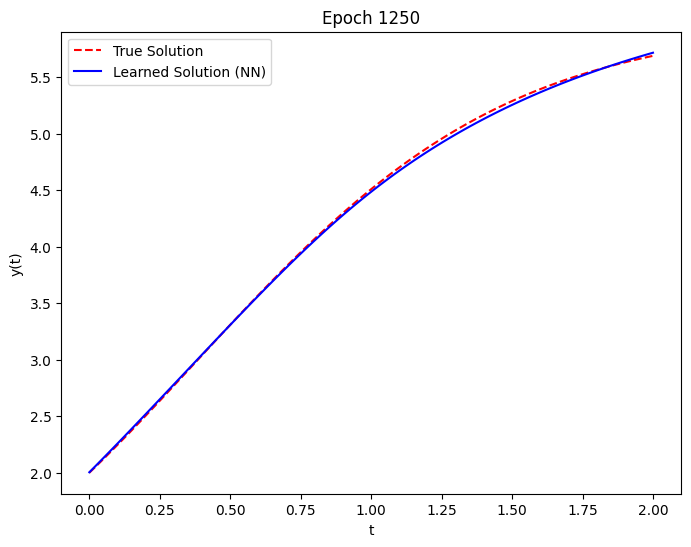

Epoch 1300, Test Loss: 0.000465461693238467


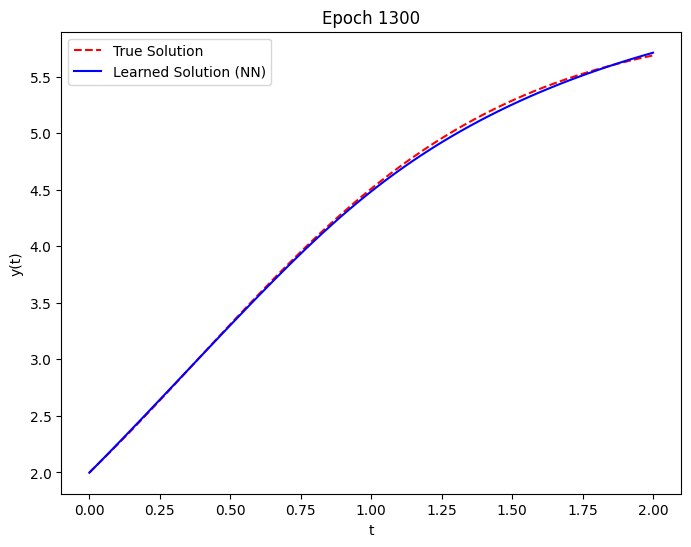

Epoch 1350, Test Loss: 0.00044491354492492974


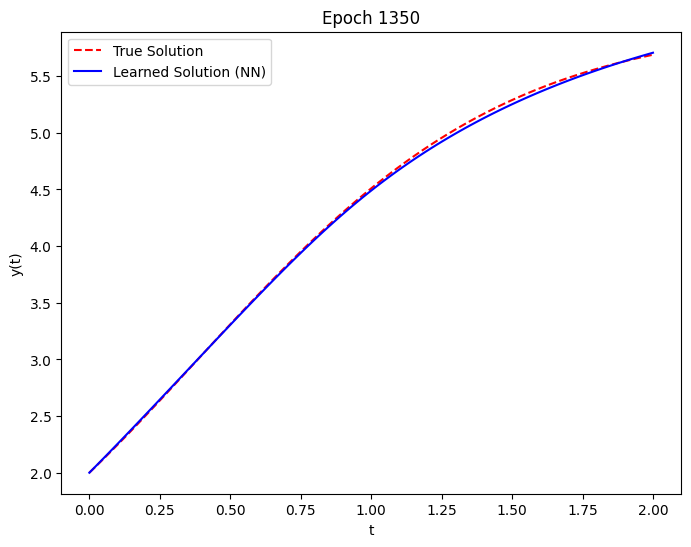

Epoch 1400, Test Loss: 0.0004148898005951196


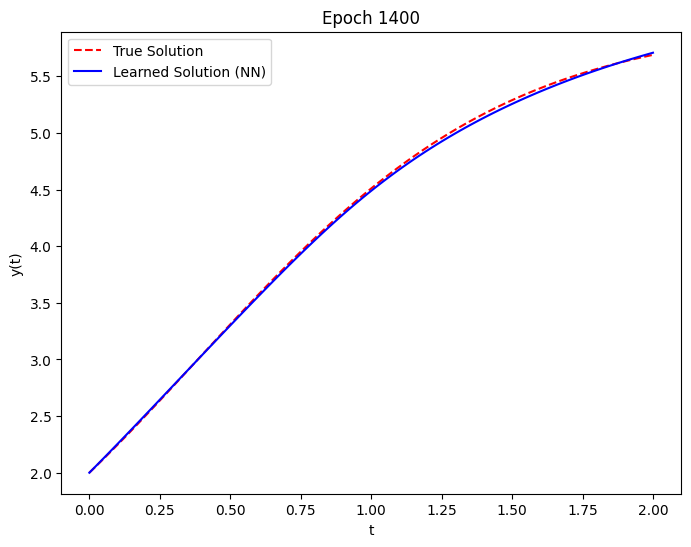

Epoch 1450, Test Loss: 0.00026143851573579013


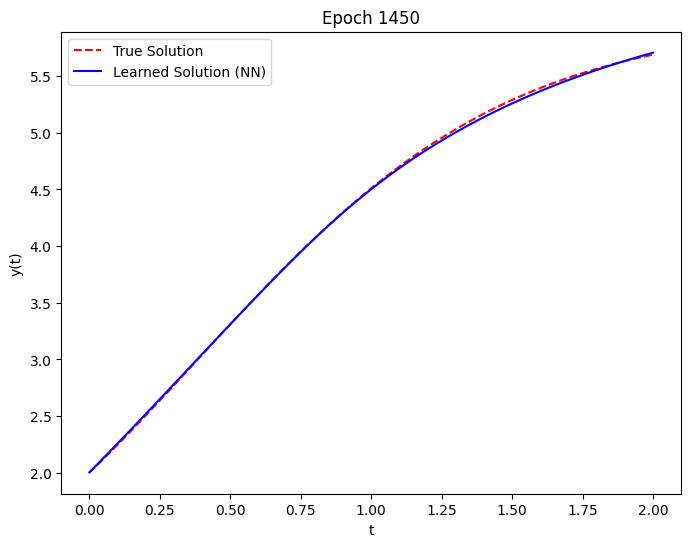

Epoch 1500, Test Loss: 0.0002522776194382459


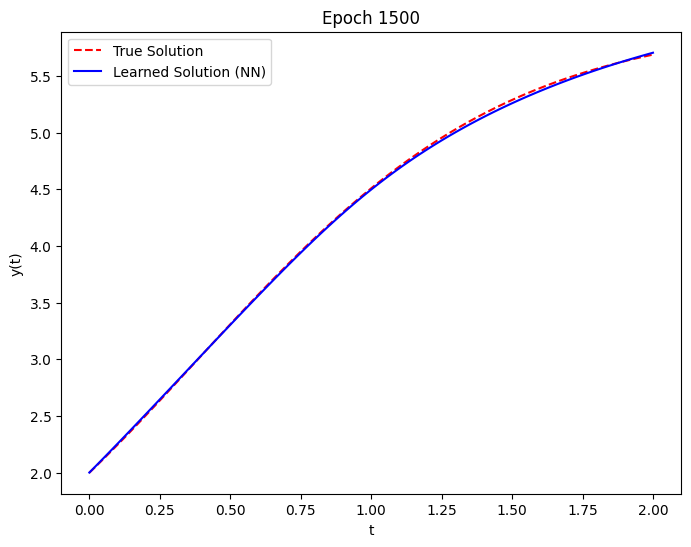

Epoch 1550, Test Loss: 0.00012347927258815616


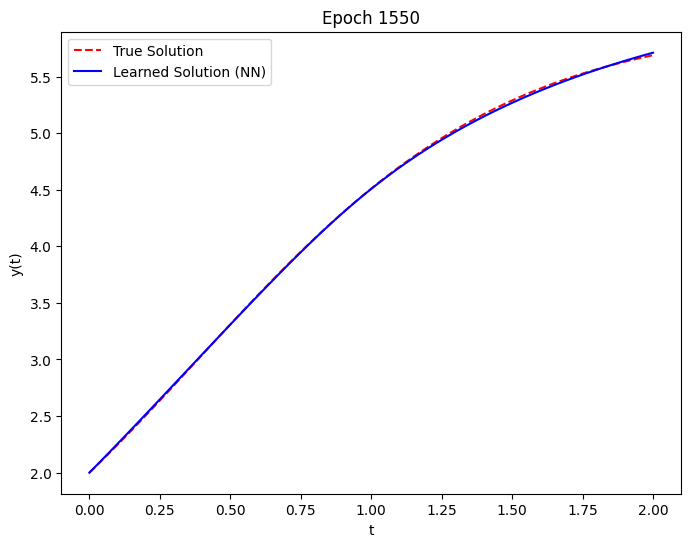

Epoch 1600, Test Loss: 0.00011910427565453574


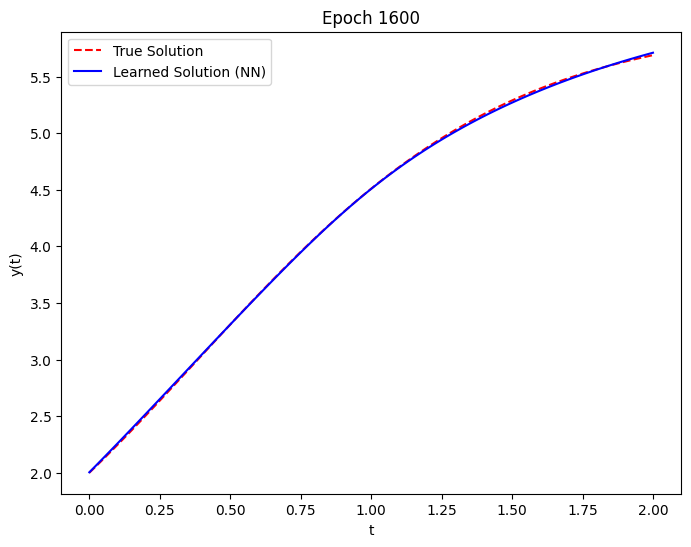

Epoch 1650, Test Loss: 0.00011975492088822648


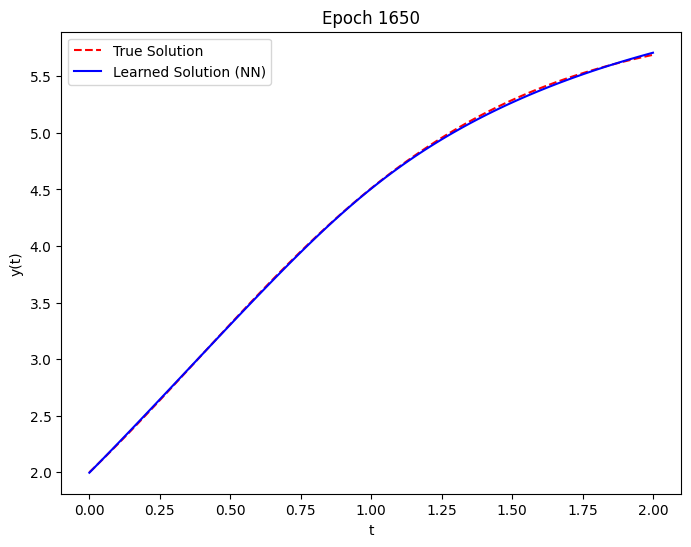

Epoch 1700, Test Loss: 0.0001824731007218361


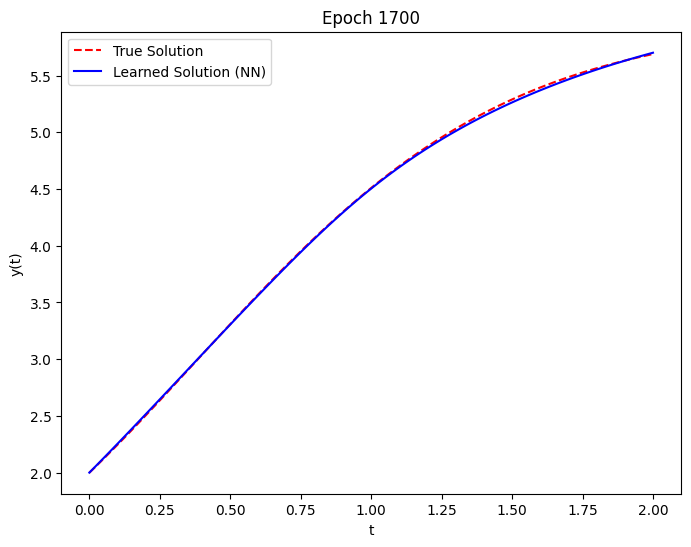

Epoch 1750, Test Loss: 7.635018846485764e-05


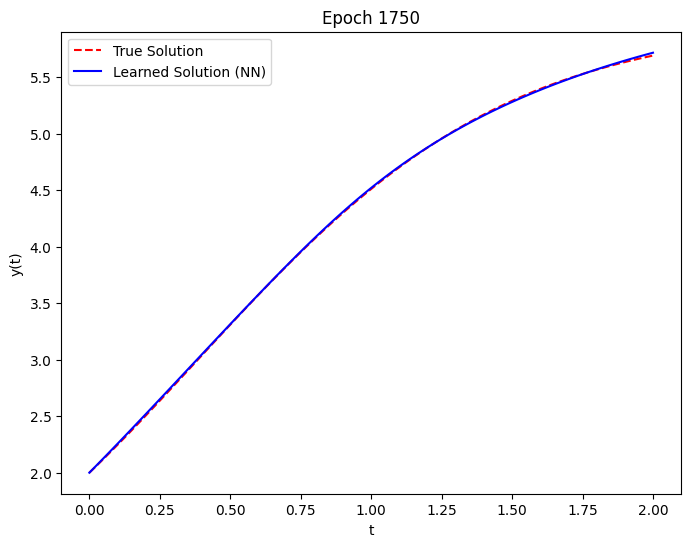

Epoch 1800, Test Loss: 0.000144846155308187


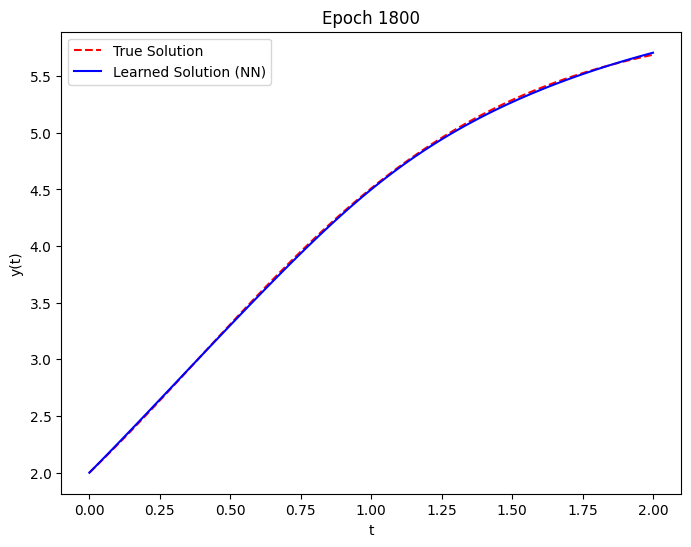

Epoch 1850, Test Loss: 0.00016414241690654308


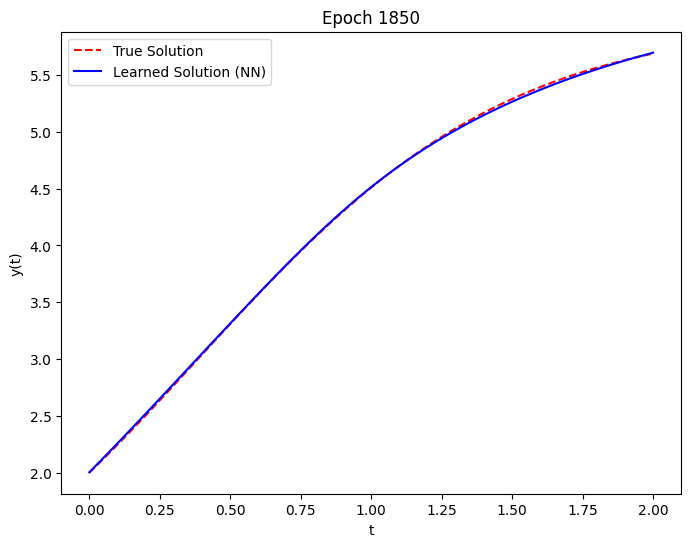

Epoch 1900, Test Loss: 0.00012641835201065987


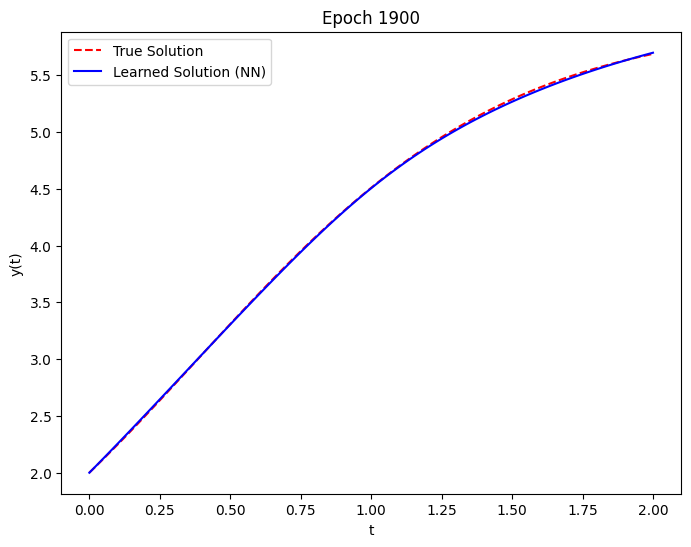

Epoch 1950, Test Loss: 0.0001397901651216671


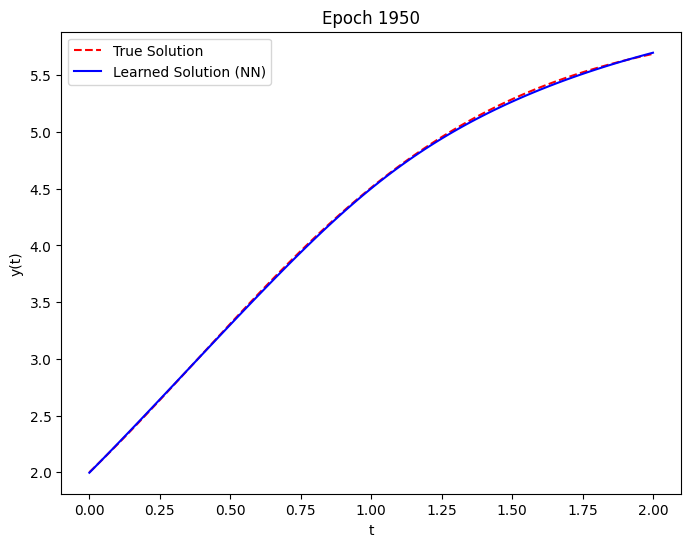

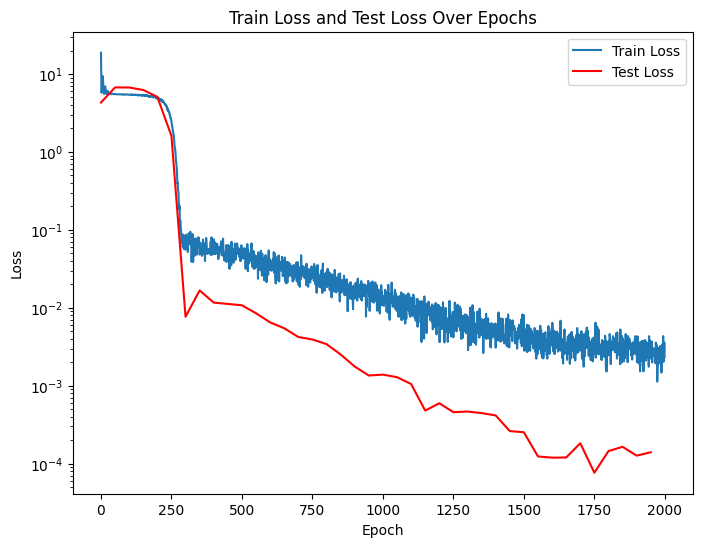

Epoch 0, Test Loss: 0.036532822996377945


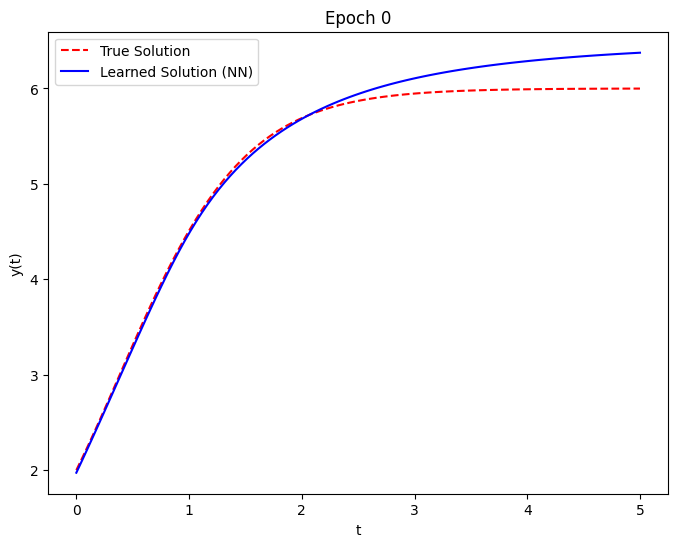

Epoch 50, Test Loss: 0.013810762204229832


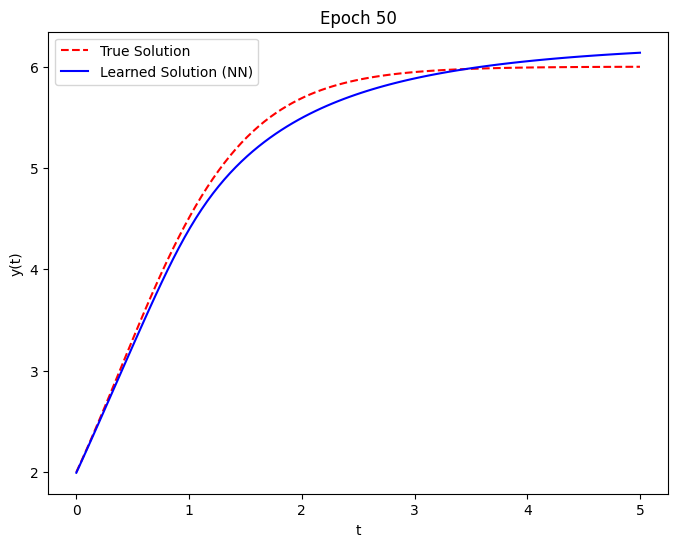

Epoch 100, Test Loss: 0.006535017397254705


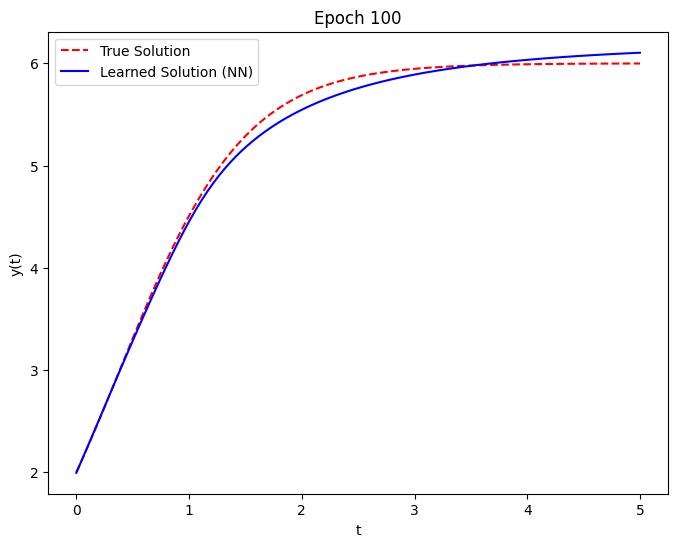

Epoch 150, Test Loss: 0.004697835072875023


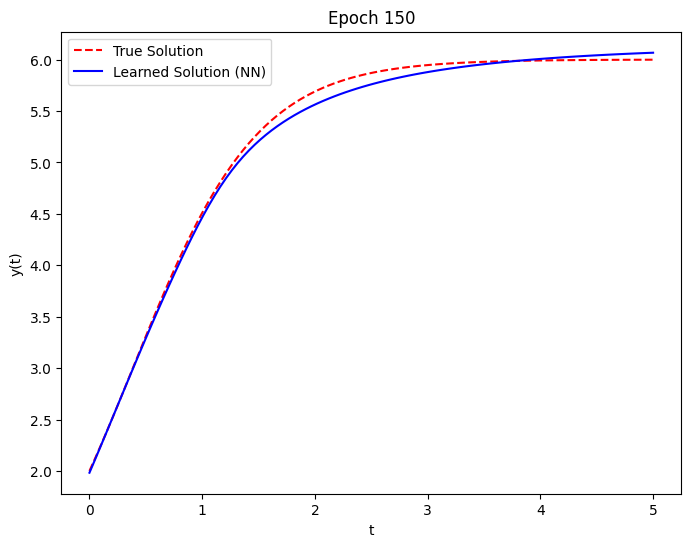

Epoch 200, Test Loss: 0.0027935891412198544


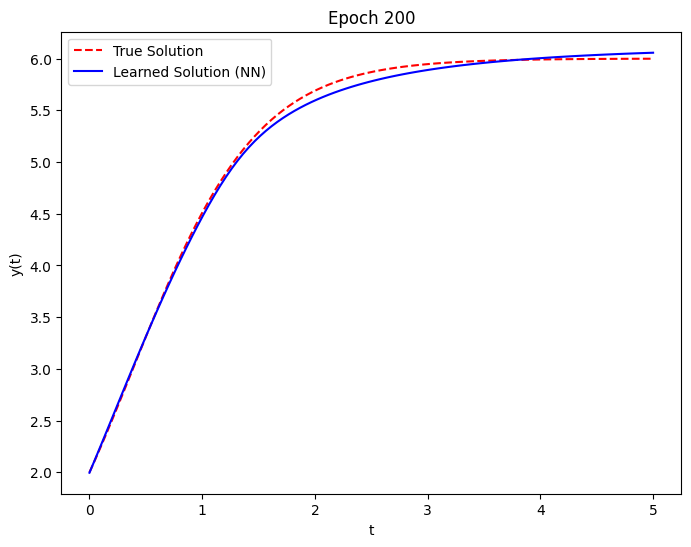

Epoch 250, Test Loss: 0.0014098703395575285


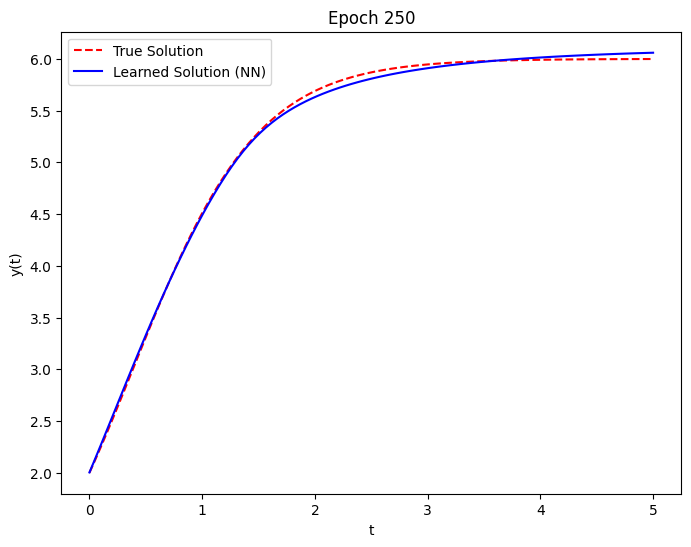

Epoch 300, Test Loss: 0.0009732530452311039


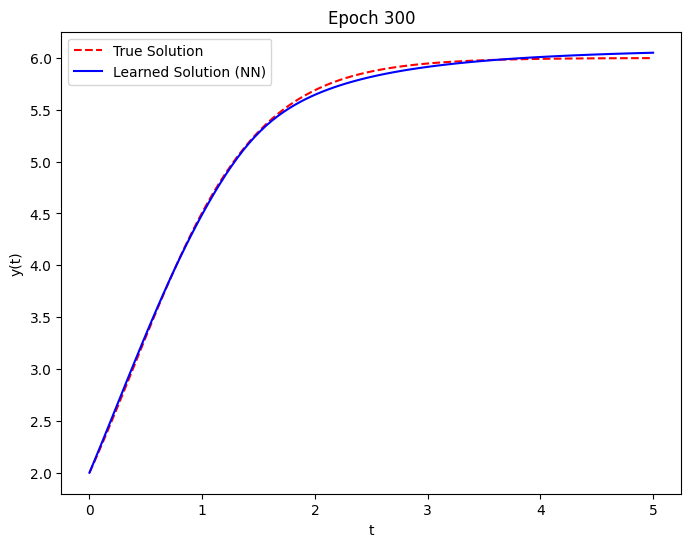

Epoch 350, Test Loss: 0.0008307825773954391


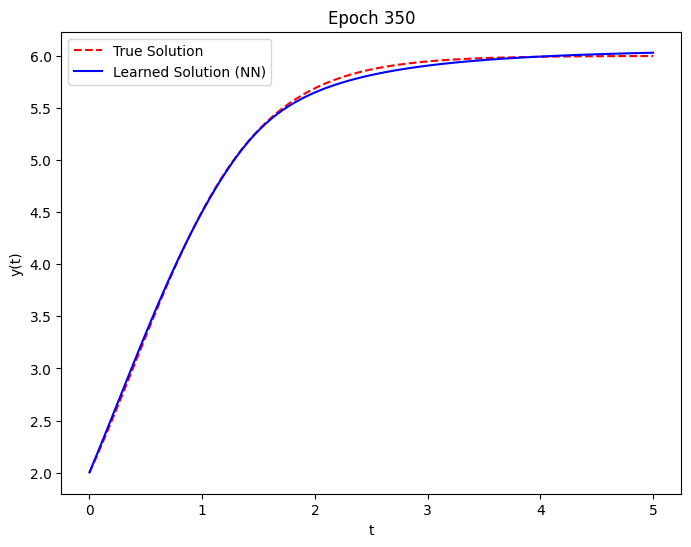

Epoch 400, Test Loss: 0.00044209446059539914


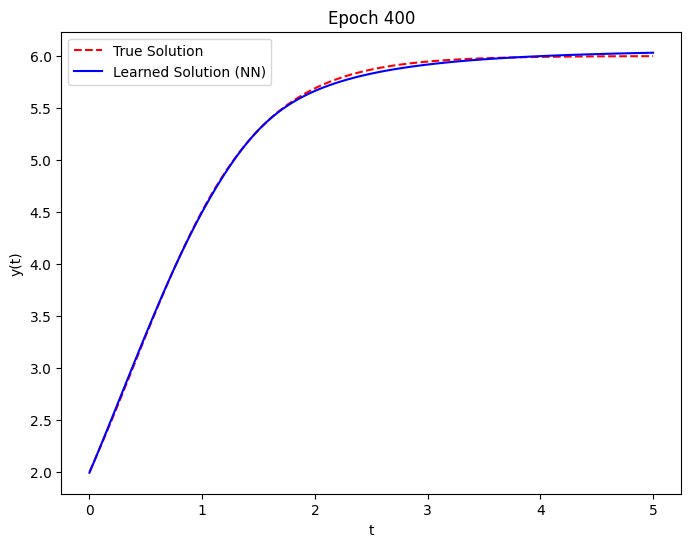

Epoch 450, Test Loss: 0.0002853876503650099


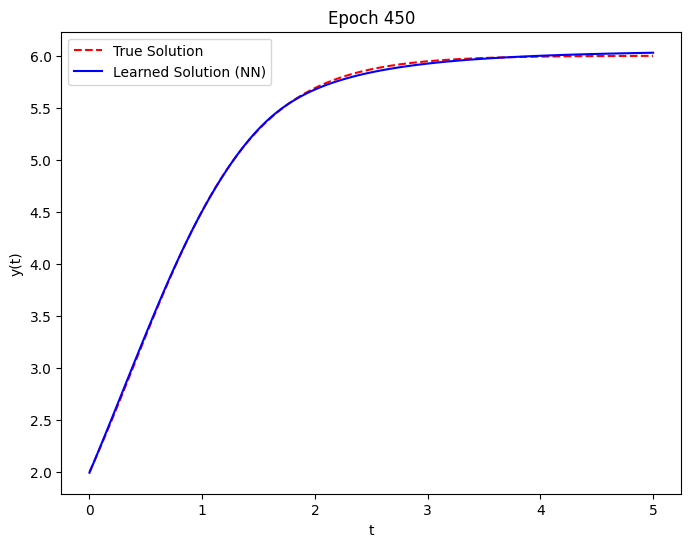

Epoch 500, Test Loss: 0.0002094310475513339


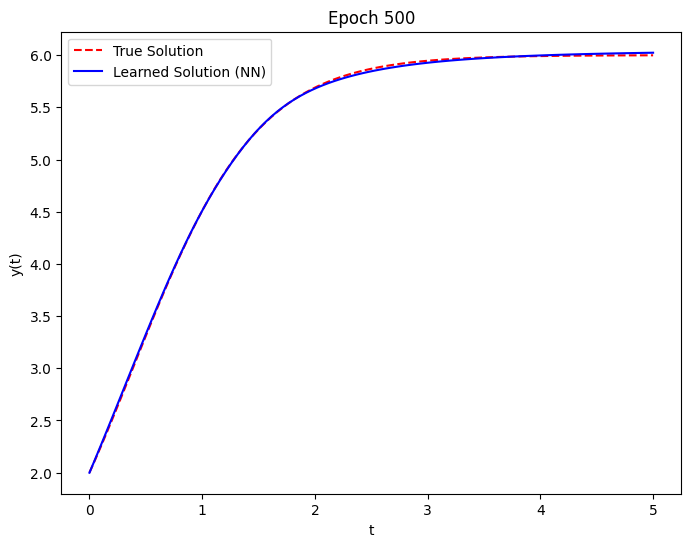

Epoch 550, Test Loss: 0.0001559484371682629


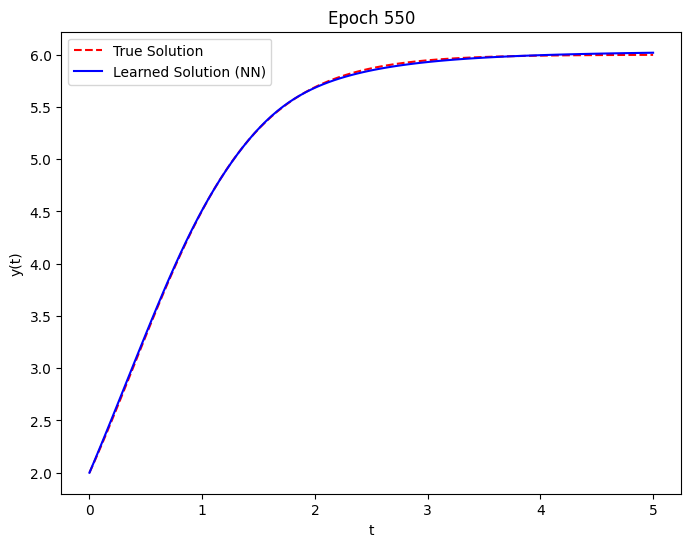

Epoch 600, Test Loss: 0.00012887701450381428


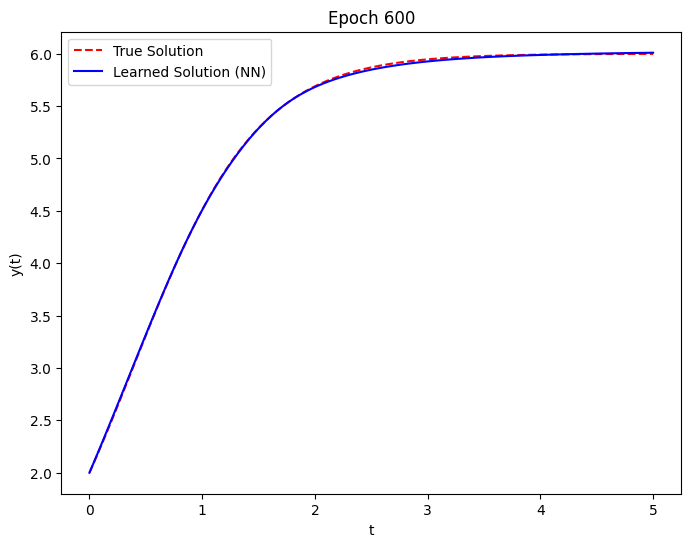

Epoch 650, Test Loss: 7.061626092763618e-05


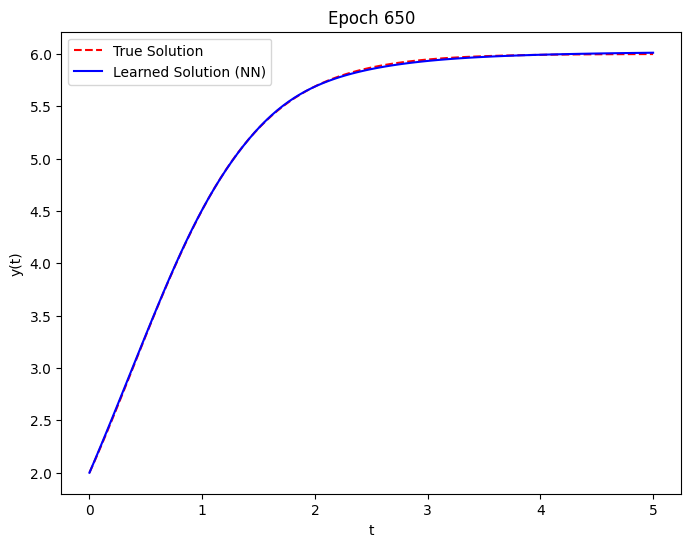

Epoch 700, Test Loss: 4.9374477384844795e-05


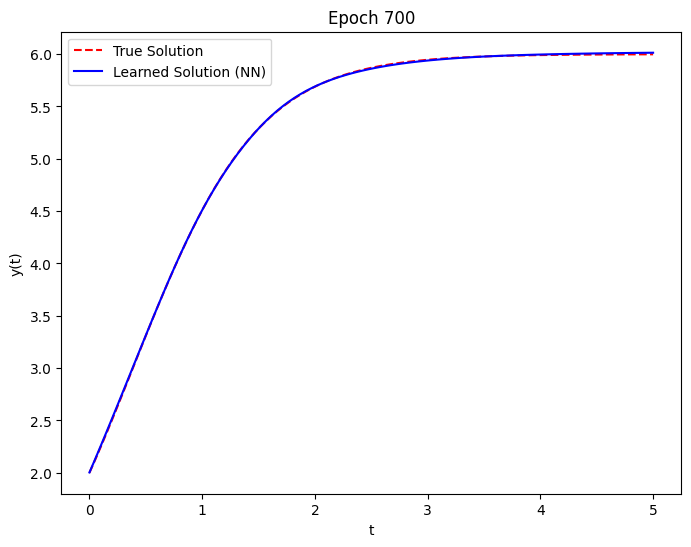

Epoch 750, Test Loss: 3.522249244269915e-05


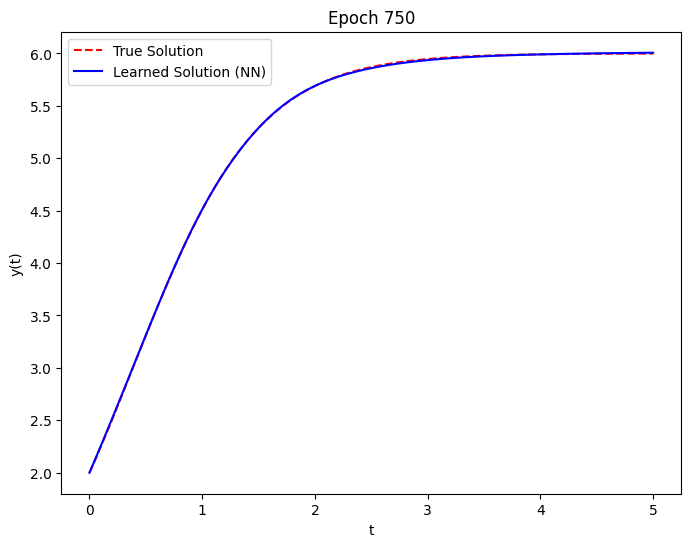

Epoch 800, Test Loss: 2.4988828954519704e-05


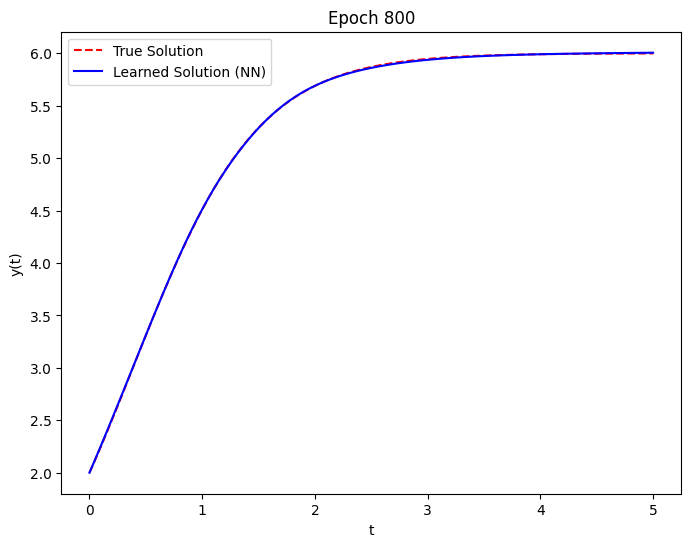

Epoch 850, Test Loss: 1.627097481105011e-05


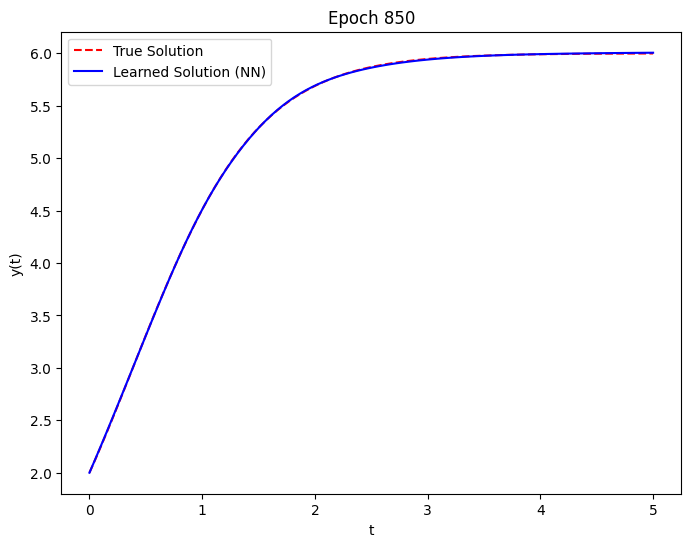

Epoch 900, Test Loss: 1.7001810192596167e-05


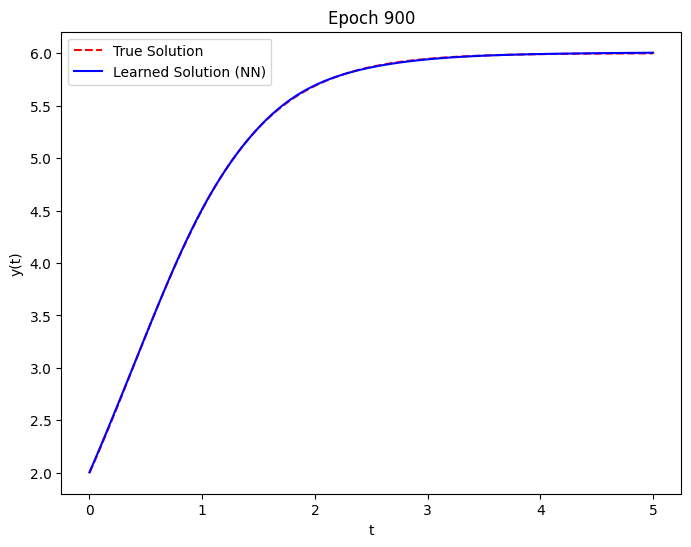

Epoch 950, Test Loss: 1.6792009773780592e-05


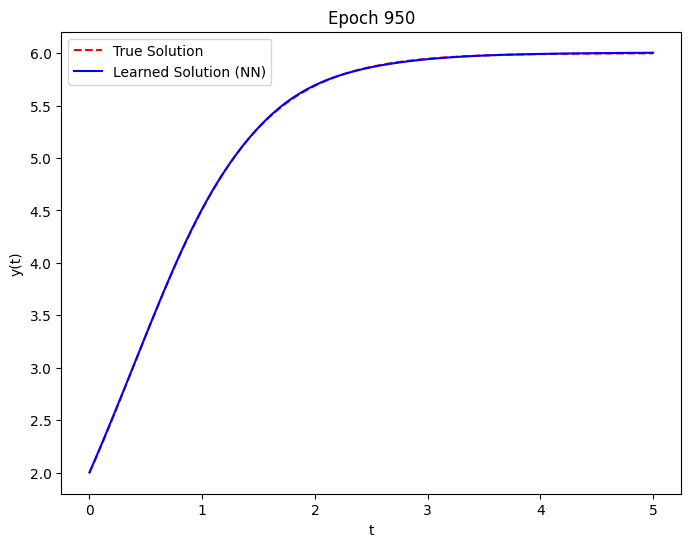

Epoch 1000, Test Loss: 2.6461235393071547e-05


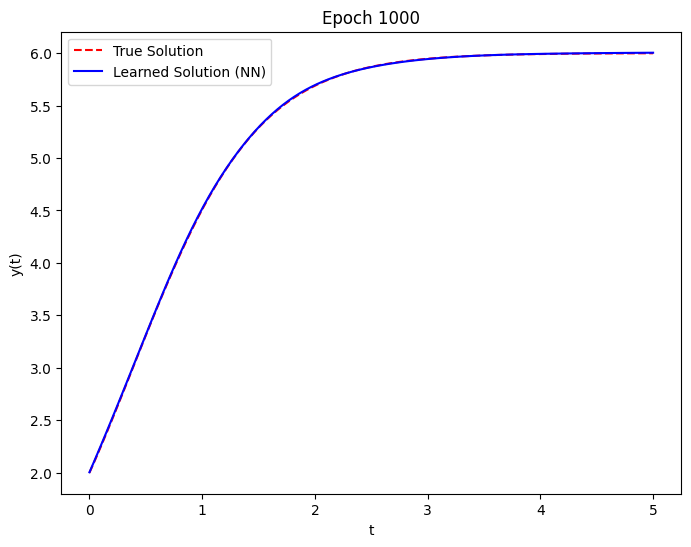

Epoch 1050, Test Loss: 4.767923746840097e-05


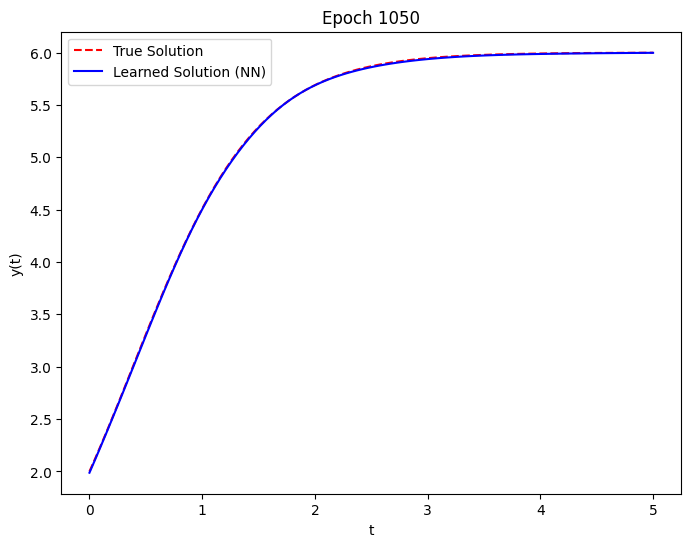

Epoch 1100, Test Loss: 0.00010083401866722852


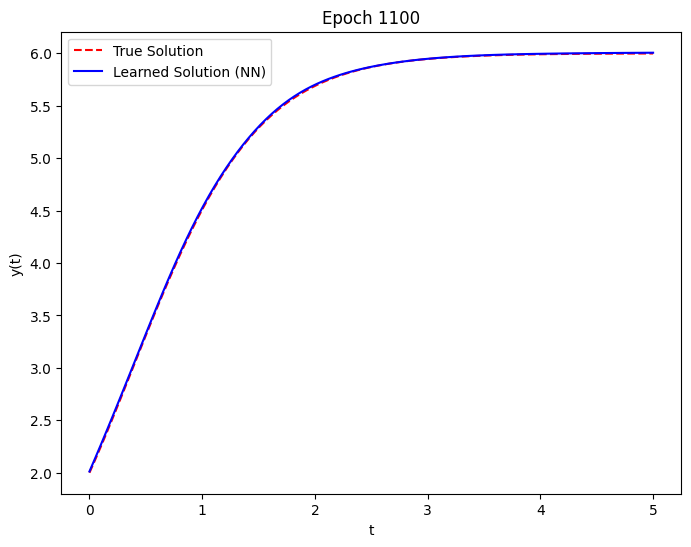

Epoch 1150, Test Loss: 6.2099679780658334e-06


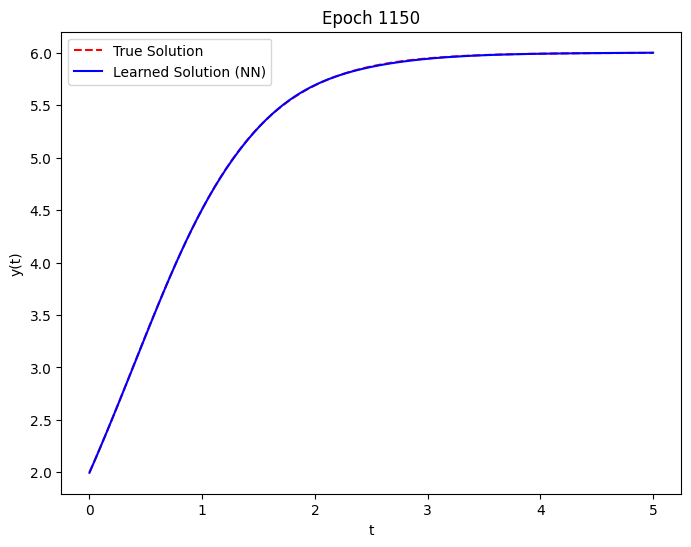

Epoch 1200, Test Loss: 1.1350680324540008e-05


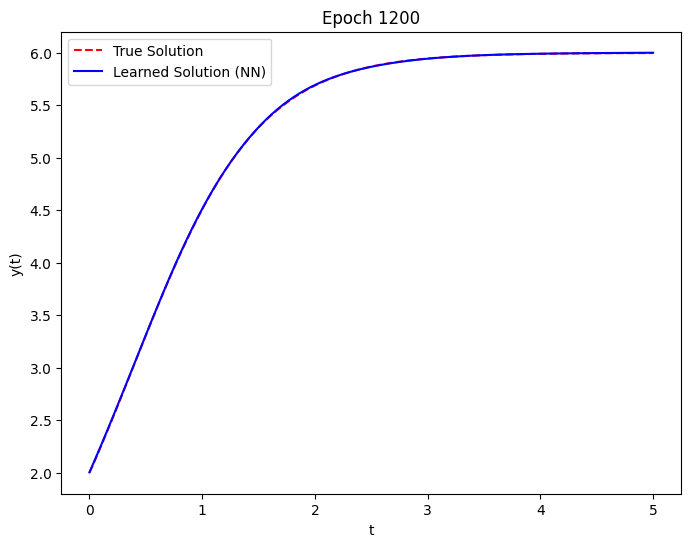

Epoch 1250, Test Loss: 7.989263394847512e-06


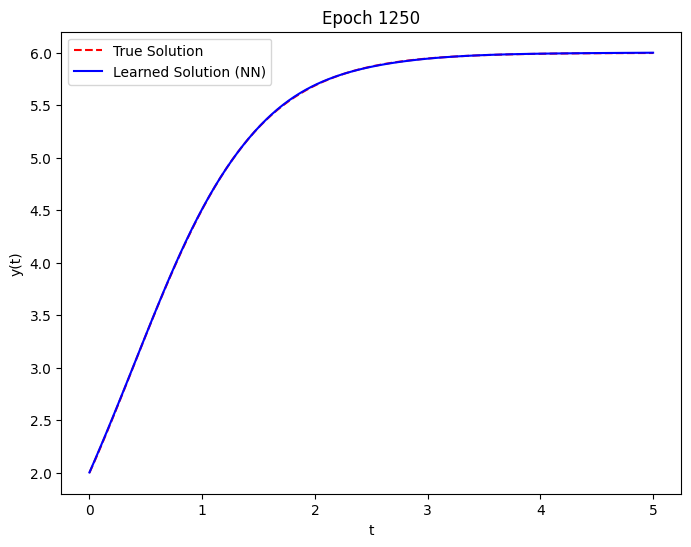

Epoch 1300, Test Loss: 1.6299991330015473e-05


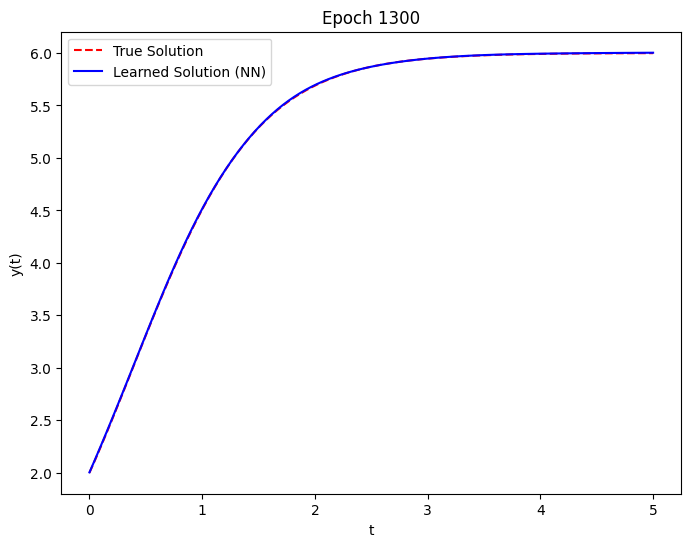

Epoch 1350, Test Loss: 3.1035469874041155e-05


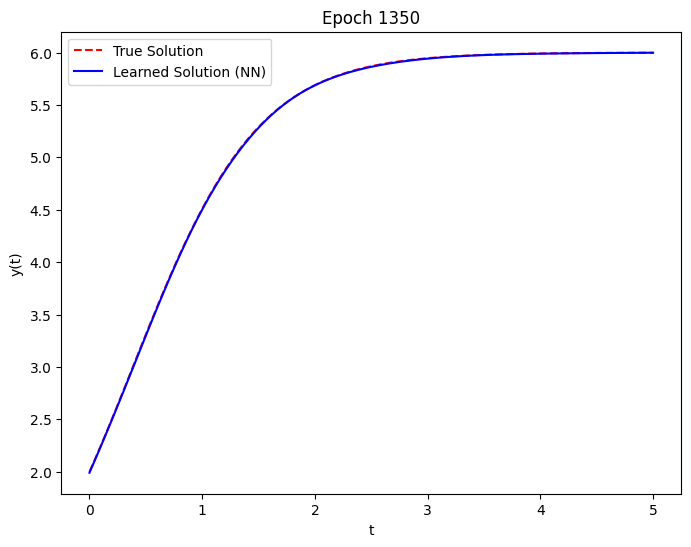

Epoch 1400, Test Loss: 2.498954472685e-06


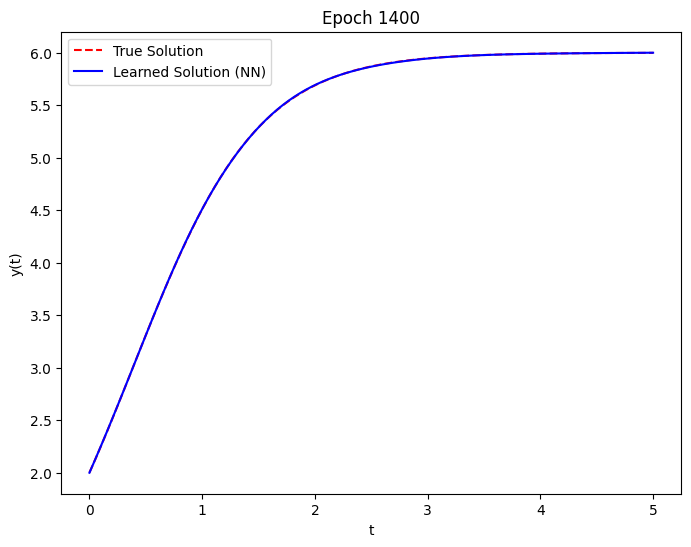

Epoch 1450, Test Loss: 3.395981912035495e-05


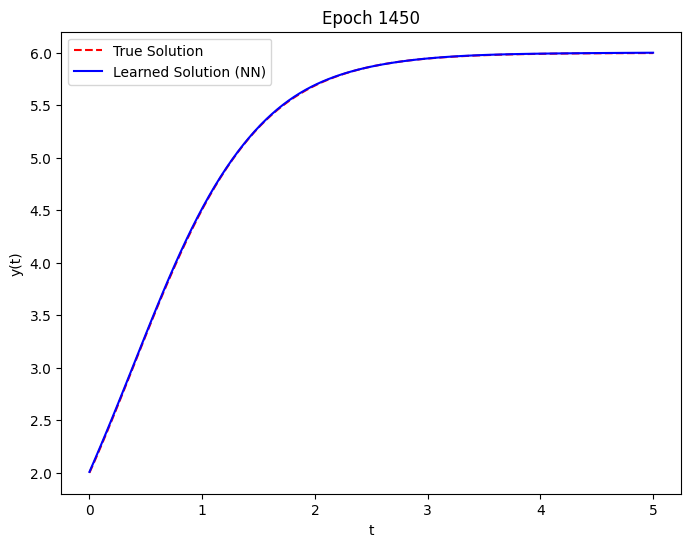

Epoch 1500, Test Loss: 5.81117274123244e-06


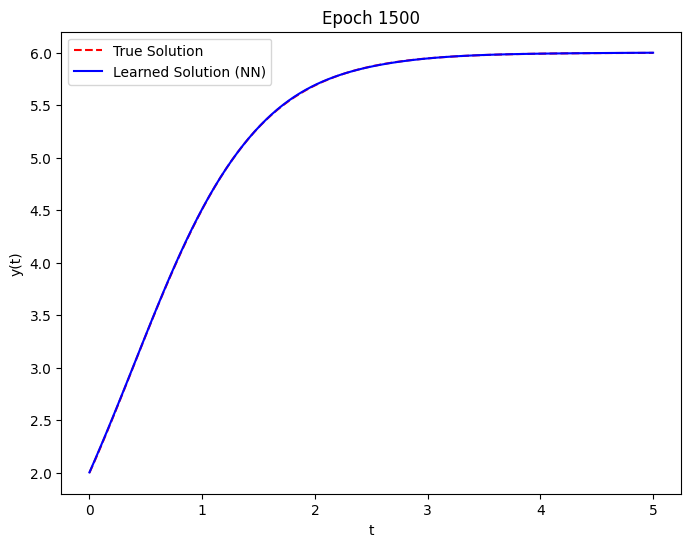

Epoch 1550, Test Loss: 5.102082923258422e-06


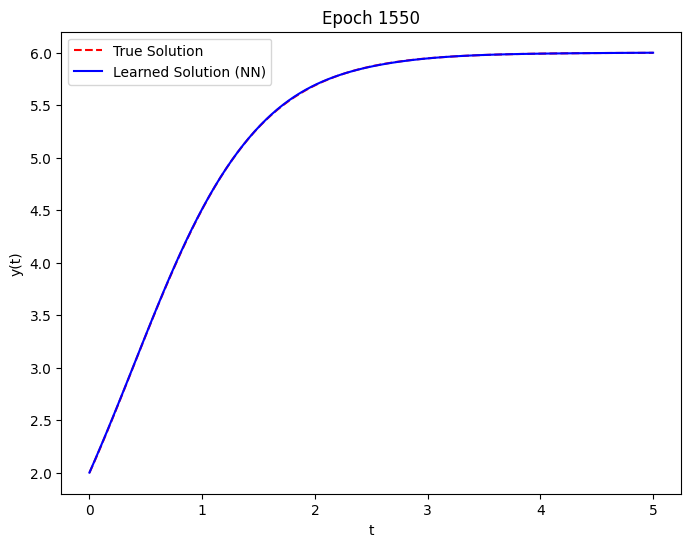

Epoch 1600, Test Loss: 0.0001943703682627529


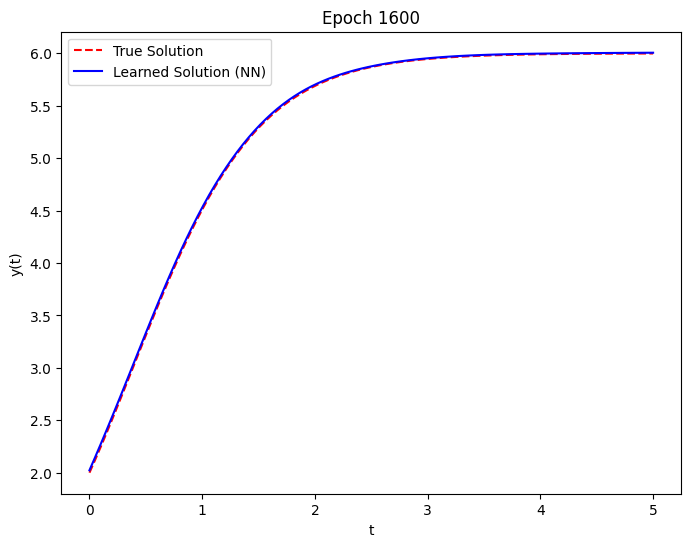

Epoch 1650, Test Loss: 3.920361450582277e-06


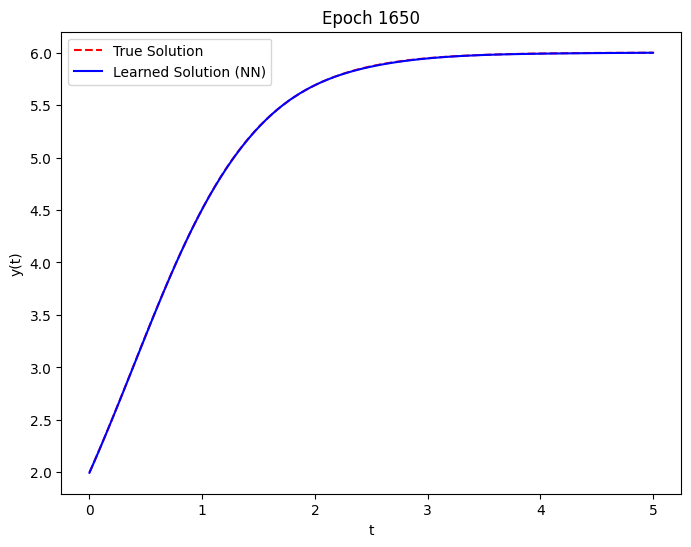

Epoch 1700, Test Loss: 2.7952962682320504e-06


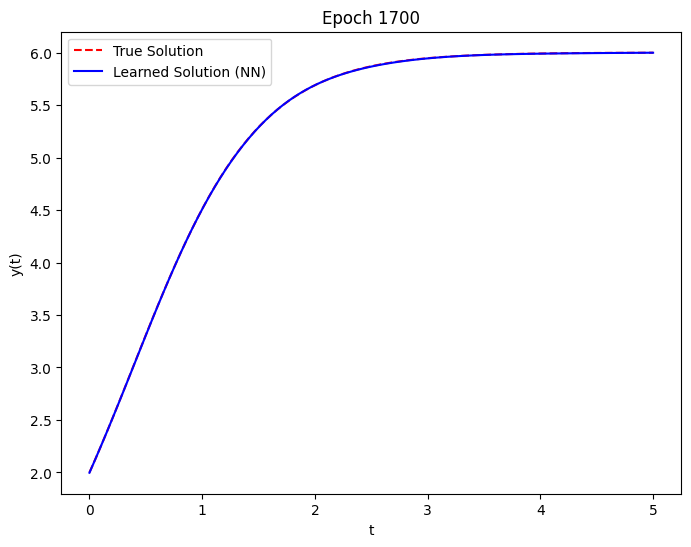

Epoch 1750, Test Loss: 0.00034905539359897375


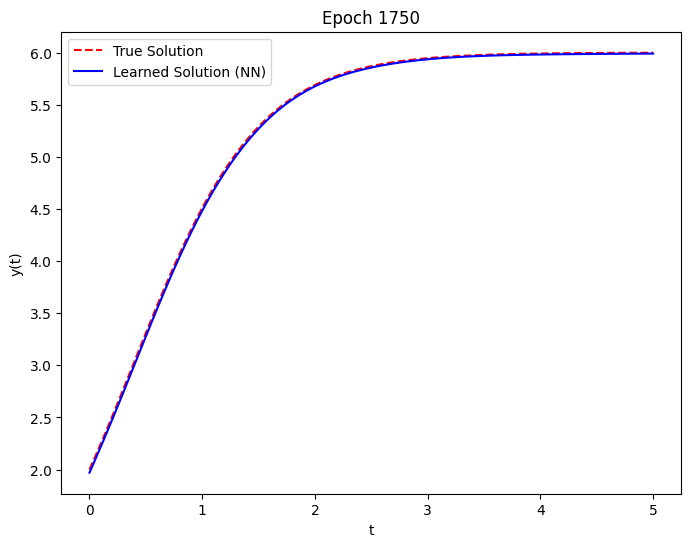

Epoch 1800, Test Loss: 1.1958511549892137e-06


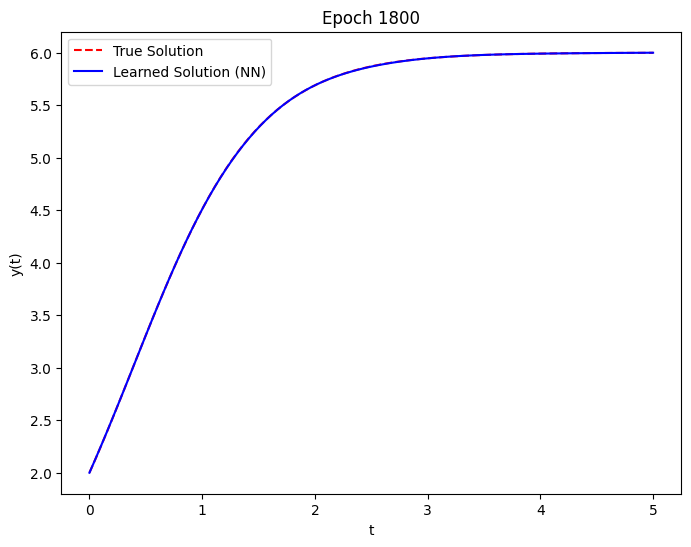

Epoch 1850, Test Loss: 0.0005891139735467732


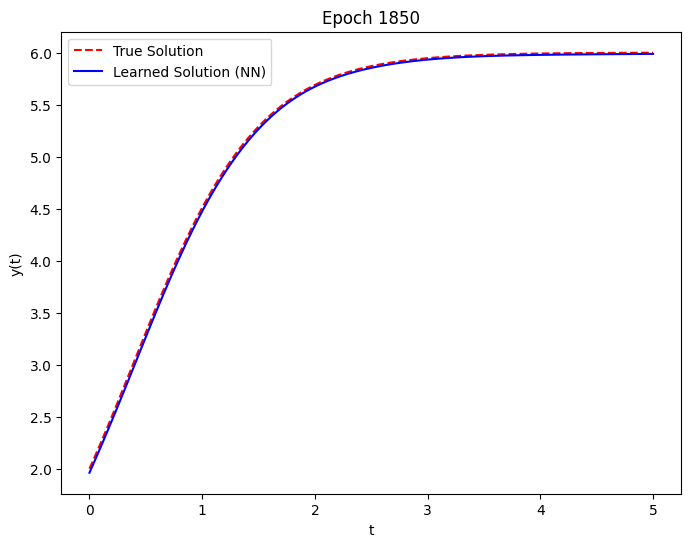

Epoch 1900, Test Loss: 1.0976340263368911e-06


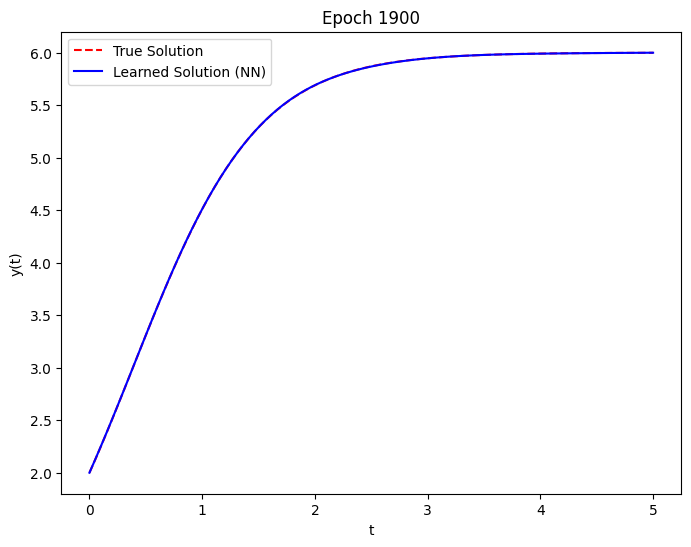

Epoch 1950, Test Loss: 1.3933399714005645e-06


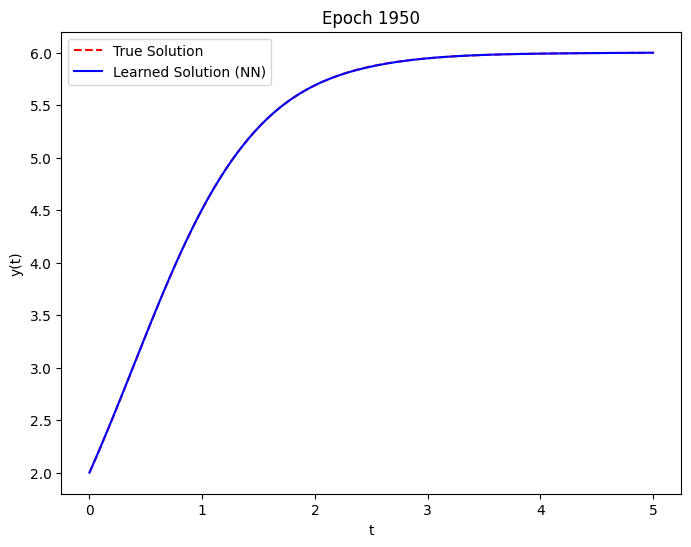

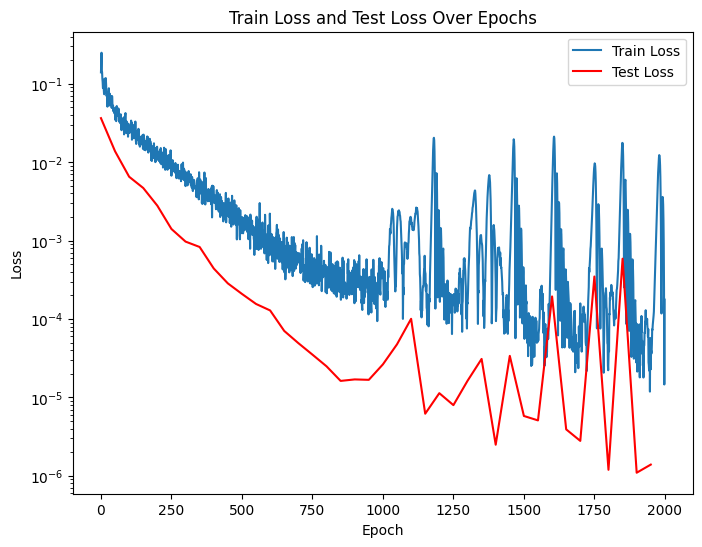

In [28]:
T = 5.0   # Time horizon

# Fix the randomness for reproducibility
set_seed(42)

# Initialize the model
model = NeuralNet()

# Define the optimizer
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Call the function with the parameters
train_ode_solver(M,r,y0,2.0,model,optimizer,num_epochs,batch_size,learning_rate,eval_every,w_ic) #time horizon 2
train_ode_solver(M,r,y0,T,model,optimizer,num_epochs,batch_size,learning_rate,eval_every,w_ic) #time horizon T (do not re-initialize the model)

# Part 2: DGM for PDE

Now we are going to use DGM to solve a PDE.

## First version

In [29]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [30]:
# Define the neural network model
class NeuralNet(nn.Module):
    def __init__(self, hidden_size):
        super(NeuralNet, self).__init__()
        self.fc1 = nn.Linear(2,hidden_size) #linear 2 -> hidden_size Input: (x,t)
        self.fc2 = nn.Linear(hidden_size,hidden_size) #linear hidden_size -> hidden_size
        self.fc3 = nn.Linear(hidden_size,hidden_size) #linear hidden_size -> hidden_size
        self.fc4 = nn.Linear(hidden_size,1) #linear hidden_size -> 1  # Output: u(x,t)
        self.activation = nn.Sigmoid()

    def forward(self, x):
        x = self.activation(self.fc1(x))
        x = self.activation(self.fc2(x))
        x = self.activation(self.fc3(x))
        return self.fc4(x)

In [31]:
# Define the PDE residual for the 1D heat equation: u_t - u_xx = 0
def pde_residual(model, nu, x, t):
    # Enable automatic differentiation
    x.requires_grad_(True)
    t.requires_grad_(True)

    # Stack (x,t) into a single tensor
    inputs = torch.cat([x, t], dim=1)

    # Forward pass to get u(x,t)
    u = model(inputs)

    # Compute gradients
    u_t = torch.autograd.grad(u,t,grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = torch.autograd.grad(u,x,grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x,x,grad_outputs=torch.ones_like(u_x), create_graph=True)[0]

    # Residual of the heat equation
    residual = u_t - nu * u_xx
    return residual

# Define the initial condition loss: u(x, 0) = x(1 - x)
def initial_condition_loss(model, x):
    t_0 = torch.zeros_like(x)  # Time t=0
    inputs = torch.cat([x, t_0], dim=1)
    u_pred = model(inputs)
    u_true = x * (1 - x)
    loss_ic = torch.mean((u_pred - u_true) ** 2)
    return loss_ic

# Define the boundary condition loss: u(0,t) = 0 and u(1,t) = 0
def boundary_condition_loss(model, t):
    x_0 = torch.zeros_like(t)
    x_1 = torch.ones_like(t)
    u_0_pred = model(torch.cat([x_0, t], dim=1))
    u_1_pred = model(torch.cat([x_1, t], dim=1))
    loss_bc = torch.mean((u_0_pred)**2+(u_1_pred)**2)
    return loss_bc


In [39]:
# Training function
def train_pde_solver(t_max, x_max, nu, hidden_size, num_epochs, batch_size, learning_rate, eval_every=100):
    model = NeuralNet(hidden_size)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    total_losses = []
    pde_losses = []
    ic_losses = []
    bc_losses = []

    for epoch in range(num_epochs):
        # Sample random points in the domain (x, t) ∈ [0,1] x [0,1]
        x_batch = x_max * torch.rand(batch_size, 1)  # x in [0, 1]
        t_batch = t_max * torch.rand(batch_size, 1)  # t in [0, 1]

        # Compute losses
        loss_pde = torch.mean(pde_residual(model, nu, x_batch, t_batch)**2)
        #We alreday calculated the mean of ic and bc but pde_residuals returns individual residuals
        loss_ic = initial_condition_loss(model, x_batch)
        loss_bc = boundary_condition_loss(model, t_batch)
        loss = loss_pde + loss_ic + loss_bc

        # Backpropagation and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Record losses
        total_losses.append(loss.item())
        pde_losses.append(loss_pde.item())
        ic_losses.append(loss_ic.item())
        bc_losses.append(loss_bc.item())

        # Print progress with each loss component
        if epoch % eval_every == 0:
            print(f"Epoch {epoch}, Total Loss: {loss.item():.6f}, PDE Loss: {loss_pde.item():.6f}, IC Loss: {loss_ic.item():.6f}, BC Loss: {loss_bc.item():.6f}")

    return model, total_losses, pde_losses, ic_losses, bc_losses

# Plot the solution with a heatmap and 3D surface
def plot_solution(model, t_max, x_max, num_points=100):
    x_vals = torch.linspace(0, x_max, num_points).unsqueeze(1)
    t_vals = torch.linspace(0, t_max, num_points).unsqueeze(1)

    X, T = torch.meshgrid(x_vals.squeeze(), t_vals.squeeze())
    X_flat = X.reshape(-1, 1)
    T_flat = T.reshape(-1, 1)

    with torch.no_grad():
        U_flat = model(torch.cat([X_flat, T_flat], dim=1)).numpy()

    U = U_flat.reshape(num_points, num_points)

    # Create a figure with two subplots: heatmap and 3D surface plot
    fig = plt.figure(figsize=(14, 6))

    # Heatmap
    ax1 = fig.add_subplot(1, 2, 1)
    heatmap = ax1.contourf(X.numpy(), T.numpy(), U, levels=100, cmap="viridis")
    fig.colorbar(heatmap, ax=ax1, label="u(x,t)")
    ax1.set_xlabel("x")
    ax1.set_ylabel("t")
    ax1.set_title("Heatmap of u(x,t)")

    # 3D Surface plot
    ax2 = fig.add_subplot(1, 2, 2, projection='3d')
    ax2.plot_surface(X.numpy(), T.numpy(), U, cmap="viridis")
    ax2.set_xlabel("x")
    ax2.set_ylabel("t")
    ax2.set_zlabel("u(x,t)")
    ax2.set_title("3D Surface Plot of u(x,t)")

    plt.tight_layout()
    plt.show()

# Plot the losses vs iterations
def plot_losses(total_losses, pde_losses, ic_losses, bc_losses, eval_every, w=1):
    # Function to compute a moving average with window size w
    def moving_average(x, w):
      return np.convolve(x, np.ones(w), 'valid') / w

    iterations = range(len(total_losses))

    plt.figure(figsize=(10, 6))

    # Plot the total loss and each component
    plt.semilogy(iterations[w-1:], moving_average(total_losses, w), label="Total Loss", linestyle='-', color='b')
    plt.semilogy(iterations[w-1:], moving_average(pde_losses, w), label="PDE Loss", linestyle='--', color='g')
    plt.semilogy(iterations[w-1:], moving_average(ic_losses, w), label="Initial Condition Loss", linestyle='-.', color='r')
    plt.semilogy(iterations[w-1:], moving_average(bc_losses, w), label="Boundary Condition Loss", linestyle=':', color='m')

    plt.xlabel("Iterations")
    plt.ylabel("Loss")
    plt.title(f"Loss vs Iterations (smoothed with w={w})")
    plt.legend()
    plt.grid(True)
    plt.show()

In [34]:
# Parameters
T = 1.0 # time horizon
x_max = 1.0 # largest value of x in the domain
sigma = 0.5 # viscosity coefficient
nu = sigma**2 / 2 # coefficient in the PDE

# Hyperparameters
hidden_size = 200
num_epochs = 10000
batch_size = 64
learning_rate = 1e-3
eval_every = 100

# Train the model
model, total_losses, pde_losses, ic_losses, bc_losses = train_pde_solver(
    T, x_max, nu,
    hidden_size, num_epochs, batch_size, learning_rate, eval_every)

Epoch 0, Total Loss: 0.026031, PDE Loss: 0.000000, IC Loss: 0.016183, BC Loss: 0.009848
Epoch 100, Total Loss: 0.022886, PDE Loss: 0.000354, IC Loss: 0.016542, BC Loss: 0.005990
Epoch 200, Total Loss: 0.021138, PDE Loss: 0.001650, IC Loss: 0.013667, BC Loss: 0.005821
Epoch 300, Total Loss: 0.019612, PDE Loss: 0.001833, IC Loss: 0.012773, BC Loss: 0.005006
Epoch 400, Total Loss: 0.020326, PDE Loss: 0.001736, IC Loss: 0.016197, BC Loss: 0.002393
Epoch 500, Total Loss: 0.021374, PDE Loss: 0.001722, IC Loss: 0.012379, BC Loss: 0.007273
Epoch 600, Total Loss: 0.021215, PDE Loss: 0.001677, IC Loss: 0.016192, BC Loss: 0.003345
Epoch 700, Total Loss: 0.021464, PDE Loss: 0.001882, IC Loss: 0.011298, BC Loss: 0.008283
Epoch 800, Total Loss: 0.022587, PDE Loss: 0.001963, IC Loss: 0.016932, BC Loss: 0.003692
Epoch 900, Total Loss: 0.019393, PDE Loss: 0.002015, IC Loss: 0.013504, BC Loss: 0.003875
Epoch 1000, Total Loss: 0.021898, PDE Loss: 0.002170, IC Loss: 0.011555, BC Loss: 0.008172
Epoch 1100,

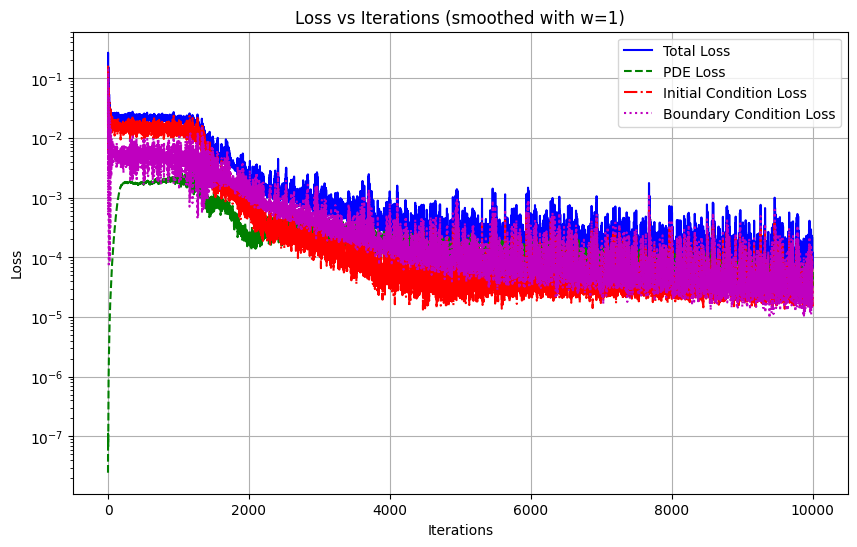

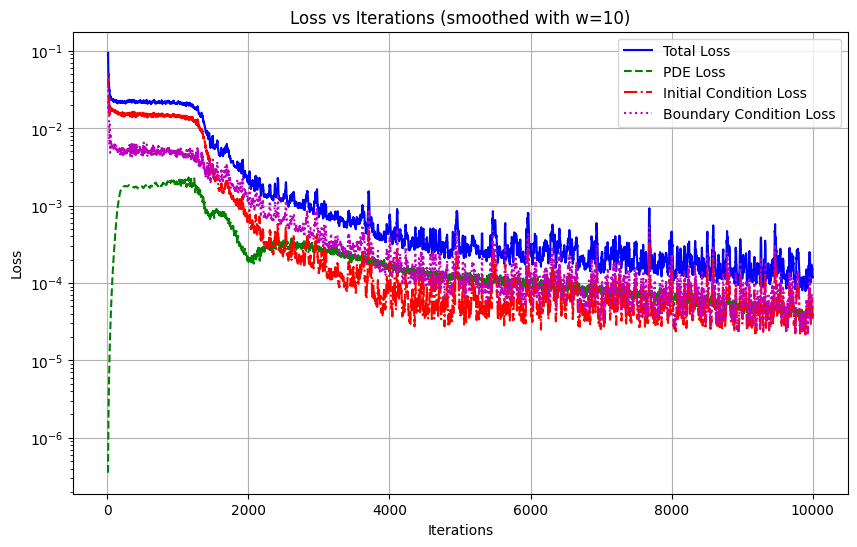

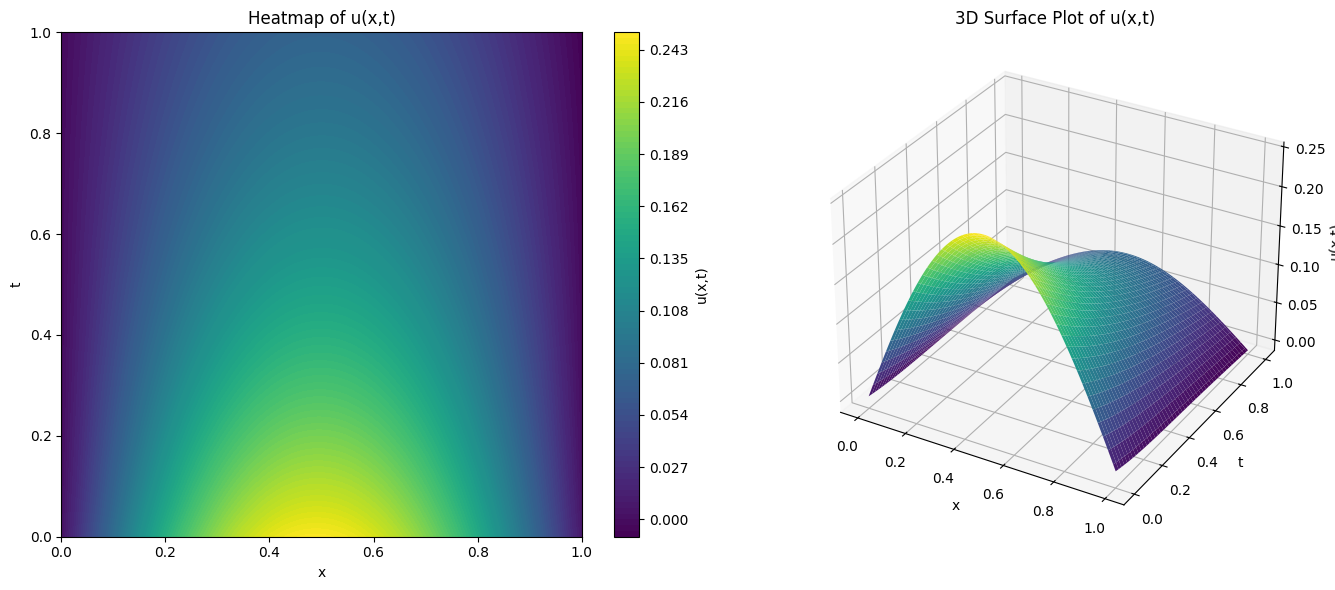

In [36]:
# Plot the losses
plot_losses(total_losses, pde_losses, ic_losses, bc_losses, eval_every)

# Plot the losses
plot_losses(total_losses, pde_losses, ic_losses, bc_losses, eval_every, w=10)

# Plot the solution
plot_solution(model, T, x_max)

## Second setting

We now try a different set of parameters (including the scale of the initial condition) and hyperparameters. We do not change the PDE we want to solve, nor the training method.

In [40]:
# Define the initial condition loss: u(x, 0) = 10x(1 - x)
def initial_condition_loss(model, x):
    t_0 = torch.zeros_like(x)  # Time t=0
    inputs = torch.cat([x, t_0], dim=1)
    u_pred = model(inputs)
    u_true = 10 * x * (1 - x)
    loss_ic = torch.mean((u_pred - u_true)**2)
    return loss_ic

# Parameters
T = 2.0 # time horizon
x_max = 1.0 # largest value of x in the domain
sigma = 0.5 # viscosity coefficient
nu = sigma**2 / 2 # coefficient in the PDE

# Hyperparameters
hidden_size = 200
num_epochs = 10000
batch_size = 4
learning_rate = 1e-1
eval_every = 100

# Train the model
model, total_losses, pde_losses, ic_losses, bc_losses = train_pde_solver(
    T, x_max, nu,
    hidden_size, num_epochs, batch_size, learning_rate, eval_every)

Epoch 0, Total Loss: 1.982795, PDE Loss: 0.000000, IC Loss: 1.974404, BC Loss: 0.008391
Epoch 100, Total Loss: 2.958958, PDE Loss: 0.000000, IC Loss: 2.648967, BC Loss: 0.309991
Epoch 200, Total Loss: 2.321483, PDE Loss: 0.000000, IC Loss: 0.838038, BC Loss: 1.483445
Epoch 300, Total Loss: 2.801891, PDE Loss: 0.000000, IC Loss: 2.129646, BC Loss: 0.672245
Epoch 400, Total Loss: 1.691295, PDE Loss: 0.000000, IC Loss: 0.852508, BC Loss: 0.838788
Epoch 500, Total Loss: 3.537528, PDE Loss: 0.000000, IC Loss: 2.473547, BC Loss: 1.063981
Epoch 600, Total Loss: 2.691648, PDE Loss: 0.000000, IC Loss: 1.055664, BC Loss: 1.635985
Epoch 700, Total Loss: 1.763663, PDE Loss: 0.000000, IC Loss: 1.471635, BC Loss: 0.292028
Epoch 800, Total Loss: 2.783531, PDE Loss: 0.000000, IC Loss: 2.729718, BC Loss: 0.053813
Epoch 900, Total Loss: 1.813787, PDE Loss: 0.000000, IC Loss: 1.518275, BC Loss: 0.295512
Epoch 1000, Total Loss: 2.386716, PDE Loss: 0.000000, IC Loss: 0.211324, BC Loss: 2.175393
Epoch 1100,

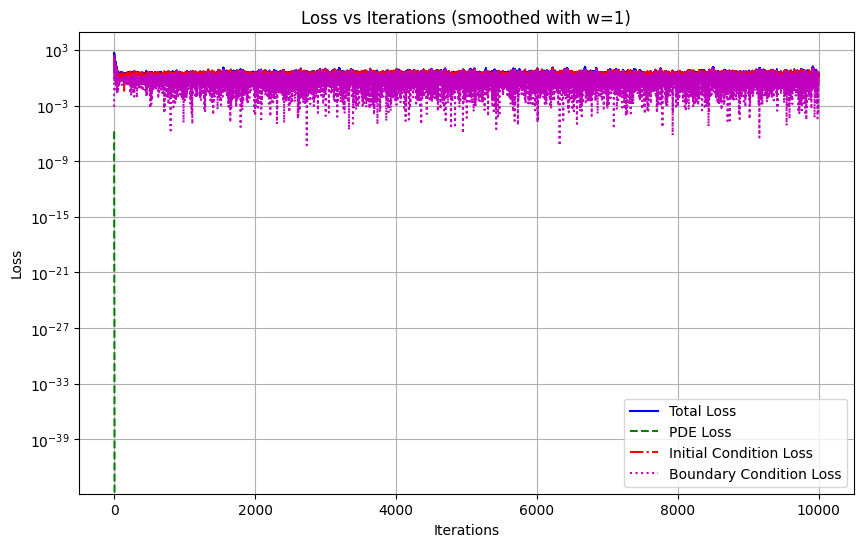

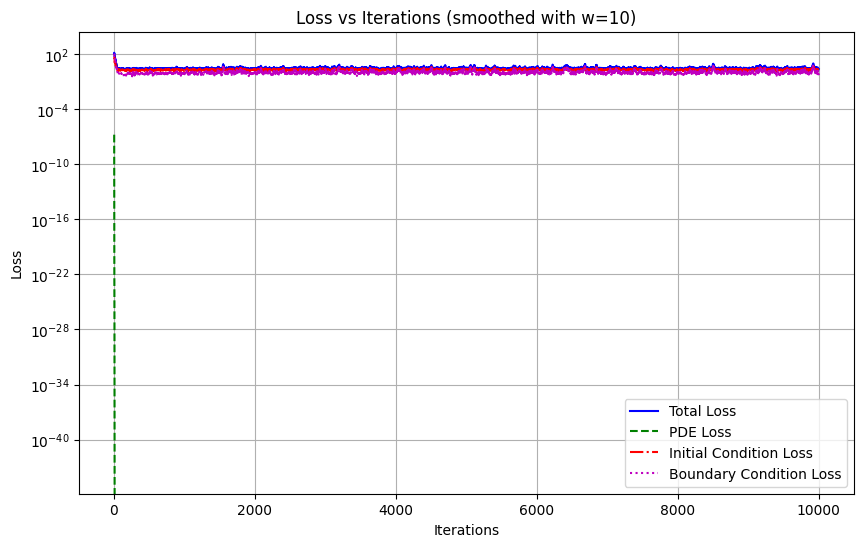

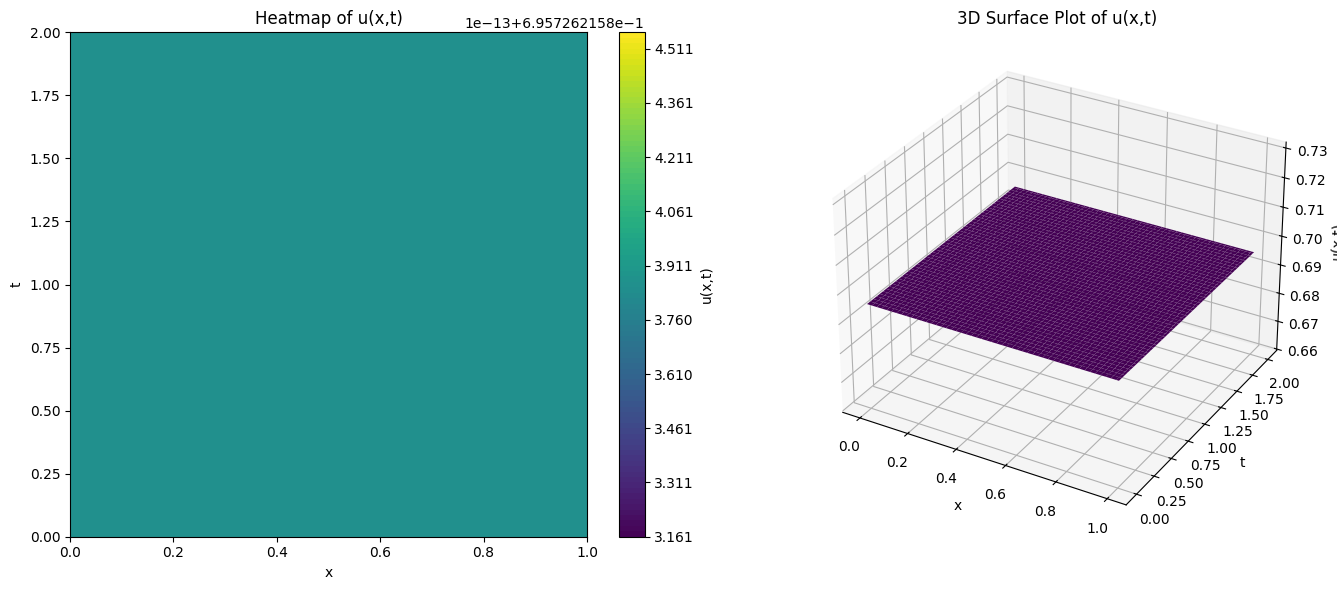

In [38]:
# Plot the losses
plot_losses(total_losses, pde_losses, ic_losses, bc_losses, eval_every)

# Plot the losses
plot_losses(total_losses, pde_losses, ic_losses, bc_losses, eval_every, w=10)

# Plot the solution
plot_solution(model, T, x_max)

Here the training goes wrong: the PDE residual loss goes to $0$ after just a few iterations. But the initial and boundary conditions are not satisfies. the NN fails to find a better approximate solution. Fix it by changing the **hyperparameters (not the parameters).**

In [41]:
# Hyperparameters
hidden_size = 100 #200 before
num_epochs = 10000
batch_size = 150 #4 before
learning_rate = 1e-1

# Train the model
model, total_losses, pde_losses, ic_losses, bc_losses = train_pde_solver(
    T, x_max, nu,
    hidden_size, num_epochs, batch_size, learning_rate, eval_every)

Epoch 0, Total Loss: 3.290220, PDE Loss: 0.000005, IC Loss: 3.275064, BC Loss: 0.015152
Epoch 100, Total Loss: 2.409070, PDE Loss: 0.000000, IC Loss: 1.778831, BC Loss: 0.630238
Epoch 200, Total Loss: 2.298837, PDE Loss: 0.000000, IC Loss: 1.694061, BC Loss: 0.604775
Epoch 300, Total Loss: 2.166647, PDE Loss: 0.000000, IC Loss: 1.620575, BC Loss: 0.546072
Epoch 400, Total Loss: 2.526105, PDE Loss: 0.000000, IC Loss: 1.868227, BC Loss: 0.657879
Epoch 500, Total Loss: 2.228275, PDE Loss: 0.000000, IC Loss: 1.590882, BC Loss: 0.637393
Epoch 600, Total Loss: 2.485066, PDE Loss: 0.000000, IC Loss: 1.847789, BC Loss: 0.637277
Epoch 700, Total Loss: 2.304282, PDE Loss: 0.000000, IC Loss: 1.686757, BC Loss: 0.617525
Epoch 800, Total Loss: 2.412773, PDE Loss: 0.000000, IC Loss: 1.852458, BC Loss: 0.560315
Epoch 900, Total Loss: 2.546339, PDE Loss: 0.000000, IC Loss: 1.918007, BC Loss: 0.628332
Epoch 1000, Total Loss: 2.368526, PDE Loss: 0.000000, IC Loss: 1.746786, BC Loss: 0.621741
Epoch 1100,

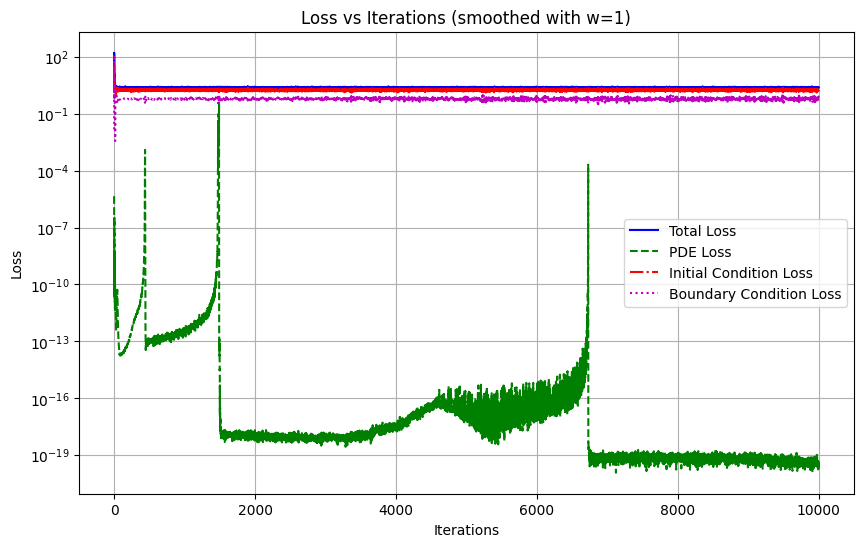

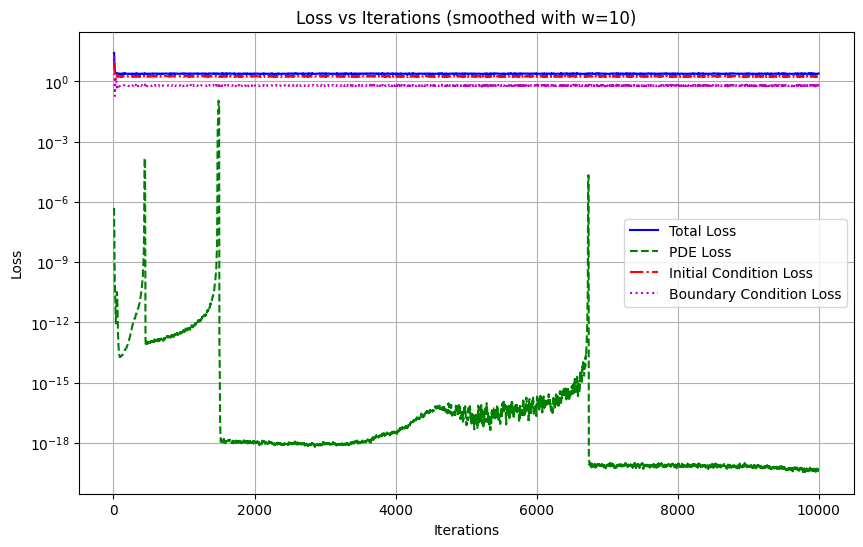

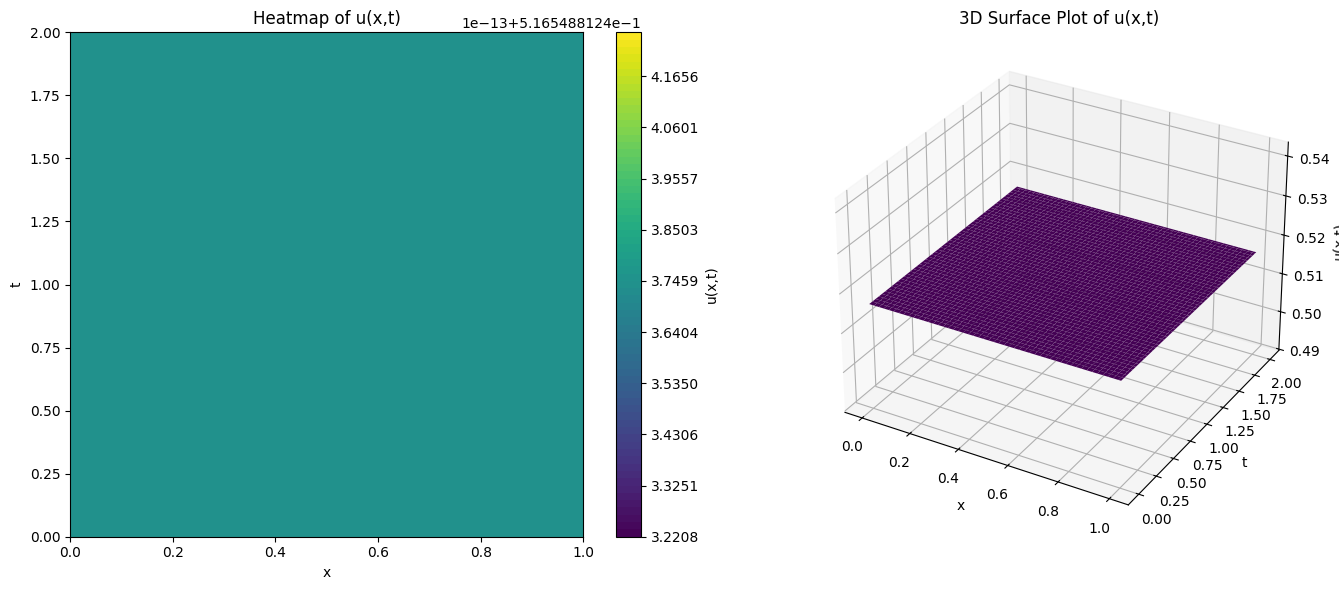

In [42]:
# Plot the losses
plot_losses(total_losses, pde_losses, ic_losses, bc_losses, eval_every)

# Plot the losses
plot_losses(total_losses, pde_losses, ic_losses, bc_losses, eval_every, w=10)

# Plot the solution
plot_solution(model, T, x_max)

## Bonus: Test set

Include a testing set and evaluate the loss every few iterations.

Epoch 0: Train loss = 2.885374, Test loss = 169.862656
Epoch 100: Train loss = 2.289028, Test loss = 2.463933
Epoch 200: Train loss = 2.410261, Test loss = 2.463823
Epoch 300: Train loss = 2.353479, Test loss = 2.464315
Epoch 400: Train loss = 2.332665, Test loss = 2.463856
Epoch 500: Train loss = 2.345261, Test loss = 2.471185
Epoch 600: Train loss = 2.399397, Test loss = 2.469561
Epoch 700: Train loss = 2.256278, Test loss = 2.463877
Epoch 800: Train loss = 2.465016, Test loss = 2.463941
Epoch 900: Train loss = 2.415882, Test loss = 2.465451
Epoch 1000: Train loss = 2.316664, Test loss = 2.464085
Epoch 1100: Train loss = 2.358906, Test loss = 2.489232
Epoch 1200: Train loss = 2.376000, Test loss = 2.463953
Epoch 1300: Train loss = 2.208649, Test loss = 2.467920
Epoch 1400: Train loss = 2.350103, Test loss = 2.463863
Epoch 1500: Train loss = 2.344870, Test loss = 2.465110
Epoch 1600: Train loss = 2.392575, Test loss = 2.463847
Epoch 1700: Train loss = 2.634684, Test loss = 2.463813
Ep

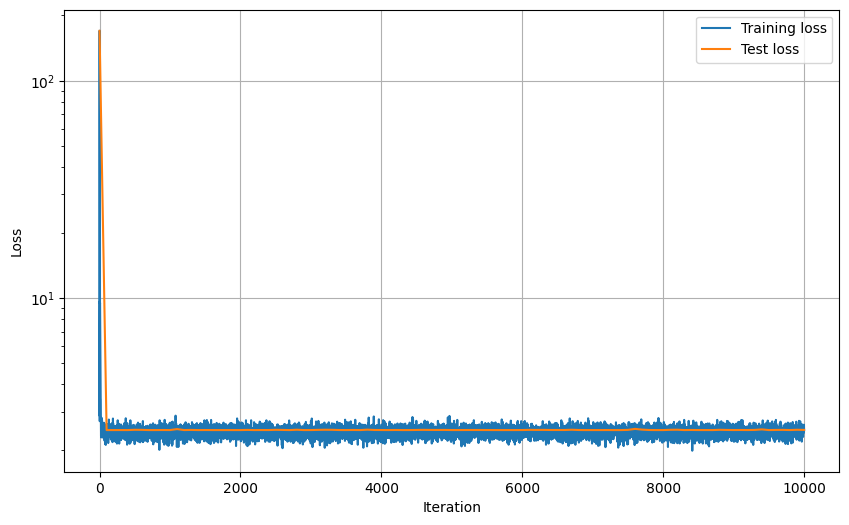

In [43]:
def train_pde_solver_test(t_max, x_max, nu, hidden_size, num_epochs, batch_size, learning_rate, eval_every=100):
    model = NeuralNet(hidden_size)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    total_losses, pde_losses, ic_losses, bc_losses = [], [], [], []
    test_losses, test_epochs = [], []

    # Fixed test points
    x_test = x_max * torch.rand(1000, 1)
    t_test = t_max * torch.rand(1000, 1)

    for epoch in range(num_epochs):
        model.train()

        x_batch = x_max * torch.rand(batch_size, 1)
        t_batch = t_max * torch.rand(batch_size, 1)

        loss_pde = torch.mean(pde_residual(model, nu, x_batch, t_batch) ** 2)
        loss_ic = initial_condition_loss(model, x_batch)
        loss_bc = boundary_condition_loss(model, t_batch)
        loss = loss_pde + loss_ic + loss_bc

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_losses.append(loss.item())
        pde_losses.append(loss_pde.item())
        ic_losses.append(loss_ic.item())
        bc_losses.append(loss_bc.item())

        if epoch % eval_every == 0 or epoch == num_epochs - 1:
            model.eval()

            # Derivatives are needed here: don't use torch.no_grad()
            test_pde = torch.mean(pde_residual(model, nu, x_test, t_test) ** 2)
            test_ic = initial_condition_loss(model, x_test)
            test_bc = boundary_condition_loss(model, t_test)

            test_loss = (test_pde + test_ic + test_bc).item()
            test_losses.append(test_loss)
            test_epochs.append(epoch)

            print(f"Epoch {epoch}: "
                f"Train loss = {loss.item():.6f}, "
                f"Test loss = {test_loss:.6f}")

    return (model, total_losses, pde_losses, ic_losses, bc_losses, test_losses, test_epochs)


# Train a new model using your current hyperparameters
set_seed(42)

(model, total_losses, pde_losses, ic_losses, bc_losses,test_losses, test_epochs) = train_pde_solver_test(T, x_max, nu, hidden_size, num_epochs,batch_size, learning_rate, eval_every)

# Compare training and test losses
plt.figure(figsize=(10, 6))
plt.semilogy(total_losses, label="Training loss")
plt.semilogy(test_epochs, test_losses, label="Test loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

## Bonus: Robustness

Repeat the experiments over several seeds; plot the mean and standard deviation of the training and testing loss.

In [45]:
seeds = [0, 1, 2]
all_train_losses = []
all_test_losses = []

for seed in seeds:
    print(f"\nSeed {seed}")
    set_seed(seed)

    (_, train_losses, _, _, _,
     test_losses, test_epochs) = train_pde_solver_test(
        T, x_max, nu, hidden_size, num_epochs,
        batch_size, learning_rate, eval_every
    )

    all_train_losses.append(train_losses)
    all_test_losses.append(test_losses)

# Rows = seeds; columns = iterations
all_train_losses = np.array(all_train_losses)
all_test_losses = np.array(all_test_losses)

train_mean = all_train_losses.mean(axis=0)
train_std = all_train_losses.std(axis=0)
test_mean = all_test_losses.mean(axis=0)
test_std = all_test_losses.std(axis=0)

# Plot mean curves with ±1 standard deviation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, steps, mean, std, title in [
    (axes[0], np.arange(num_epochs),
     train_mean, train_std, "Training loss"),
    (axes[1], np.array(test_epochs),
     test_mean, test_std, "Testing loss"),
]:
    ax.plot(steps, mean, label="Mean")
    ax.fill_between(
        steps, mean - std, mean + std,
        alpha=0.25, label="±1 standard deviation"
    )
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Loss")
    ax.set_title(title)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()


Seed 0
Epoch 0: Train loss = 3.876287, Test loss = 162.377213
Epoch 100: Train loss = 2.255499, Test loss = 2.356595
Epoch 200: Train loss = 2.397295, Test loss = 2.357116
Epoch 300: Train loss = 2.528424, Test loss = 2.356467
Epoch 400: Train loss = 2.431970, Test loss = 2.356834
Epoch 500: Train loss = 2.566253, Test loss = 2.356622
Epoch 600: Train loss = 2.341705, Test loss = 2.357970
Epoch 700: Train loss = 2.662787, Test loss = 2.357997
Epoch 800: Train loss = 2.560375, Test loss = 2.356666
Epoch 900: Train loss = 2.461823, Test loss = 2.357221
Epoch 1000: Train loss = 2.408195, Test loss = 2.356755
Epoch 1100: Train loss = 2.477810, Test loss = 2.356995
Epoch 1200: Train loss = 2.210447, Test loss = 2.357078
Epoch 1300: Train loss = 2.306922, Test loss = 2.356587
Epoch 1400: Train loss = 2.280988, Test loss = 2.357230
Epoch 1500: Train loss = 2.387727, Test loss = 2.356786
Epoch 1600: Train loss = 2.434326, Test loss = 2.356864
Epoch 1700: Train loss = 2.489748, Test loss = 2.3

KeyboardInterrupt: 

## Bonus: Comparison with finite difference solution

Compare with the solution obtained by finite difference code (see Recitation 1).

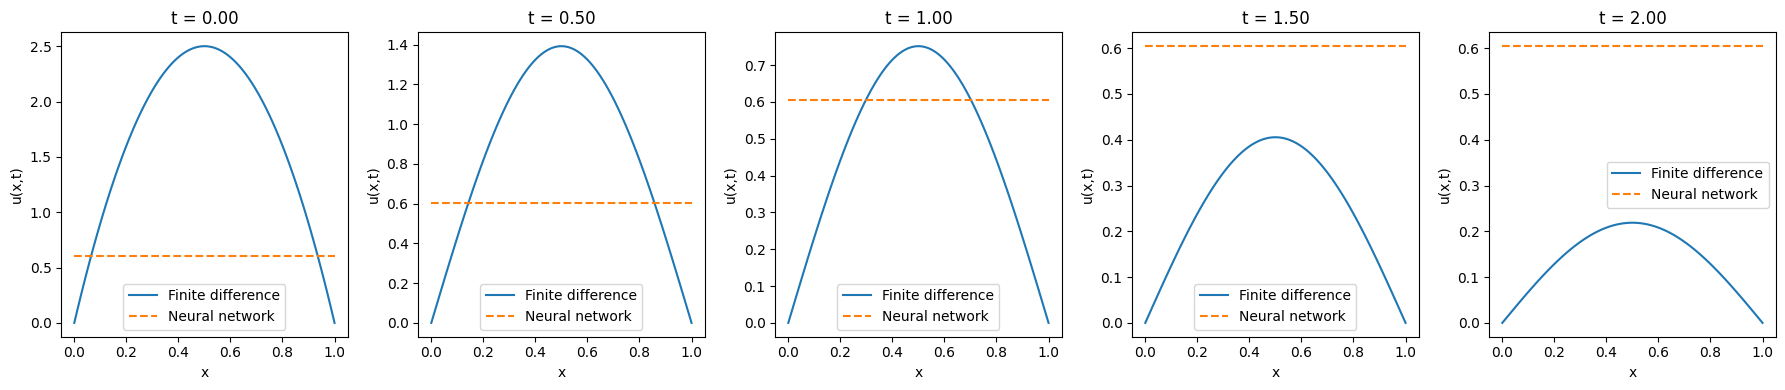

RMSE against finite differences at plotted times: 0.688164


In [46]:
# Finite difference grid
nx = 101
x_fd = np.linspace(0, x_max, nx)
dx = x_fd[1] - x_fd[0]

# Choose a stable time step: nu * dt / dx² <= 0.5
nt = int(np.ceil(T / (0.4 * dx**2 / nu)))
dt = T / nt
t_fd = np.linspace(0, T, nt + 1)
alpha = nu * dt / dx**2

# Initial and boundary conditions, matching the trained NN
u_fd = np.zeros((nt + 1, nx))
u_fd[0] = 10 * x_fd * (1 - x_fd)

# Explicit Euler updates; endpoints remain zero
for n in range(nt):
    u_fd[n + 1, 1:-1] = (
        u_fd[n, 1:-1]
        + alpha * (
            u_fd[n, 2:]
            - 2 * u_fd[n, 1:-1]
            + u_fd[n, :-2]
        )
    )

# Compare at five times, including the initial and final times
indices = np.linspace(0, nt, 5, dtype=int)
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

parameter = next(model.parameters())
model.eval()
errors = []

for ax, index in zip(axes, indices):
    time = t_fd[index]

    inputs = torch.tensor(
        np.column_stack([x_fd, np.full_like(x_fd, time)]),
        dtype=parameter.dtype,
        device=parameter.device
    )

    with torch.no_grad():
        u_nn = model(inputs).cpu().numpy().ravel()

    errors.append(u_nn - u_fd[index])

    ax.plot(x_fd, u_fd[index], label="Finite difference")
    ax.plot(x_fd, u_nn, "--", label="Neural network")
    ax.set_title(f"t = {time:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("u(x,t)")
    ax.legend()

plt.tight_layout()
plt.show()

rmse = np.sqrt(np.mean(np.array(errors)**2))
print(f"RMSE against finite differences at plotted times: {rmse:.6f}")